# Asistente VAR que sabe cuándo dudar

### Tipo de falta y sanción a partir de varias cámaras, con redes de video preentrenadas (SoccerNet-MVFoul)

**Matías Martínez Moreno**

---

## La idea

En una revisión VAR el árbitro mira la misma jugada desde varias cámaras (la toma en vivo y una o más repeticiones) y decide dos cosas: **qué tipo de falta fue** y **qué sanción merece**. Este notebook entrena un modelo que hace lo mismo con los clips de **SoccerNet-MVFoul**, un dataset de 3 901 jugadas de ligas europeas anotadas por un árbitro profesional.

- **Entrada:** de 2 a 4 clips de la misma jugada, de 16 fotogramas cada uno alrededor del contacto.
- **Salida:** tipo de falta (8 clases), sanción (sin falta, falta sin tarjeta, amarilla o roja) y qué tan seguro está el modelo.

El punto de partida es **VARS** (Held et al., 2023 y 2024), el modelo publicado por los creadores del dataset: un MViT-V2-S afinado sobre estas jugadas. Su paper reporta **37,5 %** de exactitud balanceada combinada en el test.

## Qué se busca

El trabajo se organiza en tres preguntas:

1. **Verificar el punto de partida.** ¿Se sostiene la cifra de VARS? Se cargan sus pesos públicos y se evalúa sobre las mismas jugadas y con la métrica oficial de SoccerNet, para tener una referencia justa contra la cual comparar.
2. **Ver si se puede aportar algo con transferencia.** Con el cómputo de una sesión gratuita de Kaggle (2 GPU T4, máximo 12 h):
   - **qué red preentrenada usar:** MViT-V2-S de Kinetics, el mismo MViT con los pesos de VARS (transferencia en dos saltos: Kinetics → faltas → modelo final) y **Hiera-B+**, una red más reciente y más fuerte en Kinetics;
   - **cuánto afinarla:** congelada, ajuste parcial o ajuste completo;
   - **qué partes de la cabeza sirven:** una escalera de ablación que agrega un componente a la vez (cómo unir las cámaras, aumento de datos, atributos del árbitro, jugadas dudosas);
   - **una técnica del ganador del reto SoccerNet 2025:** reentrenar la cabeza sobre características de la red ya afinada.
3. **Saber cuándo confiar en el modelo.** Calibración de la confianza, abstención (responder solo cuando está seguro), si duda en las jugadas donde dudó el árbitro y a qué cámara le hace caso.

## Resultado en breve

Corrida completa en Kaggle: **6,4 h en 2 × T4**, sin errores.

| Modelo | BA combinada en el test (IC 95 %) | BA tipo de falta | BA sanción |
|---|---|---|---|
| VARS, cifra del paper (2024) | 37,5 | 41,0 | 34,0 |
| VARS con sus pesos, evaluado aquí | **39,9** (33,2 – 47,4) | 43,9 | 35,9 |
| **Mejor modelo de este trabajo: Hiera-B+ afinado + segunda etapa** | **39,8** (34,4 – 45,7) | 41,2 | **38,3** |

- **Verificación:** con sus propios pesos VARS da 39,9, algo más que lo publicado. Esa es la referencia para comparar.
- **Empate con VARS.** La diferencia está entre −8,6 y +8,1 puntos. Con 251 jugadas y solo 5 rojas en el test, no se puede demostrar ninguna diferencia menor de unos 8 puntos.
- **Mejor en la sanción** (exactitud 51,4 % contra 36,3 %) y **peor en el tipo de falta** (47,0 % contra 55,0 %).
- **Lo que más aportó:** afinar la red (+2 a +4,5 puntos), partir de una red que ya vio faltas (VARS congelado 36,1 contra Kinetics congelado 31,0) y la segunda etapa en Hiera (35,3 → 39,8).
- **Saber cuándo dudar:** si el modelo responde solo en el 68 % de las jugadas donde está más seguro, la exactitud de la sanción sube de 51,4 % a 59,1 %.
- **Lo que no funcionó:** la sanción ordinal, los atributos del árbitro como tareas extra y detectar las jugadas dudosas (AUROC 0,44, igual que el azar).

## Cómo leer las cifras

- **BA (exactitud balanceada):** el promedio del acierto de cada clase. Acertar las 5 rojas vale lo mismo que acertar las 157 faltas sin tarjeta.
- **BA combinada:** el promedio de la BA del tipo de falta y la de la sanción. Es la métrica oficial del reto de SoccerNet.
- **Congelado / ajuste parcial / ajuste completo:** la red preentrenada no se toca / se reentrenan sus últimas capas / se reentrena toda.
- **Valid y test:** con *valid* se toman las decisiones (época, umbrales, ensamble); el *test* se mira una sola vez al final.
- **+τ:** el resultado después de corregir las probabilidades por la frecuencia de cada clase (sección 6).
- **IC 95 %:** el rango donde probablemente está el valor real, calculado remuestreando las jugadas del test 2 000 veces.

## Datos y créditos

- **Dataset:** SoccerNet-MVFoul, creado por Jan Held, Anthony Cioppa, Silvio Giancola, Abdullah Hamdi, Bernard Ghanem y Marc Van Droogenbroeck (Universidad de Lieja y KAUST) y presentado junto con VARS en el CVPR Workshops 2023. Hace parte de la iniciativa [SoccerNet](https://www.soccer-net.org/) y se usa en su reto anual de reconocimiento de faltas.
- **Acceso:** los videos están protegidos por un acuerdo de confidencialidad (NDA) que se firma con SoccerNet. Por eso este notebook **no incluye ni comparte ningún video**: los descarga en la sesión de Kaggle con la contraseña de cada usuario y los borra al terminar.
- **Código y pesos de VARS:** repositorio oficial [SoccerNet/sn-mvfoul](https://github.com/SoccerNet/sn-mvfoul). La sección 8 copia la parte mínima de su código para poder cargar sus pesos.
- Las referencias completas de cada paper están al final del notebook.

## Cómo correrlo en Kaggle

No hay que tocar el código.
1. *Settings → Accelerator:* **GPU T4 x2**. *Settings → Internet:* **On**.
2. *Add-ons → Secrets:* `SOCCERNET_PASSWORD` con la contraseña del NDA de SoccerNet, activado para este notebook.
3. *Save Version → Save & Run All.* Los resultados quedan en la pestaña *Output*, carpeta `outputs/`.

## Cómo está organizado

- **Parte I (secciones 0 a 9): herramientas.** Funciones y clases, cada bloque con una explicación corta de los conceptos que usa. Aquí no se entrena nada.
- **Parte II (secciones 10 a 21): ejecución.** Datos, prueba de humo, experimentos, gráficas y, después de cada resultado, una celda **Lectura** que explica qué muestra.

Antes del entrenamiento largo hay una **prueba de humo** que corre todo el flujo con pocas jugadas, para que un error aparezca en los primeros minutos y no a las 5 horas. Los títulos que imprime cada fase en las salidas tienen su propia numeración interna; la que sirve para orientarse es la de los encabezados.

# Parte I · Herramientas

## 0. Configuración

Todos los parámetros importantes están en `CFG`. El reloj de seguridad deja de entrenar a las 11 h menos una reserva de 35 min, para que siempre alcance el tiempo de ensamblar, evaluar y guardar; Kaggle da 12 h por sesión.

In [1]:
# ============================================================
# 0. Librerías, configuración y utilidades generales
# ============================================================
import os, sys, time, json, math, random, shutil, pickle, struct, hashlib, zlib, re, gc, copy, warnings, traceback, subprocess
from pathlib import Path
from contextlib import contextmanager
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from IPython.display import display

warnings.filterwarnings('ignore')
T0 = time.time()                     # inicio de la corrida (lo usa el reloj de seguridad)

CFG = dict(
    semilla=42,
    limite_horas=11.0,               # reloj de seguridad (Kaggle corta a las 12 h)
    reserva_min=35,                  # minutos que siempre se guardan para ensamble, test y guardado
    hf_repo='SoccerNet/SN-MVFouls-2024',
    splits=['train', 'valid', 'test'],
    secreto='SOCCERNET_PASSWORD',
    n_folds=5,
    jpeg_calidad=88,
    # Extracción de características: pasadas aumentadas máximas, minutos disponibles y tamaño de lote (para 2 GPU)
    K_max={'mvit': 2, 'mvit_vars': 2, 'hiera': 2},
    presupuesto={'mvit': 18, 'mvit_vars': 18, 'hiera': 30},
    lote_extraccion={'mvit': 32, 'mvit_vars': 32, 'hiera': 16, 'r2plus1d': 32},
    # Cabeza multivista (se entrena sobre características guardadas)
    cabeza=dict(d=256, epocas=40, lr=5e-4, wd=0.05, lote=64, paciencia=10, drop=0.3,
                lam_aux=0.3, p_quitar_vista=0.3),
    semillas_cabeza=(0, 1, 2),       # las cabezas del protocolo oficial se promedian sobre 3 semillas
    # Ajuste fino (minutos máximos, tasas de aprendizaje y épocas máximas)
    ajuste=dict(min_vars=140, lr_vars=1e-5, epocas_vars=14,
                min_hiera=150, lr_hiera=5e-5, epocas_hiera=12, bloques_hiera=12,
                min_mvit=140, lr_mvit=3e-5, epocas_mvit=14,
                lr_cabeza=1e-4, lote=8, lote_efectivo=16, paciencia=3),
    K_etapa2=3,                      # pasadas aumentadas en la segunda etapa
    # Pesos públicos de VARS (repositorio oficial sn-mvfoul, archivo 14_model.pth.tar)
    vars_url='https://drive.usercontent.google.com/download?id=19UnRAtGYFVWhwBfuX6GtWi2HWIpK6Ce1&export=download&confirm=t',
    bootstrap=2000,
)

# Resultados publicados por VARS 2024 (MViT + atención) en el test oficial, en %
VARS_PAPER = dict(acc_act=50.0, ba_act=41.0, acc_sev=46.0, ba_sev=34.0, lb=37.5)

# ---------- Carpetas ----------
EN_KAGGLE = Path('/kaggle/working').exists()
WORK = Path('/kaggle/working') if EN_KAGGLE else Path.cwd()
OUT, FIG, TAB = WORK / 'outputs', WORK / 'outputs' / 'figuras', WORK / 'outputs' / 'tablas'
for p in (OUT, FIG, TAB):
    p.mkdir(parents=True, exist_ok=True)

def libre_gb(p):
    try:
        return shutil.disk_usage(p).free / 1e9
    except Exception:
        return 0.0

# Videos, fotogramas y características van fuera de /kaggle/working: lo que queda ahí se publica
# como output del notebook y el NDA de SoccerNet no permite compartir los videos.
_cands = [p for p in (Path('/kaggle/temp'), Path('/tmp')) if p.exists()]
_base = max(_cands, key=libre_gb) if _cands else WORK
if libre_gb(_base) < 15 and libre_gb(WORK) > libre_gb(_base) + 5:
    _base = WORK                     # último recurso; se borra al final
TMP = _base / 'mvfoul_tmp'
TMP_EN_OUTPUTS = str(TMP).startswith(str(WORK))
ZIPS, VIDEOS, CACHE, FEATS, ANOT = (TMP / n for n in ('zips', 'videos', 'fotogramas', 'features', 'anotaciones'))
for p in (ZIPS, VIDEOS, CACHE, FEATS, ANOT):
    p.mkdir(parents=True, exist_ok=True)

# ---------- Hardware ----------
DEV = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
N_GPU = torch.cuda.device_count()
NUM_WORKERS = min(4, os.cpu_count() or 2)
PREFETCH = 2
torch.backends.cudnn.benchmark = True
H0, W0 = 224, 398                    # tamaño de los clips de 224p (alto, ancho)
NV = 4                               # máximo de cámaras por jugada

def fijar_semilla(s):
    s = int(s)
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

fijar_semilla(CFG['semilla'])

# ---------- Reloj y registro de fases ----------
def minutos():
    return (time.time() - T0) / 60

def quedan_min():
    return CFG['limite_horas'] * 60 - minutos()

def hay_tiempo(necesario_min):
    return quedan_min() - CFG['reserva_min'] >= necesario_min

class SinTiempo(Exception):
    pass

REPORTE = {'fases': {}, 'avisos': [], 'entorno': {}}
RES = {}                             # resultados de cada experimento
ACTIVO = dict(hiera=True, vars=True, ajuste=True, gradcam=True)

def _a_json(o):
    if isinstance(o, np.integer): return int(o)
    if isinstance(o, np.floating): return float(o)
    if isinstance(o, np.ndarray): return o.tolist()
    return str(o)

def guardar_json(obj, ruta):
    with open(ruta, 'w', encoding='utf-8') as f:
        json.dump(obj, f, ensure_ascii=False, indent=1, default=_a_json)

def aviso(msg):
    print('AVISO:', msg)
    REPORTE['avisos'].append(msg)

@contextmanager
def fase(nombre, opcional=False):
    """Mide el tiempo de cada fase. Si una fase opcional falla, se registra y el notebook sigue."""
    t = time.time()
    print(f'\n{"=" * 78}\n{nombre}   (minuto {minutos():.0f}, quedan {quedan_min():.0f} min)\n{"=" * 78}')
    try:
        yield
    except Exception as e:
        REPORTE['fases'][nombre] = {'min': (time.time() - t) / 60, 'ok': False, 'error': f'{type(e).__name__}: {e}'}
        guardar_json(REPORTE, OUT / 'reporte_corrida.json')
        if not opcional:
            raise
        traceback.print_exc()
        aviso(f'La fase "{nombre}" no se completó: {type(e).__name__}: {e}')
        return
    REPORTE['fases'][nombre] = {'min': (time.time() - t) / 60, 'ok': True}
    guardar_json(REPORTE, OUT / 'reporte_corrida.json')

# ---------- Estilo de las gráficas ----------
COL = dict(azul='#1d4e89', celeste='#3c91e6', naranja='#f18f01', rojo='#c0392b',
           verde='#2e8b57', morado='#6c4f9b', gris='#8a8a8a', amarillo='#e1b12c')
PALETA = [COL[k] for k in ('azul', 'naranja', 'verde', 'rojo', 'morado', 'celeste', 'amarillo', 'gris')]
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 150, 'font.size': 10, 'axes.titlesize': 12, 'axes.titleweight': 'bold',
    'axes.labelsize': 10, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
    'grid.alpha': 0.25, 'grid.linestyle': '-', 'legend.frameon': False, 'axes.prop_cycle': plt.cycler(color=PALETA),
})

def guardar_fig(fig, nombre):
    fig.savefig(FIG / f'{nombre}.png', bbox_inches='tight')
    plt.show()
    plt.close(fig)

def etiquetar_barras(ax, barras, fmt='{:.1f}', dy=0.6, size=8.5):
    for b in barras:
        h = b.get_height()
        if np.isfinite(h):
            ax.text(b.get_x() + b.get_width() / 2, h + dy, fmt.format(h), ha='center', va='bottom', fontsize=size)

print(f'Carpeta temporal: {TMP} ({libre_gb(TMP):.0f} GB libres) | GPU: {N_GPU} | CPU: {os.cpu_count()}')

Carpeta temporal: /tmp/mvfoul_tmp (1126 GB libres) | GPU: 2 | CPU: 4


## 1. Entorno

Revisa que estén activas la GPU, Internet y la contraseña. Si falta algo, se detiene con un mensaje que dice qué activar. La contraseña nunca se escribe en el código: se lee de *Kaggle Secrets*.

In [2]:
def leer_clave():
    clave = None
    try:
        from kaggle_secrets import UserSecretsClient
        clave = UserSecretsClient().get_secret(CFG['secreto'])
    except Exception:
        pass
    clave = clave or os.environ.get(CFG['secreto'])
    if not clave:
        raise RuntimeError('Falta la contraseña de SoccerNet. En Add-ons → Secrets crea "SOCCERNET_PASSWORD" '
                           'con la contraseña del NDA y activa el interruptor para este notebook.')
    return clave.strip()

def instalar(paquete):
    r = subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', paquete], capture_output=True, text=True)
    return r.returncode == 0

## 2. Datos y etiquetas

**De dónde salen.** La librería oficial de SoccerNet ahora baja este dataset de Hugging Face (`SoccerNet/SN-MVFouls-2024`). Los zip son públicos pero vienen **cifrados con AES**: la contraseña del NDA es la que los abre. A 224p pesan 3,1 GB en total.

**Etiquetas oficiales.** La métrica oficial no usa todas las jugadas. Descarta las que no tienen tipo de falta y las de **zona gris**, donde el árbitro anotó que dos decisiones eran igual de válidas: «entre falta y no falta», «límite sin tarjeta / amarilla» o «límite amarilla / roja». La sanción queda en 4 clases: *sin falta, falta sin tarjeta, amarilla, roja*. Ese filtro se replica línea por línea para comparar con VARS en igualdad de condiciones.

**Lo que se agrega aquí:**
- **Zona gris:** en lugar de botar esas jugadas, se usan en el entrenamiento como **etiquetas suaves**. Por ejemplo, «límite sin tarjeta / amarilla» se vuelve 50 % y 50 %.
- **Atributos del árbitro:** se usan 6 atributos anotados como tareas auxiliares: contacto, parte del cuerpo, brazo u hombro, intento de jugar el balón, toque de balón y varias faltas.

In [3]:
import requests

ACCIONES = ['Tackling', 'Standing tackling', 'High leg', 'Holding', 'Pushing', 'Elbowing', 'Challenge', 'Dive']
ACC_ES = ['Entrada', 'Entrada de pie', 'Pierna alta', 'Agarrón', 'Empujón', 'Codazo', 'Disputa', 'Simulación']
SEV_ES = ['Sin falta', 'Sin tarjeta', 'Amarilla', 'Roja']
CAMARAS = {'Main camera center': 0, 'Close-up player or field referee': 1,
           'Close-up behind the goal': 2, 'Main behind the goal': 3}          # el resto → 4
CAM_ES = ['Principal (en vivo)', 'Primer plano jugador/árbitro', 'Primer plano detrás del arco',
          'Principal detrás del arco', 'Otra']
# Atributos anotados por el árbitro que usamos como tareas auxiliares: nombre → (campo del json, clases)
AUX = {
    'contacto':      ('Contact', {'Without contact': 0, 'With contact': 1}),
    'parte_cuerpo':  ('Bodypart', {'Upper body': 0, 'Under body': 1}),
    'brazo_hombro':  ('Upper body part', {'Use of arms': 0, 'Use of shoulder': 1, 'Use of shoulders': 1}),
    'intento_jugar': ('Try to play', {'No': 0, 'Yes': 1}),
    'toca_balon':    ('Touch ball', {'No': 0, 'Yes': 1, 'Maybe': 2}),
    'varias_faltas': ('Multiple fouls', {'No': 0, 'Yes': 1, 'yes': 1}),
}
AUX_N = {k: max(m.values()) + 1 for k, (_, m) in AUX.items()}

# ---------------- Descarga y descompresión ----------------
def tamanos_hf(repo):
    try:
        r = requests.get(f'https://huggingface.co/api/datasets/{repo}/tree/main', timeout=30)
        r.raise_for_status()
        return {x['path']: x.get('size') for x in r.json() if x.get('type') == 'file'}
    except Exception as e:
        aviso(f'No se pudo leer el tamaño de los archivos en Hugging Face ({e})')
        return {}

def descargar(url, destino, tam_esperado=None, intentos=8):
    """Descarga con reanudación: si se corta, sigue desde el último byte."""
    destino = Path(destino)
    destino.parent.mkdir(parents=True, exist_ok=True)
    for intento in range(intentos):
        hecho = destino.stat().st_size if destino.exists() else 0
        if tam_esperado and hecho == tam_esperado:
            return destino
        cab = {'Range': f'bytes={hecho}-'} if hecho else {}
        try:
            with requests.get(url, headers=cab, stream=True, timeout=60) as r:
                if r.status_code == 416:
                    return destino
                r.raise_for_status()
                modo = 'ab' if (hecho and r.status_code == 206) else 'wb'
                with open(destino, modo) as f:
                    for trozo in r.iter_content(chunk_size=8 << 20):
                        f.write(trozo)
            if not tam_esperado:
                return destino
        except Exception as e:
            print(f'  intento {intento + 1} falló: {e}')
            time.sleep(5)
    if tam_esperado and destino.stat().st_size != tam_esperado:
        raise RuntimeError(f'La descarga de {destino.name} quedó incompleta.')
    return destino

def _extraer_aes_manual(zip_path, destino, clave):
    """Plan B si pyzipper no se instala: descifra WinZip-AES con la librería cryptography."""
    import zipfile
    from cryptography.hazmat.primitives.ciphers import Cipher, algorithms, modes
    with zipfile.ZipFile(zip_path) as zf, open(zip_path, 'rb') as fh:
        for info in zf.infolist():
            if info.is_dir():
                continue
            fh.seek(info.header_offset)
            cab = fh.read(30)
            nlen, elen = struct.unpack('<HH', cab[26:30])
            extra = fh.read(nlen + elen)[nlen:]
            metodo, fuerza, q = info.compress_type, 1, 0
            while q + 4 <= len(extra):
                hid, hsz = struct.unpack('<HH', extra[q:q + 4])
                if hid == 0x9901:                         # campo extra de AES: fuerza y método real
                    fuerza = extra[q + 8]
                    metodo = struct.unpack('<H', extra[q + 9:q + 11])[0]
                q += 4 + hsz
            datos = fh.read(info.compress_size)
            if info.compress_type == 99:
                ls, lk = {1: 8, 2: 12, 3: 16}[fuerza], {1: 16, 2: 24, 3: 32}[fuerza]
                sal, ver, cuerpo = datos[:ls], datos[ls:ls + 2], datos[ls + 2:-10]
                dk = hashlib.pbkdf2_hmac('sha1', clave.encode(), sal, 1000, 2 * lk + 2)
                if dk[-2:] != ver:
                    raise RuntimeError('La contraseña no abre los zip de SoccerNet.')
                n = (len(cuerpo) + 15) // 16
                ctr = np.zeros((n, 16), np.uint8)       # contador little-endian que empieza en 1 (WinZip AES)
                ctr[:, :8] = np.arange(1, n + 1, dtype='<u8').view(np.uint8).reshape(n, 8)
                flujo = Cipher(algorithms.AES(dk[:lk]), modes.ECB()).encryptor().update(ctr.tobytes())
                datos = (np.frombuffer(cuerpo, np.uint8) ^ np.frombuffer(flujo, np.uint8)[:len(cuerpo)]).tobytes()
            if metodo == 8:
                datos = zlib.decompress(datos, -15)
            salida = destino / info.filename
            salida.parent.mkdir(parents=True, exist_ok=True)
            salida.write_bytes(datos)

def extraer_zip(zip_path, destino, clave):
    destino.mkdir(parents=True, exist_ok=True)
    try:
        import pyzipper
    except ImportError:
        pyzipper = None
    if pyzipper is None:
        _extraer_aes_manual(zip_path, destino, clave)
        return 'AES manual'
    with pyzipper.AESZipFile(zip_path) as zf:
        zf.setpassword(clave.encode())
        try:
            zf.read('annotations.json')
        except RuntimeError as e:
            raise RuntimeError('La contraseña del secret SOCCERNET_PASSWORD no abre los zip de SoccerNet.') from e
        zf.extractall(destino)
    return 'pyzipper'

def preparar_datos(clave):
    tam = tamanos_hf(CFG['hf_repo'])
    carpetas = {}
    for s in CFG['splits']:
        destino = VIDEOS / s
        if not ((destino / 'annotations.json').exists() and any(destino.glob('action_*'))):
            z = ZIPS / f'{s}.zip'
            url = f'https://huggingface.co/datasets/{CFG["hf_repo"]}/resolve/main/{s}.zip'
            t = time.time()
            descargar(url, z, tam.get(f'{s}.zip'))
            print(f'{s}.zip: {z.stat().st_size / 1e9:.2f} GB descargados en {time.time() - t:.0f} s')
            t = time.time()
            metodo = extraer_zip(z, destino, clave)
            print(f'   descomprimido con {metodo} en {time.time() - t:.0f} s')
            z.unlink()
        shutil.copy(destino / 'annotations.json', ANOT / f'{s}.json')
        carpetas[s] = destino
    anots = {s: json.load(open(ANOT / f'{s}.json', encoding='utf-8')) for s in carpetas}
    return carpetas, anots

# ---------------- Etiquetas ----------------
def etiqueta_oficial(a):
    """Mismo filtro y mismas clases que SoccerNet.Evaluation.MV_FoulRecognition. (-1, -1) si la jugada no cuenta."""
    ac, off, sev = a.get('Action class', ''), a.get('Offence', ''), a.get('Severity', '')
    if ac in ('', 'Dont know') or ac not in ACCIONES:
        return -1, -1
    if off in ('', 'Between') and ac != 'Dive':
        return -1, -1
    if sev in ('', '2.0', '4.0') and ac != 'Dive' and off not in ('No offence', 'No Offence'):
        return -1, -1
    if off in ('', 'Between'):
        off = 'Offence'
    if sev in ('', '2.0', '4.0'):
        sev = '1.0'
    if off in ('No offence', 'No Offence'):
        s = 0
    elif off == 'Offence' and sev == '1.0':
        s = 1
    elif off == 'Offence' and sev == '3.0':
        s = 2
    elif off == 'Offence' and sev == '5.0':
        s = 3
    else:
        return -1, -1
    return ACCIONES.index(ac), s

def es_gris(a):
    ac, off, sev = a.get('Action class', ''), a.get('Offence', ''), a.get('Severity', '')
    if ac == 'Dive':
        return False
    return off == 'Between' or (off == 'Offence' and sev in ('2.0', '4.0'))

SEV_MAPA = {'1.0': [0, 1, 0, 0], '2.0': [0, .5, .5, 0], '3.0': [0, 0, 1, 0], '4.0': [0, 0, .5, .5], '5.0': [0, 0, 0, 1]}

def sev_suave(a):
    """Distribución de la sanción: one-hot en las jugadas claras, 50/50 en la zona gris; None si se desconoce."""
    ac, off, sev = a.get('Action class', ''), a.get('Offence', ''), a.get('Severity', '')
    if off in ('No offence', 'No Offence'):
        return [1.0, 0, 0, 0]
    if ac == 'Dive' and off in ('Offence', 'Between', ''):
        return [0, 1.0, 0, 0]                            # regla oficial: la simulación cuenta como falta sin tarjeta
    if off == 'Offence':
        return SEV_MAPA.get(sev)
    if off == 'Between':
        q = SEV_MAPA.get(sev or '1.0', SEV_MAPA['1.0'])
        return [0.5] + [0.5 * v for v in q[1:]]
    return None

def construir_tablas(anots, carpetas):
    filas, clips = [], []
    for split in CFG['splits']:
        acciones = anots[split]['Actions']
        for aid_txt, a in sorted(acciones.items(), key=lambda kv: int(kv[0])):
            aid, gid = int(aid_txt), len(filas)
            y_act_of, y_sev_of = etiqueta_oficial(a)
            ac = a.get('Action class', '')
            # metadatos de cada clip (tipo de cámara y velocidad de la repetición)
            meta = {}
            for j, c in enumerate(a.get('Clips', [])):
                m = re.search(r'clip_(\d+)', c.get('Url', ''))
                meta[int(m.group(1)) if m else j] = c
            mp4s = sorted((carpetas[split] / f'action_{aid}').glob('clip_*.mp4'), key=lambda p: int(p.stem.split('_')[1]))
            cids = []
            for p in mp4s:
                k = int(p.stem.split('_')[1])
                c = meta.get(k, {})
                cam = CAMARAS.get(c.get('Camera type', ''), 4) if c else (0 if k == 0 else 4)
                try:
                    vel = float(c.get('Replay speed', 1.0) or 1.0)
                except (TypeError, ValueError):
                    vel = 1.0
                cid = len(clips)
                clips.append(dict(cid=cid, gid=gid, k=k, ruta=str(p), cam=cam, vel=max(vel, 1.0) if k > 0 else 1.0, vivo=(k == 0)))
                cids.append(cid)
            fila = dict(gid=gid, split=split, aid=aid, partido=a.get('UrlLocal', ''), accion=ac,
                        falta=a.get('Offence', ''), gravedad=a.get('Severity', ''),
                        y_act=ACCIONES.index(ac) if ac in ACCIONES else -1,
                        y_act_of=y_act_of, y_sev_of=y_sev_of, limpia=y_sev_of >= 0, gris=es_gris(a),
                        q_sev=sev_suave(a), clips=cids, n_vistas=len(cids))
            for nombre, (campo, mapa) in AUX.items():
                fila[nombre] = mapa.get(a.get(campo, ''), -1)
            filas.append(fila)
    return pd.DataFrame(filas), pd.DataFrame(clips)

def asignar_folds(acts, k, semilla):
    """Reparte los partidos de train+valid en k grupos, equilibrando rojas, simulaciones y número de jugadas.
    Un partido nunca queda en dos grupos, así no hay fuga entre entrenamiento y validación."""
    pool = acts[acts.split != 'test']
    g = pool.groupby('partido').agg(n=('gid', 'size'), rojas=('y_sev_of', lambda s: int((s == 3).sum())),
                                    sim=('y_act', lambda s: int((s == 7).sum())))
    g = g.sample(frac=1.0, random_state=semilla).sort_values(['rojas', 'sim', 'n'], ascending=False, kind='stable')
    carga = np.zeros((k, 3))
    destino = {}
    for partido, r in g.iterrows():
        f = min(range(k), key=lambda i: (carga[i, 0] if r.rojas > 0 else 0, carga[i, 1] if r.sim > 0 else 0, carga[i, 2]))
        destino[partido] = f
        carga[f] += (r.rojas, r.sim, r.n)
    return acts.partido.map(destino).where(acts.split != 'test', -1).fillna(-1).astype(int).values

## 3. Fotogramas y preprocesamiento

**Qué ve el modelo.** Cada clip dura 5 s (126 fotogramas a 25 fps) y el contacto ocurre cerca del fotograma 75.
- **Ventana A (la de VARS):** 16 fotogramas entre el 63 y el 87, alrededor de un segundo. Es exactamente la regla del código de VARS, y es la que usan el MViT de Kinetics y el de VARS.
- **Ventana C (nueva):** 16 fotogramas cada 3, del 52 al 97, unos 1,8 s. Se parece al muestreo con que se preentrenó Hiera en Kinetics, un fotograma cada ~133 ms. Para Hiera se escoge A o C en validación.

**Caché.** Leer video es lo más lento, así que cada clip se decodifica una sola vez y se guardan en JPEG los fotogramas 50 a 99 (los que cubren las dos ventanas con su corrimiento).

**Recorte.** La red ve un cuadrado central. Para el MViT de VARS se usa el mismo recorte con que se entrenó: lado corto a 256 y recorte de 224, que equivale a un cuadrado de 196 px del cuadro original.

**Aumento de datos.** Para entrenar se aplica un recorte aleatorio, un volteo horizontal (una falta es igual vista en espejo), un cambio leve de brillo, contraste y saturación, y un corrimiento temporal de ±2 fotogramas. Todo se hace en la GPU, con los mismos parámetros para los 16 fotogramas de un clip. Al evaluar también se promedia la versión volteada (*test-time augmentation*).

In [4]:
CONTACTO = 75
JITTER = 2

def indices_vars(inicio=63, fin=87, fps=17):
    """Regla de dataset.py de VARS: de los fotogramas 63-86 se queda con los j tales que j % factor < 1."""
    factor = (fin - inicio) / (((fin - inicio) / 25) * fps)
    return [inicio + j for j in range(fin - inicio) if j % factor < 1]

IDX_VARS = indices_vars()                              # ventana A
IDX_C = list(range(CONTACTO - 23, CONTACTO + 23, 3))   # ventana C: 52, 55, …, 97
assert len(IDX_VARS) == 16 and len(IDX_C) == 16
VENTANA_CACHE = list(range(min(IDX_C) - JITTER, max(IDX_C) + JITTER + 1))     # 50 … 99

def indices_clip(cid, esquema='A', jitter=False, rnd=None):
    base = IDX_C if esquema == 'C' else IDX_VARS
    if jitter:
        d = (rnd or random).randint(-JITTER, JITTER)
        return [i + d for i in base]
    return list(base)

def frames_necesarios(cid):
    return VENTANA_CACHE

def _cachear_clip(tarea):
    """Proceso hijo: decodifica un mp4 y guarda en JPEG solo los fotogramas que se van a usar."""
    cid, ruta, necesarios, salida, calidad = tarea
    try:
        cv2.setNumThreads(1)
        cap = cv2.VideoCapture(ruta)
        conj, ultimo, guardados, i = set(necesarios), max(necesarios), {}, 0
        while i <= ultimo:
            ok, fr = cap.read()
            if not ok:
                break
            if i in conj:
                if fr.shape[0] != H0 or fr.shape[1] != W0:
                    fr = cv2.resize(fr, (W0, H0), interpolation=cv2.INTER_AREA)
                guardados[i] = cv2.imencode('.jpg', fr, [int(cv2.IMWRITE_JPEG_QUALITY), calidad])[1].tobytes()
            i += 1
        cap.release()
        if not guardados:
            return cid, 0, 'sin fotogramas'
        with open(salida + '.part', 'wb') as f:
            pickle.dump(guardados, f, protocol=4)
        os.replace(salida + '.part', salida)
        return cid, i, 'ok'
    except Exception as e:
        return cid, 0, repr(e)

def cachear_fotogramas(cids):
    from multiprocessing import get_context
    tareas = [(int(c), CLIPS_DF.ruta[c], frames_necesarios(c), str(CACHE / f'{c}.pkl'), CFG['jpeg_calidad'])
              for c in cids if not (CACHE / f'{c}.pkl').exists()]
    errores = []
    if tareas:
        with get_context('fork').Pool(os.cpu_count() or 2) as pool:
            for cid, n, estado in pool.imap_unordered(_cachear_clip, tareas, chunksize=16):
                if estado != 'ok':
                    errores.append((cid, estado))
    return errores

def cargar_fotogramas(cid, idx):
    """Devuelve (T, 224, 398, 3) uint8 RGB. Si falta un índice usa el fotograma guardado más cercano."""
    with open(CACHE / f'{cid}.pkl', 'rb') as f:
        d = pickle.load(f)
    claves = np.array(sorted(d))
    salida = []
    for j in idx:
        k = j if j in d else int(claves[np.abs(claves - j).argmin()])
        im = cv2.imdecode(np.frombuffer(d[k], np.uint8), cv2.IMREAD_COLOR)
        salida.append(im[:, :, ::-1])                    # OpenCV entrega BGR
    return np.ascontiguousarray(np.stack(salida))

class ClipsDS(Dataset):
    """Clips individuales (para extraer características)."""
    def __init__(self, cids, idx):
        self.c, self.idx = [int(c) for c in cids], idx
    def __len__(self):
        return len(self.c)
    def __getitem__(self, i):
        return torch.from_numpy(cargar_fotogramas(self.c[i], self.idx[i])), i

def _init_worker(_):
    cv2.setNumThreads(1)

def cargador(ds, lote, mezclar=False, soltar=False):
    kw = dict(batch_size=lote, shuffle=mezclar, drop_last=soltar, num_workers=NUM_WORKERS, pin_memory=True)
    if NUM_WORKERS > 0:
        kw.update(worker_init_fn=_init_worker, prefetch_factor=PREFETCH)
    return DataLoader(ds, **kw)

# ---------- Recortes y aumento (parámetros por clip: y0, x0, alto, ancho, volteo, brillo, contraste, saturación) ----------
def params_limpios(n, lado=H0, espejo=False):
    """Recorte cuadrado central de lado `lado`; con espejo=True, la misma imagen volteada (para TTA)."""
    p = np.zeros((n, 8), np.float32)
    p[:, 0], p[:, 1], p[:, 2], p[:, 3], p[:, 5:] = (H0 - lado) // 2, (W0 - lado) // 2, lado, lado, 1.0
    p[:, 4] = 1.0 if espejo else 0.0
    return p

def params_aumento(n, rng):
    h = rng.uniform(0.65, 1.0, n) * H0
    w = np.minimum(h * rng.uniform(0.8, 1.25, n), W0)
    y0, x0 = rng.uniform(0, 1, n) * (H0 - h), rng.uniform(0, 1, n) * (W0 - w)
    volteo = (rng.uniform(0, 1, n) < 0.5).astype(np.float32)
    color = rng.uniform(0.8, 1.2, (3, n))
    return np.stack([y0, x0, h, w, volteo, color[0], color[1], color[2]], 1).astype(np.float32)

def preparar(x, p, size, media, desv, layout):
    """x: (N, T, H, W, 3) uint8 en GPU. Recorta, redimensiona, aumenta y normaliza cada clip."""
    N, T = x.shape[0], x.shape[1]
    pc = p.detach().float().cpu().numpy()
    salida = []
    for i in range(N):
        y0 = int(np.clip(round(pc[i, 0]), 0, H0 - 8)); x0 = int(np.clip(round(pc[i, 1]), 0, W0 - 8))
        h = int(np.clip(round(pc[i, 2]), 8, H0 - y0)); w = int(np.clip(round(pc[i, 3]), 8, W0 - x0))
        c = x[i, :, y0:y0 + h, x0:x0 + w, :].permute(0, 3, 1, 2).float().div_(255)      # (T, 3, h, w)
        c = F.interpolate(c, size=(size, size), mode='bilinear', align_corners=False, antialias=True)
        if pc[i, 4] > 0.5:
            c = c.flip(-1)
        if not (pc[i, 5] == 1 and pc[i, 6] == 1 and pc[i, 7] == 1):
            c = c * float(pc[i, 5])                                         # brillo
            mu = c.mean(dim=(1, 2, 3), keepdim=True)
            c = (c - mu) * float(pc[i, 6]) + mu                            # contraste
            gris = 0.299 * c[:, 0:1] + 0.587 * c[:, 1:2] + 0.114 * c[:, 2:3]
            c = ((c - gris) * float(pc[i, 7]) + gris).clamp_(0, 1)          # saturación
        salida.append(c)
    z = (torch.stack(salida) - media) / desv                                # (N, T, 3, S, S)
    if layout == 'NCTHW':
        z = z.permute(0, 2, 1, 3, 4)
    elif layout == 'frames':
        z = z.reshape(N * T, 3, size, size)
    return z.contiguous()

## 4. Codificadores preentrenados (transferencia)

**Aprendizaje por transferencia.** En lugar de entrenar desde cero con unas 3 000 jugadas, se parte de redes que ya aprendieron a ver movimiento con millones de ejemplos. Hay tres formas de usarlas:
- **congelada:** la red solo extrae características y se entrena una cabeza pequeña encima;
- **ajuste parcial:** se reentrenan las últimas capas;
- **ajuste completo:** se reentrena toda la red.

En pruebas preliminares, las redes de Kinetics congeladas se quedaron alrededor de 31 % con cualquier cabeza, así que aquí todas se afinan.

| Red | Qué es | Preentrenamiento | Entrada |
|---|---|---|---|
| **MViT-V2-S (Kinetics)** | Transformer de video multiescala; es la arquitectura de VARS. | Kinetics-400 | 16 × 224² |
| **MViT-V2-S (VARS)** | La misma red con los pesos públicos de VARS, que ya está afinada para faltas en este dataset: **transferencia en dos saltos**. | Kinetics-400 → MVFoul | 16 × 224² (recorte de VARS) |
| **Hiera-B+** | Transformer jerárquico de Meta: un MViT simplificado (sin convoluciones de *pooling* ni posiciones relativas). Se preentrenó como **autoencoder enmascarado** (reconstruye videos con el 90 % de los parches ocultos) y luego se ajustó en Kinetics, donde saca 85,0 %. | MAE + Kinetics-400 | 16 × 224² |

Otras redes (ResNet-50 + LSTM, R(2+1)D-18 y VideoMAE) se probaron congeladas en esas pruebas preliminares y quedaron entre 29 y 31 % en el test, así que no se incluyen aquí. R(2+1)D entrenada desde cero dio 20 %, lo que da una idea de cuánto aporta el preentrenamiento.

**Aumento en el espacio de características.** Las características de cada clip se calculan una vez sin aumento y *K* veces con aumentos distintos. Así la cabeza ve versiones diferentes de cada jugada en cada época sin volver a pasar el video por la red.

In [5]:
IMAGENET = dict(media=(0.485, 0.456, 0.406), desv=(0.229, 0.224, 0.225))
KINETICS = dict(media=(0.45,) * 3, desv=(0.225,) * 3)
ENC = {
    'mvit':      dict(size=224, layout='NCTHW', dim=768, lado=224, nombre='MViT-V2-S (Kinetics)', **KINETICS),
    'mvit_vars': dict(size=224, layout='NCTHW', dim=768, lado=196, nombre='MViT-V2-S (VARS)', **KINETICS),
    'hiera':     dict(size=224, layout='NCTHW', dim=896, lado=224, nombre='Hiera-B+', **KINETICS),
    'r2plus1d':  dict(size=112, layout='NCTHW', dim=512, lado=224, nombre='R(2+1)D-18',
                      media=(0.43216, 0.394666, 0.37645), desv=(0.22803, 0.22145, 0.216989)),
}

def construir_backbone(nombre, preentrenado=True):
    from torchvision.models.video import r2plus1d_18, R2Plus1D_18_Weights, mvit_v2_s, MViT_V2_S_Weights
    if nombre == 'mvit':
        m = mvit_v2_s(weights=MViT_V2_S_Weights.KINETICS400_V1 if preentrenado else None)
        m.head = nn.Identity()                                   # token de clase de 768
    elif nombre == 'mvit_vars':
        m = mvit_v2_s(weights=None)
        pref = 'mvnetwork.aggregation_model.model.'
        sub = {k[len(pref):]: v for k, v in cargar_pesos_vars().items() if k.startswith(pref)}
        faltan, _ = m.load_state_dict(sub, strict=False)
        if faltan:
            raise RuntimeError(f'El MViT de VARS no cargó completo: faltan {len(faltan)} parámetros')
        m.head = nn.Identity()                                   # VARS usaba los 400 logits; aquí, el token de 768
    elif nombre == 'hiera':
        try:
            import hiera
            m = hiera.hiera_base_plus_16x224(pretrained=True, checkpoint='mae_k400_ft_k400')
        except ImportError:
            m = torch.hub.load('facebookresearch/hiera', 'hiera_base_plus_16x224', pretrained=True,
                               checkpoint='mae_k400_ft_k400', trust_repo=True)
        m.head = nn.Identity()                                   # promedio de tokens normalizado (896)
    elif nombre == 'r2plus1d':
        m = r2plus1d_18(weights=R2Plus1D_18_Weights.KINETICS400_V1 if preentrenado else None)
        m.fc = nn.Identity()
    else:
        raise ValueError(nombre)
    return m

class Codificador(nn.Module):
    """Preprocesamiento en GPU + red preentrenada. Recibe clips uint8 y devuelve un vector por clip.
    El autocast va adentro porque DataParallel corre cada GPU en otro hilo."""
    def __init__(self, nombre, preentrenado=True):
        super().__init__()
        self.nombre, self.s = nombre, ENC[nombre]
        self.net = construir_backbone(nombre, preentrenado)
        self.dim = self.s['dim']
        self.register_buffer('media', torch.tensor(self.s['media']).view(1, 1, 3, 1, 1), persistent=False)
        self.register_buffer('desv', torch.tensor(self.s['desv']).view(1, 1, 3, 1, 1), persistent=False)

    def forward(self, x, p):
        z = preparar(x, p, self.s['size'], self.media, self.desv, self.s['layout'])
        with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=z.is_cuda):
            f = self.net(z)
        return f.float()

def configurar_entrenable(cod, modo, n_bloques=4):
    """'congelado': nada se entrena; 'parcial': los últimos n bloques; 'completo': toda la red."""
    for q in cod.parameters():
        q.requires_grad = (modo == 'completo')
    if modo == 'parcial':
        for b in cod.net.blocks[-n_bloques:]:
            for q in b.parameters():
                q.requires_grad = True
        for q in cod.net.norm.parameters():
            q.requires_grad = True

@torch.no_grad()
def extraer(mod, cids, idx, aumento=False, semilla=0, lote=32, lado=H0, espejo=False):
    ds, rng, salida = ClipsDS(cids, idx), np.random.RandomState(semilla), None
    for x, ii in cargador(ds, lote):
        p = params_aumento(len(ii), rng) if aumento else params_limpios(len(ii), lado, espejo)
        f = mod(x.to(DEV, non_blocking=True), torch.from_numpy(p).to(DEV)).cpu().numpy().astype(np.float16)
        if salida is None:
            salida = np.zeros((len(cids),) + f.shape[1:], np.float16)
        salida[ii.numpy()] = f
    return salida

def extraer_seguro(mod, cids, idx, aumento, semilla, lote, lado=H0, espejo=False):
    """Si la GPU se queda sin memoria, reintenta con la mitad del lote."""
    while True:
        try:
            return extraer(mod, cids, idx, aumento, semilla, lote, lado, espejo)
        except RuntimeError as e:
            if 'out of memory' in str(e).lower() and lote > 1:
                torch.cuda.empty_cache(); lote //= 2
                aviso(f'sin memoria en extracción; lote → {lote}')
            else:
                raise

def clips_de(gids):
    c = A_CLIPS[np.asarray(gids, int)]
    return np.unique(c[c >= 0])

def _preparar_mod(enc):
    cod = Codificador(enc).to(DEV).eval()
    for q in cod.parameters():
        q.requires_grad_(False)
    return cod, (nn.DataParallel(cod) if N_GPU > 1 else cod)

def _lote(enc):
    return max(2, CFG['lote_extraccion'][enc] * max(N_GPU, 1) // 2)

def _aumentadas(mod, esquema, K, cids_aum, store, etiqueta, lote, k0=1):
    for k in range(k0, k0 + K):
        rr = random.Random(1000 * k + 7)
        idx = [indices_clip(c, esquema, jitter=True, rnd=rr) for c in cids_aum]
        fk = extraer_seguro(mod, cids_aum, idx, True, k, lote)
        arr = np.zeros((N_CLIPS,) + fk.shape[1:], np.float16); arr[cids_aum] = fk
        np.save(store / f'{etiqueta}_{k}.npy', arr)
        del arr, fk

def _calcular_K(K_max, presupuesto_min, t_limpia_s, vel, n_aum):
    t_pasada = n_aum / max(vel, 1e-6) / 60
    return int(max(0, min(K_max, (presupuesto_min - t_limpia_s / 60) // max(t_pasada, 1e-6),
                          (quedan_min() - CFG['reserva_min'] - 120) // max(t_pasada, 1e-6))))

def extraer_codificador(enc, esquema='A', K_max=2, presupuesto_min=20, cids_todos=None, cids_aum=None,
                        store=None, K_fijo=None, etiqueta=None, solo_limpia=False):
    """Pasada limpia para todos los clips y K pasadas aumentadas para los clips de entrenamiento.
    K se decide midiendo la velocidad real de la GPU en la pasada limpia."""
    store = store or FEATS
    store.mkdir(parents=True, exist_ok=True)
    etiqueta = etiqueta or f'{enc}_{esquema}'
    cids_todos = np.flatnonzero(CLIP_OK) if cids_todos is None else np.asarray(cids_todos)
    cids_aum = clips_de(POOL) if cids_aum is None else np.asarray(cids_aum)
    cod, mod = _preparar_mod(enc)
    lado, lote = ENC[enc]['lado'], _lote(enc)
    t = time.time()
    f0 = extraer_seguro(mod, cids_todos, [indices_clip(c, esquema) for c in cids_todos], False, 0, lote, lado)
    t_limpia = time.time() - t
    arr = np.zeros((N_CLIPS,) + f0.shape[1:], np.float16); arr[cids_todos] = f0
    np.save(store / f'{etiqueta}_0.npy', arr); del arr
    vel = len(cids_todos) / max(t_limpia, 1e-6)
    K = 0 if solo_limpia else (K_fijo if K_fijo is not None else _calcular_K(K_max, presupuesto_min, t_limpia, vel, len(cids_aum)))
    _aumentadas(mod, esquema, K, cids_aum, store, etiqueta, lote)
    info = dict(codificador=enc, esquema=esquema, etiqueta=etiqueta, modelo=ENC[enc]['nombre'], K=K,
                clips_por_s=round(vel, 1), min_limpia=round(t_limpia / 60, 2), min_total=round((time.time() - t) / 60, 2),
                dim=list(f0.shape[1:]))
    del mod, cod, f0; gc.collect(); torch.cuda.empty_cache()
    print(info)
    return info

def agregar_aumentadas(enc, esquema, etiqueta, K_max, presupuesto_min, vel, cids_aum=None, store=None, K_fijo=None):
    """Pasadas aumentadas para una pasada limpia que ya existe (p. ej., después de escoger la ventana)."""
    store = store or FEATS
    cids_aum = clips_de(POOL) if cids_aum is None else np.asarray(cids_aum)
    K = K_fijo if K_fijo is not None else _calcular_K(K_max, presupuesto_min, 0, vel, len(cids_aum))
    cod, mod = _preparar_mod(enc)
    _aumentadas(mod, esquema, K, cids_aum, store, etiqueta, _lote(enc))
    del mod, cod; gc.collect(); torch.cuda.empty_cache()
    return K

def pasada_espejo(enc, esquema, etiqueta, cids=None, store=None):
    """Características de los mismos clips volteados horizontalmente (para promediar en la evaluación)."""
    store = store or FEATS
    cids = clips_de(np.concatenate([VALID_OF, TEST])) if cids is None else np.asarray(cids)
    cod, mod = _preparar_mod(enc)
    f = extraer_seguro(mod, cids, [indices_clip(c, esquema) for c in cids], False, 0, _lote(enc), ENC[enc]['lado'], True)
    arr = np.zeros((N_CLIPS,) + f.shape[1:], np.float16); arr[cids] = f
    np.save(store / f'{etiqueta}_espejo.npy', arr)
    del mod, cod, f; gc.collect(); torch.cuda.empty_cache()
    return [arr]

def cargar_feats(etiqueta, store=None):
    """Lista [limpia, aumentada_1, …] de una extracción guardada."""
    store = store or FEATS
    rutas = [p for p in store.glob(f'{etiqueta}_*.npy') if p.stem.split('_')[-1].isdigit()]
    rutas = sorted(rutas, key=lambda p: int(p.stem.split('_')[-1]))
    if not rutas:
        raise FileNotFoundError(f'No hay características guardadas con la etiqueta {etiqueta}.')
    return [np.load(p) for p in rutas]

def cargar_espejo(etiqueta, store=None):
    return [np.load((store or FEATS) / f'{etiqueta}_espejo.npy')]

## 5. Cabeza multivista

La cabeza recibe un vector por cámara y entrega las predicciones. Es lo que se entrena sobre las características congeladas. Va en tres pasos:

1. **Proyección y embedding de cámara.** Cada vector se proyecta a 256 dimensiones. A eso se le suma un *embedding* del tipo de cámara (principal, primer plano, detrás del arco…) y de la velocidad de la repetición, para que el modelo sepa qué está mirando.
2. **Unión de las cámaras (agregación).** Se comparan cuatro formas:
   - *promedio*;
   - *máximo* (VARS 2023);
   - la *atención de VARS*, que pesa cada cámara según qué tan parecida es a las demás;
   - un **transformer** entre cámaras (atención propia entre los vectores de las cámaras) con una capa de atención que da un peso por cámara.
3. **Salidas:**
   - tipo de falta (8 clases);
   - sanción: con *softmax* de 4 clases, o **ordinal en cadena** (CORN, Shi et al. 2023): tres preguntas condicionales, ¿es falta?, si es falta ¿merece tarjeta?, si hay tarjeta ¿es roja?, cada una una regresión logística;
   - los 6 atributos del árbitro como tareas auxiliares.

**Pérdida.** Entropía cruzada **ponderada por clase**, porque las rojas son el 1 % del entrenamiento; en la versión ordinal se usa el mismo peso por jugada en las tres preguntas. Admite etiquetas suaves para la zona gris. Los atributos auxiliares suman con peso 0,3.

**Regularización.** *Dropout*, *weight decay*, quitar cámaras al azar durante el entrenamiento (así el modelo también funciona con una sola cámara) y *early stopping*.

In [6]:
class CabezaMultivista(nn.Module):
    def __init__(self, in_dim, por_fotograma=False, d=256, agg='transformer', cam=True, sev='ce', aux=True, drop=0.3):
        super().__init__()
        self.agg, self.sev_modo, self.por_fotograma, self.usar_cam = agg, sev, por_fotograma, cam
        if por_fotograma:                                    # ResNet: la LSTM resume los 16 fotogramas
            self.lstm = nn.LSTM(in_dim, d, batch_first=True)
            in_dim = d
        self.proj = nn.Sequential(nn.LayerNorm(in_dim), nn.Dropout(drop), nn.Linear(in_dim, d), nn.GELU())
        if cam:
            self.cam = nn.Embedding(len(CAM_ES), d)
            self.vel = nn.Linear(1, d)
        if agg == 'vars':
            self.W = nn.Parameter(torch.empty(d, d).uniform_(-1, 1) / math.sqrt(d))
        if agg == 'transformer':
            capa = nn.TransformerEncoderLayer(d, 4, 2 * d, drop, batch_first=True, norm_first=True)
            try:
                self.tf = nn.TransformerEncoder(capa, 2, enable_nested_tensor=False)
            except TypeError:
                self.tf = nn.TransformerEncoder(capa, 2)
            self.q = nn.Linear(d, 1)
        self.norm, self.drop = nn.LayerNorm(d), nn.Dropout(drop)
        self.h_act = nn.Linear(d, 8)
        if sev == 'ce':
            self.h_sev = nn.Linear(d, 4)
        else:                                                # ordinal en cadena: ¿falta? ¿tarjeta | falta? ¿roja | tarjeta?
            self.h_sev = nn.Linear(d, 3)
        self.aux = nn.ModuleDict({k: nn.Linear(d, n) for k, n in AUX_N.items()}) if aux else None

    def forward(self, x, cam, vel, m):
        """x: (B, V, F) o (B, V, T, F); m: (B, V) True = cámara presente."""
        B, V = m.shape
        if self.por_fotograma:
            o, _ = self.lstm(x.reshape(B * V, x.shape[2], x.shape[3]))
            x = o.mean(1).view(B, V, -1)
        h = self.proj(x)
        if self.usar_cam:
            h = h + self.cam(cam) + self.vel(torch.log(vel.float()).unsqueeze(-1))
        mf, w = m.unsqueeze(-1).float(), None
        if self.agg == 'mean':
            z = (h * mf).sum(1) / mf.sum(1).clamp_min(1)
        elif self.agg == 'max':
            z = h.masked_fill(~m.unsqueeze(-1), -1e4).max(1).values
        elif self.agg == 'vars':                             # atención de VARS: similitud entre cámaras
            a = h @ self.W
            S = torch.relu(a @ a.transpose(1, 2)) * (mf @ mf.transpose(1, 2))
            S = S / S.sum((1, 2), keepdim=True).clamp_min(1e-6)
            w = S.sum(1)
            z = (a * w.unsqueeze(-1)).sum(1)
        else:                                                # transformer entre cámaras + peso por cámara
            t = self.tf(h, src_key_padding_mask=~m)
            s = self.q(torch.tanh(t)).squeeze(-1).masked_fill(~m, -1e4)
            w = torch.softmax(s, 1)
            z = (t * w.unsqueeze(-1)).sum(1)
        z = self.drop(self.norm(z))
        out = {'act': self.h_act(z), 'w': w}
        out['sev'] = self.h_sev(z)                           # 4 logits (softmax) o 3 logits condicionales (ordinal)
        if self.aux is not None:
            out['aux'] = {k: capa(z) for k, capa in self.aux.items()}
        return out

def prob_sev(logits, modo):
    if modo == 'ce':
        return logits.softmax(-1)
    a = torch.sigmoid(logits)                                # P(falta), P(tarjeta | falta), P(roja | tarjeta)
    p = torch.stack([1 - a[:, 0], a[:, 0] * (1 - a[:, 1]), a[:, 0] * a[:, 1] * (1 - a[:, 2]), a[:, 0] * a[:, 1] * a[:, 2]], 1)
    p = p.clamp_min(1e-6)
    return p / p.sum(1, keepdim=True)

def nueva_cabeza(in_dim, por_fotograma, receta):
    hp = CFG['cabeza']
    return CabezaMultivista(in_dim, por_fotograma, hp['d'], receta['agg'], receta['cam'], receta['sev'],
                            receta['aux'], hp['drop']).to(DEV)

def pesos_clase(gids):
    """Peso inverso a la frecuencia (mismo criterio que VARS), calculado con el grupo de entrenamiento."""
    ya = Y_ACT[gids]; ya = ya[ya >= 0]
    wa = len(ya) / (8 * np.maximum(np.bincount(ya, minlength=8), 1))
    q = Q_SEV[gids][SEV_OK[gids]]
    ws = len(q) / (4 * np.maximum(q.sum(0), 1))
    t = lambda v: torch.tensor(v, dtype=torch.float32, device=DEV)
    return {'act': t(wa), 'sev': t(ws)}

def perdida(out, lote, receta, W):
    total = torch.zeros((), device=out['act'].device)
    if (lote['y_act'] >= 0).any():
        total = total + F.cross_entropy(out['act'], lote['y_act'], weight=W['act'], ignore_index=-1)
    ok = lote['sev_ok']
    if ok.any():
        q = lote['q'][ok]
        if receta['sev'] == 'ce':
            peso = (q * W['sev']).sum(1)
            li = -(q * F.log_softmax(out['sev'][ok], -1)).sum(1)
            total = total + (li * peso).sum() / peso.sum().clamp_min(1e-6)
        else:
            # cada pregunta solo aplica a quien llegó a ella: masa = P(falta) para la 2.ª, P(tarjeta) para la 3.ª
            masa = torch.stack([torch.ones_like(q[:, 0]), q[:, 1:].sum(1), q[:, 2:].sum(1)], 1)
            obj = torch.stack([q[:, 1:].sum(1), q[:, 2:].sum(1), q[:, 3]], 1) / masa.clamp_min(1e-6)
            peso = (q * W['sev']).sum(1, keepdim=True) * masa     # mismo peso por clase que la entropía cruzada
            li = F.binary_cross_entropy_with_logits(out['sev'][ok], obj.clamp(0, 1), reduction='none')
            total = total + ((li * peso).sum(0) / peso.sum(0).clamp_min(1e-6)).sum()
    if receta['aux'] and out.get('aux'):
        terms = [F.cross_entropy(out['aux'][k], lote['aux'][:, j], ignore_index=-1)
                 for j, k in enumerate(AUX) if (lote['aux'][:, j] >= 0).any()]
        if terms:
            total = total + CFG['cabeza']['lam_aux'] * torch.stack(terms).mean()
    return total

def armar_lote(gids, feats, receta=None, rng=None, entrenando=False, modo='todas'):
    """Junta las características de las cámaras de cada jugada (con relleno hasta 4 y máscara)."""
    gids = np.asarray(gids, int)
    cl = A_CLIPS[gids]; m0 = cl >= 0
    if modo == 'vivo':
        m = m0 & A_VIVO[gids]
    elif modo == 'repeticiones':
        m = m0 & ~A_VIVO[gids]
    else:
        m = m0.copy()
    vacias = ~m.any(1)
    m[vacias] = m0[vacias]
    if entrenando and receta['quitar_vistas']:
        for i in np.flatnonzero((m.sum(1) > 1) & (rng.uniform(0, 1, len(gids)) < CFG['cabeza']['p_quitar_vista'])):
            idx = np.flatnonzero(m[i])
            quedan = rng.choice(idx, rng.randint(1, len(idx)), replace=False)
            m[i] = False
            m[i, quedan] = True
    m[~m.any(1), 0] = True                                     # nunca una jugada sin cámaras
    P = len(feats) if (entrenando and receta['aum_feat']) else 1
    elec = rng.randint(0, P, size=cl.shape) if P > 1 else np.zeros(cl.shape, np.int64)
    X = np.zeros((len(gids), NV) + feats[0].shape[1:], np.float32)
    for p in range(P):
        sel = m & (elec == p) & (cl >= 0)
        if sel.any():
            X[sel] = feats[p][cl[sel]]
    return dict(x=X, cam=A_CAM[gids], vel=A_VEL[gids], m=m, y_act=Y_ACT[gids].astype(np.int64),
                q=Q_SEV[gids].astype(np.float32), sev_ok=SEV_OK[gids], aux=AUX_Y[gids].astype(np.int64))

def a_torch(lote):
    return {k: torch.from_numpy(np.ascontiguousarray(v)).to(DEV, non_blocking=True) for k, v in lote.items()}

@torch.no_grad()
def predecir(modelo, feats, gids, receta, modo='todas'):
    modelo.eval()
    gids = np.asarray(gids, int)
    paso = 128 if feats[0].ndim == 3 else 512
    PA, PS, W = [], [], []
    for i in range(0, len(gids), paso):
        b = a_torch(armar_lote(gids[i:i + paso], feats, modo=modo))
        out = modelo(b['x'], b['cam'], b['vel'], b['m'])
        PA.append(out['act'].softmax(-1).cpu().numpy())
        PS.append(prob_sev(out['sev'], receta['sev']).cpu().numpy())
        W.append(out['w'].cpu().numpy() if out['w'] is not None else np.zeros((len(b['m']), NV)))
    if not PA:
        return np.zeros((0, 8)), np.zeros((0, 4)), np.zeros((0, NV))
    return np.concatenate(PA), np.concatenate(PS), np.concatenate(W)

def gids_entrenamiento(gids, receta):
    gids = np.asarray(gids, int)
    if receta['gris']:
        return gids[(Y_ACT[gids] >= 0) | SEV_OK[gids]]
    return gids[LIMPIA[gids]]

def perdida_val(pa, ps, gids):
    ya, ys, n = Y_ACT_OF[gids], Y_SEV_OF[gids], np.arange(len(gids))
    return float(-np.mean(np.log(pa[n, ya] + 1e-9)) - np.mean(np.log(ps[n, ys] + 1e-9)))

def entrenar_cabeza(feats, gids_tr, gids_va, receta, semilla=0, epocas=None):
    hp = CFG['cabeza']
    fijar_semilla(semilla); rng = np.random.RandomState(semilla)
    gids_tr = gids_entrenamiento(gids_tr, receta)
    gids_va = np.asarray(gids_va, int); va = gids_va[LIMPIA[gids_va]]
    modelo = nueva_cabeza(feats[0].shape[-1], feats[0].ndim == 3, receta)
    W = pesos_clase(gids_tr)
    opt = torch.optim.AdamW(modelo.parameters(), lr=hp['lr'], weight_decay=hp['wd'])
    epocas = epocas or hp['epocas']
    total = epocas * max(1, math.ceil(len(gids_tr) / hp['lote']))
    calent = max(1, int(0.05 * total))
    sched = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda s: min(1.0, (s + 1) / calent) * 0.5 * (1 + math.cos(math.pi * min(1.0, s / total))))
    mejor, mejor_ep, estado, hist = -1.0, 0, copy.deepcopy(modelo.state_dict()), []
    for ep in range(epocas):
        modelo.train()
        perm, perdidas = rng.permutation(gids_tr), []
        for i in range(0, len(perm), hp['lote']):
            b = a_torch(armar_lote(perm[i:i + hp['lote']], feats, receta, rng, True))
            out = modelo(b['x'], b['cam'], b['vel'], b['m'])
            loss = perdida(out, b, receta, W)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            nn.utils.clip_grad_norm_(modelo.parameters(), 1.0)
            opt.step(); sched.step()
            perdidas.append(loss.item())
        pa, ps, _ = predecir(modelo, feats, va, receta)
        lb = metricas(Y_ACT_OF[va], Y_SEV_OF[va], pa, ps)['lb']
        hist.append(dict(ep=ep + 1, loss_tr=float(np.mean(perdidas)), loss_va=perdida_val(pa, ps, va), lb_va=lb))
        if lb > mejor + 1e-6:
            mejor, mejor_ep, estado = lb, ep, copy.deepcopy(modelo.state_dict())
        elif ep - mejor_ep >= hp['paciencia']:
            break
    modelo.load_state_dict(estado)
    return modelo, hist

## 6. Métricas, calibración y validación cruzada

- **Exactitud balanceada (BA).** Es el promedio del *recall* de cada clase: acertar las 5 rojas del test vale lo mismo que acertar las 157 faltas sin tarjeta. La métrica oficial (*leaderboard*) es el promedio de la BA del tipo de falta y la BA de la sanción. Con tan pocas rojas, **una sola roja del test mueve 2,5 puntos** la métrica combinada.
- **Validación cruzada agrupada por partido.** La validación oficial tiene 3 rojas y 1 simulación, demasiado poco para escoger modelos. Se juntan train y valid (3 327 jugadas) y se parten en 5 grupos por **partido**, de modo que ningún partido aparece en entrenamiento y validación a la vez. Cada configuración se entrena 5 veces y se evalúa en el grupo que quedó afuera. Las predicciones de test son el promedio de los 5 modelos. **El test oficial no se usa para escoger nada.**
- **Ajuste de logits (Menon et al., 2021).** Para maximizar la exactitud balanceada conviene dividir cada probabilidad por la frecuencia de su clase, elevada a τ. τ se escoge con los grupos de validación.
- **Calibración por temperatura (Guo et al., 2017).** Se divide la salida por un número *T* para que una confianza de 80 % signifique acertar el 80 % de las veces. Se mide con el ECE.
- **Bootstrap.** Se remuestrean las jugadas del test 2 000 veces para obtener un intervalo de confianza del 95 %.

In [7]:
def ba(y, yhat, C):
    rec = [np.mean(yhat[y == c] == c) for c in range(C) if np.any(y == c)]
    return float(np.mean(rec)) if rec else float('nan')

def ajuste_logits(p, tau, prior):
    return np.log(p + 1e-9) - tau * np.log(prior + 1e-9)

def metricas(y_act, y_sev, pa, ps, tau=(0.0, 0.0)):
    if len(y_act) == 0:
        return dict(acc_act=np.nan, ba_act=np.nan, acc_sev=np.nan, ba_sev=np.nan, lb=np.nan)
    ha = ajuste_logits(pa, tau[0], PRIOR_ACT).argmax(1)
    hs = ajuste_logits(ps, tau[1], PRIOR_SEV).argmax(1)
    r = dict(acc_act=100 * np.mean(ha == y_act), ba_act=100 * ba(y_act, ha, 8),
             acc_sev=100 * np.mean(hs == y_sev), ba_sev=100 * ba(y_sev, hs, 4))
    r['lb'] = (r['ba_act'] + r['ba_sev']) / 2
    return r

TAUS = np.round(np.arange(0, 2.01, 0.25), 2)

def mejor_tau(pa, ps, y_act, y_sev):
    if len(y_act) == 0:
        return (0.0, 0.0)
    ta = max(TAUS, key=lambda t: ba(y_act, ajuste_logits(pa, t, PRIOR_ACT).argmax(1), 8))
    ts = max(TAUS, key=lambda t: ba(y_sev, ajuste_logits(ps, t, PRIOR_SEV).argmax(1), 4))
    return (float(ta), float(ts))

def ajustar_T(p, y):
    lp = np.log(p + 1e-9)
    def nll(T):
        z = lp / T; z = z - z.max(1, keepdims=True)
        lz = z - np.log(np.exp(z).sum(1, keepdims=True))
        return -lz[np.arange(len(y)), y].mean()
    return float(min(np.exp(np.linspace(np.log(0.25), np.log(6), 80)), key=nll))

def con_T(p, T):
    z = np.log(p + 1e-9) / T; z = z - z.max(1, keepdims=True); e = np.exp(z)
    return e / e.sum(1, keepdims=True)

def ece(p, y, bins=10):
    conf, ok, e = p.max(1), p.argmax(1) == y, 0.0
    bordes = np.linspace(0, 1, bins + 1)
    for a, b in zip(bordes[:-1], bordes[1:]):
        s = (conf > a) & (conf <= b)
        if s.any():
            e += s.mean() * abs(ok[s].mean() - conf[s].mean())
    return 100 * e

def nll_balanceada(p, y, C):
    """Pérdida logarítmica promediada por clase: castiga igual equivocarse en una roja que en una falta común."""
    v = [-np.mean(np.log(p[y == c, c] + 1e-9)) for c in range(C) if np.any(y == c)]
    return float(np.mean(v)) if v else float('nan')

def bootstrap_lb(y_act, y_sev, ha, hs, ref=None, B=None, semilla=0):
    """IC 95 % de la métrica combinada; si se da ref=(ha2, hs2), también la diferencia pareada."""
    B = B or CFG['bootstrap']
    rng, n, vals, difs = np.random.RandomState(semilla), len(y_act), [], []
    for _ in range(B):
        i = rng.randint(0, n, n)
        v = 50 * (ba(y_act[i], ha[i], 8) + ba(y_sev[i], hs[i], 4))
        vals.append(v)
        if ref is not None:
            difs.append(v - 50 * (ba(y_act[i], ref[0][i], 8) + ba(y_sev[i], ref[1][i], 4)))
    r = dict(ic_bajo=float(np.nanpercentile(vals, 2.5)), ic_alto=float(np.nanpercentile(vals, 97.5)))
    if ref is not None:
        difs = np.array(difs)
        r.update(dif_bajo=float(np.nanpercentile(difs, 2.5)), dif_alto=float(np.nanpercentile(difs, 97.5)),
                 p_mejor=float(np.nanmean(difs > 0)))
    return r

def curva_cobertura(p, y, pred=None):
    """Exactitud cuando el modelo solo responde en la fracción de jugadas donde está más seguro."""
    conf = p.max(1)
    pred = p.argmax(1) if pred is None else pred
    orden = np.argsort(-conf)
    ok, n = (pred == y)[orden], np.arange(1, len(y) + 1)
    return n / len(y), np.cumsum(ok) / n, conf[orden]

def evaluar_oficial(ruta_gt, ruta_pred):
    """Copia de SoccerNet.Evaluation.MV_FoulRecognition.evaluate (paquete SoccerNet 0.2.0) sin los print."""
    EVENT_DICTIONARY_action_class = {"Tackling": 0, "Standing tackling": 1, "High leg": 2, "Holding": 3, "Pushing": 4,
                                     "Elbowing": 5, "Challenge": 6, "Dive": 7, "Dont know": 8}
    labels = json.load(open(ruta_gt, encoding='utf-8'))
    predictions = json.load(open(ruta_pred, encoding='utf-8'))
    distribution_action_groundtruth = np.zeros((1, 8)); distribution_action_prediction = np.zeros((1, 8))
    distribution_offence_severity_groundtruth = np.zeros((1, 4)); distribution_offence_severity_prediction = np.zeros((1, 4))
    for actions in labels["Actions"]:
        action_class = labels['Actions'][actions]['Action class']
        offence_class = labels['Actions'][actions]['Offence']
        severity_class = labels['Actions'][actions]['Severity']
        if action_class == '' or action_class == 'Dont know':
            continue
        if (offence_class == '' or offence_class == 'Between') and action_class != 'Dive':
            continue
        if (severity_class == '' or severity_class == '2.0' or severity_class == '4.0') and action_class != 'Dive' \
                and offence_class != 'No offence' and offence_class != 'No Offence':
            continue
        if offence_class == '' or offence_class == 'Between':
            offence_class = 'Offence'
        if severity_class == '' or severity_class == '2.0' or severity_class == '4.0':
            severity_class = '1.0'
        if offence_class == 'No Offence' or offence_class == 'No offence':
            offence_class = 'No offence'
        if offence_class == 'No Offence' or offence_class == 'No offence':
            offence_severity_class_groundtruth = 0
        elif offence_class == 'Offence' and severity_class == '1.0':
            offence_severity_class_groundtruth = 1
        elif offence_class == 'Offence' and severity_class == '3.0':
            offence_severity_class_groundtruth = 2
        elif offence_class == 'Offence' and severity_class == '5.0':
            offence_severity_class_groundtruth = 3
        else:
            continue
        action_class_groundtruth = EVENT_DICTIONARY_action_class[action_class]
        if action_class == 'Dive':
            severity_class = '1.0'
        if offence_class == 'No offence':
            severity_class = ''
        distribution_action_groundtruth[0, action_class_groundtruth] += 1
        distribution_offence_severity_groundtruth[0, offence_severity_class_groundtruth] += 1
        if actions in predictions['Actions']:
            if labels['Actions'][actions]['Offence'] == predictions['Actions'][actions]['Offence'] and \
                    severity_class == predictions['Actions'][actions]['Severity']:
                distribution_offence_severity_prediction[0, offence_severity_class_groundtruth] += 1
            if labels['Actions'][actions]['Action class'] == predictions['Actions'][actions]['Action class']:
                distribution_action_prediction[0, action_class_groundtruth] += 1
    accuracy_offence_severity = sum(distribution_offence_severity_prediction[0]) / sum(distribution_offence_severity_groundtruth[0])
    accuracy_action = sum(distribution_action_prediction[0]) / sum(distribution_action_groundtruth[0])
    balanced_accuracy_offence_severity = np.mean(distribution_offence_severity_prediction / distribution_offence_severity_groundtruth)
    balanced_accuracy_action = np.mean(distribution_action_prediction / distribution_action_groundtruth)
    leaderboard_value = balanced_accuracy_offence_severity * 0.5 + balanced_accuracy_action * 0.5
    return {"accuracy_offence_severity": accuracy_offence_severity * 100, "accuracy_action": accuracy_action * 100,
            "balanced_accuracy_offence_severity": balanced_accuracy_offence_severity * 100,
            "balanced_accuracy_action": balanced_accuracy_action * 100, "leaderboard_value": leaderboard_value * 100}

def escribir_predicciones(ruta, gids, ha, hs):
    """Formato oficial: {"Set": "test", "Actions": {"<id>": {"Action class", "Offence", "Severity"}}}."""
    sev_txt = [('No offence', ''), ('Offence', '1.0'), ('Offence', '3.0'), ('Offence', '5.0')]
    acciones = {}
    for g, a, s in zip(gids, ha, hs):
        off, sev = sev_txt[int(s)]
        acciones[str(int(ACTS.aid[g]))] = {'Action class': ACCIONES[int(a)], 'Offence': off, 'Severity': sev}
    guardar_json({'Set': 'test', 'Actions': acciones}, ruta)

In [8]:
# ---------- Recetas de la escalera de ablación: cada paso agrega un componente ----------
RECETA_BASE = dict(agg='max', cam=False, aum_feat=False, quitar_vistas=False, aux=False, gris=False, sev='ce')
_L2 = {**RECETA_BASE, 'agg': 'transformer', 'cam': True}
_L3 = {**_L2, 'aum_feat': True, 'quitar_vistas': True}
_L4 = {**_L3, 'aux': True}
_L5 = {**_L4, 'gris': True}
_L6 = {**_L5, 'sev': 'ordinal'}
RECETAS = [
    ('L0 Máximo (≈ VARS)', RECETA_BASE),
    ('L1 Atención de VARS', {**RECETA_BASE, 'agg': 'vars'}),
    ('L2 Transformer + cámara', _L2),
    ('L3 + aumento de características', _L3),
    ('L4 + atributos del árbitro', _L4),
    ('L5 + zona gris (etiquetas suaves)', _L5),
    ('L6 + sanción ordinal', _L6),
]
RECETA_COMPLETA = _L6
RECETA_FINAL = _L5      # L6 (ordinal) empeoró en la ablación; la receta final usa softmax

def correr_cv(nombre, feats, receta, gids_pool=None, gids_test=None, epocas=None):
    """Validación cruzada por partido: predicciones fuera de grupo (OOF) para train+valid y
    predicciones de test promediadas sobre los modelos de los 5 grupos."""
    gids_pool = POOL if gids_pool is None else np.asarray(gids_pool, int)
    gids_test = TEST if gids_test is None else np.asarray(gids_test, int)
    folds = sorted(set(FOLD[gids_pool]))
    oof_a = np.full((N_ACT, 8), np.nan, np.float32); oof_s = np.full((N_ACT, 4), np.nan, np.float32)
    oof_w = np.full((N_ACT, NV), np.nan, np.float32)
    test_a, test_s, test_w = np.zeros((len(gids_test), 8)), np.zeros((len(gids_test), 4)), np.zeros((len(gids_test), NV))
    hists, estados, t = [], [], time.time()
    for f in folds:
        if not hay_tiempo(2):
            raise SinTiempo(f'sin tiempo para terminar «{nombre}»')
        tr, va = gids_pool[FOLD[gids_pool] != f], gids_pool[FOLD[gids_pool] == f]
        modelo, hist = entrenar_cabeza(feats, tr, va, receta, semilla=CFG['semilla'] + f, epocas=epocas)
        oof_a[va], oof_s[va], oof_w[va] = predecir(modelo, feats, va, receta)
        ta, ts, tw = predecir(modelo, feats, gids_test, receta)
        test_a += ta / len(folds); test_s += ts / len(folds); test_w += tw / len(folds)
        if f == folds[0]:
            ta0, ts0 = ta, ts                                # modelo del grupo 0 solo (para comparar con el ajuste fino)
        hists.append(hist)
        estados.append({k: v.detach().cpu() for k, v in modelo.state_dict().items()})
    lim = gids_pool[LIMPIA[gids_pool]]
    it = np.flatnonzero(LIMPIA[gids_test]); lt = gids_test[it]
    tau = mejor_tau(oof_a[lim], oof_s[lim], Y_ACT_OF[lim], Y_SEV_OF[lim])
    r = dict(nombre=nombre, receta=dict(receta), folds=folds, oof_a=oof_a, oof_s=oof_s, oof_w=oof_w,
             test_gids=gids_test, test_a=test_a, test_s=test_s, test_w=test_w, hist=hists, estados=estados,
             in_dim=feats[0].shape[-1], por_fotograma=feats[0].ndim == 3, tau=tau, min=(time.time() - t) / 60,
             test_a_f0=ta0, test_s_f0=ts0)
    r['oof'] = metricas(Y_ACT_OF[lim], Y_SEV_OF[lim], oof_a[lim], oof_s[lim])
    r['oof_tau'] = metricas(Y_ACT_OF[lim], Y_SEV_OF[lim], oof_a[lim], oof_s[lim], tau)
    r['oof_folds'] = [metricas(Y_ACT_OF[v], Y_SEV_OF[v], oof_a[v], oof_s[v])['lb'] for v in [lim[FOLD[lim] == f] for f in folds]]
    r['test'] = metricas(Y_ACT_OF[lt], Y_SEV_OF[lt], test_a[it], test_s[it])
    r['test_tau'] = metricas(Y_ACT_OF[lt], Y_SEV_OF[lt], test_a[it], test_s[it], tau)
    print(f'{nombre:<40} validación {r["oof"]["lb"]:5.1f} ±{np.nanstd(r["oof_folds"]):4.1f} | +τ {r["oof_tau"]["lb"]:5.1f}'
          f' | test {r["test"]["lb"]:5.1f} | +τ {r["test_tau"]["lb"]:5.1f} | {r["min"]:.1f} min')
    return r

def predecir_cv(r, feats, gids, modo='todas'):
    """Vuelve a predecir con los 5 modelos de una validación cruzada (p. ej., con una sola cámara)."""
    PA, PS, W = 0, 0, 0
    for est in r['estados']:
        m = nueva_cabeza(r['in_dim'], r['por_fotograma'], r['receta'])
        m.load_state_dict(est)
        pa, ps, w = predecir(m, feats, gids, r['receta'], modo)
        PA, PS, W = PA + pa / len(r['estados']), PS + ps / len(r['estados']), W + w / len(r['estados'])
    return PA, PS, W

## 7. Ajuste fino, segunda etapa y protocolo oficial

Aquí se reentrena la red de video y no solo la cabeza. Se sigue el esquema **LP-FT** (Kumar et al., 2022): la cabeza arranca ya entrenada sobre las características congeladas y desde ahí se ajusta la red, para que los gradientes del principio no dañen lo aprendido. Se afinan tres modelos:
- **MViT desde VARS, ajuste completo:** toda la red con una tasa baja (1e-5), porque ya está cerca de una buena solución.
- **Hiera-B+, ajuste parcial:** los últimos 12 de sus 24 bloques. Los primeros quedan congelados: son los de mayor resolución, los más caros y los más genéricos.
- **MViT desde Kinetics, ajuste completo:** es el control para medir cuánto vale partir de VARS en lugar de Kinetics, con el mismo protocolo y presupuesto.

**Segunda etapa** (ganador de SoccerNet 2025). Con la red ya afinada se extraen características limpias, en espejo y *K* veces aumentadas, y se reentrena solo la cabeza con todas las cámaras. En el challenge esto subió el resultado de 49,5 % a 52,2 %.

**Protocolo oficial.** Se entrena con *train* y se usa *valid* para el *early stopping*, para τ, para la temperatura y para escoger el ensamble; el *test* se mide una vez. Las cabezas se promedian sobre 3 semillas y las predicciones se promedian con la imagen volteada.

**Detalles técnicos:**
- precisión mixta (fp16);
- las 2 GPU con `DataParallel`;
- si la memoria no alcanza, el lote baja solo y se compensa con acumulación de gradiente;
- cada ajuste tiene un tope de tiempo.

In [9]:
class AccionesDS(Dataset):
    """Jugadas completas para el ajuste fino: 2 cámaras al azar por jugada (como VARS)."""
    def __init__(self, gids, esquema='A', entrenando=True):
        self.g, self.esq, self.tr = np.asarray(gids, int), esquema, entrenando
    def __len__(self):
        return len(self.g)
    def __getitem__(self, i):
        g = self.g[i]
        slots = np.flatnonzero(A_CLIPS[g] >= 0)
        sel = random.sample(list(slots), 2) if len(slots) >= 2 else [slots[0], slots[0]]
        x = np.stack([cargar_fotogramas(int(A_CLIPS[g, s]), indices_clip(int(A_CLIPS[g, s]), self.esq, jitter=self.tr))
                      for s in sel])
        return dict(x=torch.from_numpy(x), cam=torch.as_tensor(A_CAM[g][sel]), vel=torch.as_tensor(A_VEL[g][sel]),
                    y_act=int(Y_ACT[g]), q=torch.as_tensor(Q_SEV[g], dtype=torch.float32), sev_ok=bool(SEV_OK[g]),
                    aux=torch.as_tensor(AUX_Y[g].astype(np.int64)))

def nuevo_scaler():
    try:
        return torch.amp.GradScaler('cuda')
    except Exception:
        return torch.cuda.amp.GradScaler()

def features_de_clips(mod, cids, esquema='A', lado=H0, espejo=False, lote=32):
    cids = np.asarray(cids, int)
    f = extraer_seguro(mod, cids, [indices_clip(c, esquema) for c in cids], False, 0, lote, lado, espejo)
    arr = np.zeros((N_CLIPS,) + f.shape[1:], np.float16); arr[cids] = f
    return [arr]

def resultado_oficial(nombre, gva, va_a, va_s, gte, te_a, te_s, te_w=None, **extra):
    """Métricas en valid y test; τ (ajuste de logits) se escoge en valid."""
    gva, gte = np.asarray(gva, int), np.asarray(gte, int)
    lv = LIMPIA[gva]; it = np.flatnonzero(LIMPIA[gte]); lt = gte[it]
    tau = mejor_tau(va_a[lv], va_s[lv], Y_ACT_OF[gva][lv], Y_SEV_OF[gva][lv])
    r = dict(nombre=nombre, va_gids=gva, va_a=va_a, va_s=va_s, test_gids=gte, test_a=te_a, test_s=te_s, test_w=te_w,
             tau=tau, **extra)
    r['va'] = metricas(Y_ACT_OF[gva][lv], Y_SEV_OF[gva][lv], va_a[lv], va_s[lv])
    r['va_tau'] = metricas(Y_ACT_OF[gva][lv], Y_SEV_OF[gva][lv], va_a[lv], va_s[lv], tau)
    r['test'] = metricas(Y_ACT_OF[lt], Y_SEV_OF[lt], te_a[it], te_s[it])
    r['test_tau'] = metricas(Y_ACT_OF[lt], Y_SEV_OF[lt], te_a[it], te_s[it], tau)
    print(f'{nombre:<44} valid {r["va"]["lb"]:5.1f} | +τ {r["va_tau"]["lb"]:5.1f} | '
          f'test {r["test"]["lb"]:5.1f} | +τ {r["test_tau"]["lb"]:5.1f}')
    return r

def cabeza_oficial(nombre, feats, receta, feats_espejo=None, semillas=None, gids_tr=None, gids_va=None, gids_test=None,
                   epocas=None):
    """Protocolo oficial con la cabeza sobre características guardadas: varias semillas y TTA en espejo."""
    semillas = CFG['semillas_cabeza'] if semillas is None else semillas
    gids_tr = TRAIN_OF if gids_tr is None else np.asarray(gids_tr, int)
    gids_va = VALID_OF if gids_va is None else np.asarray(gids_va, int)
    gids_test = TEST if gids_test is None else np.asarray(gids_test, int)
    vistas = [feats] + ([feats_espejo] if feats_espejo is not None else [])
    n = len(semillas) * len(vistas)
    t, estados, hists = time.time(), [], []
    va_a, va_s, te_a, te_s, te_w = 0, 0, 0, 0, 0
    for sd in semillas:
        m, h = entrenar_cabeza(feats, gids_tr, gids_va, receta, semilla=CFG['semilla'] + 100 + sd, epocas=epocas)
        for fe in vistas:
            pa, ps, _ = predecir(m, fe, gids_va, receta)
            va_a, va_s = va_a + pa / n, va_s + ps / n
            pa, ps, w = predecir(m, fe, gids_test, receta)
            te_a, te_s, te_w = te_a + pa / n, te_s + ps / n, te_w + w / n
        estados.append({k: v.detach().cpu() for k, v in m.state_dict().items()})
        hists.append(h)
    return resultado_oficial(nombre, gids_va, va_a, va_s, gids_test, te_a, te_s, te_w, receta=dict(receta),
                             estados=estados, hist=hists, in_dim=feats[0].shape[-1], por_fotograma=feats[0].ndim == 3,
                             min=(time.time() - t) / 60)

def ajustar_fino(nombre, enc='mvit', modo='completo', receta=None, estado_cabeza=None, minutos_max=60, lr_bb=3e-5,
                 lr_cab=1e-4, epocas=10, n_bloques=4, preentrenado=True, esquema='A', gids_tr=None, gids_va=None,
                 gids_test=None, max_lotes=None):
    hp = CFG['ajuste']
    t0 = time.time()
    limite = t0 + 60 * min(minutos_max, max(1.0, quedan_min() - CFG['reserva_min']))
    gids_tr = TRAIN_OF if gids_tr is None else np.asarray(gids_tr, int)
    gids_va = VALID_OF if gids_va is None else np.asarray(gids_va, int)
    gids_test = TEST if gids_test is None else np.asarray(gids_test, int)
    gids_tr = gids_entrenamiento(gids_tr, receta)
    va = gids_va[LIMPIA[gids_va]]
    fijar_semilla(CFG['semilla'])
    cod = Codificador(enc, preentrenado).to(DEV)
    configurar_entrenable(cod, modo if preentrenado else 'completo', n_bloques)
    lado = cod.s['lado']
    mod = nn.DataParallel(cod) if N_GPU > 1 else cod
    cab = nueva_cabeza(cod.dim, False, receta)
    if estado_cabeza is not None:
        cab.load_state_dict(estado_cabeza)
    W = pesos_clase(gids_tr)
    params_bb = [q for q in cod.parameters() if q.requires_grad]
    opt = torch.optim.AdamW([{'params': params_bb, 'lr': lr_bb}, {'params': list(cab.parameters()), 'lr': lr_cab}],
                            weight_decay=0.05)
    scaler = nuevo_scaler()
    lote = hp['lote']; acum = max(1, hp['lote_efectivo'] // lote)
    pasos_ep = max(1, len(gids_tr) // (lote * acum)); total = epocas * pasos_ep
    sched = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda s: min(1.0, (s + 1) / pasos_ep) * 0.5 * (1 + math.cos(math.pi * min(1.0, s / total))))
    hist, mejor, mejor_ep, mejor_estado = [], -1.0, -1, None
    n_entrenables = sum(q.numel() for q in params_bb)
    print(f'{nombre}: {n_entrenables / 1e6:.1f} M parámetros entrenables del codificador; {len(gids_tr)} jugadas de '
          f'entrenamiento; tope {int((limite - t0) / 60)} min')
    for ep in range(epocas):
        mod.train(); cab.train()
        t_ep, perdidas, n_lotes = time.time(), [], 0
        ds = AccionesDS(gids_tr, esquema, True)
        while True:                                         # se repite la época si hay que bajar el lote
            try:
                opt.zero_grad(set_to_none=True)
                for j, b in enumerate(cargador(ds, lote, mezclar=True, soltar=True)):
                    x = b['x'].to(DEV, non_blocking=True); B = x.shape[0]
                    p = torch.from_numpy(params_aumento(2 * B, np.random)).to(DEV)
                    f = mod(x.flatten(0, 1), p).view(B, 2, -1)
                    lt = {k: b[k].to(DEV) for k in ('cam', 'vel', 'y_act', 'q', 'sev_ok', 'aux')}
                    out = cab(f, lt['cam'], lt['vel'], torch.ones(B, 2, dtype=torch.bool, device=DEV))
                    loss = perdida(out, lt, receta, W) / acum
                    scaler.scale(loss).backward()
                    if (j + 1) % acum == 0:
                        scaler.unscale_(opt)
                        nn.utils.clip_grad_norm_(params_bb + list(cab.parameters()), 1.0)
                        scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True); sched.step()
                    perdidas.append(loss.item() * acum); n_lotes += 1
                    if time.time() > limite or (max_lotes and n_lotes >= max_lotes):
                        break
                break
            except RuntimeError as e:
                if 'out of memory' in str(e).lower() and lote > 1:
                    opt.zero_grad(set_to_none=True); torch.cuda.empty_cache()
                    lote //= 2; acum *= 2; perdidas, n_lotes = [], 0
                    aviso(f'{nombre}: sin memoria, el lote baja a {lote} (acumulación {acum})')
                    continue
                raise
        mod.eval(); cab.eval()
        fv = features_de_clips(mod, clips_de(va), esquema, lado)
        pa, ps, _ = predecir(cab, fv, va, receta)
        lb = metricas(Y_ACT_OF[va], Y_SEV_OF[va], pa, ps)['lb']
        hist.append(dict(ep=ep + 1, loss_tr=float(np.mean(perdidas)) if perdidas else np.nan, lb_va=lb,
                         min_ep=(time.time() - t_ep) / 60))
        print(f'  época {ep + 1}: pérdida {hist[-1]["loss_tr"]:.3f} | valid {lb:.1f} | {hist[-1]["min_ep"]:.1f} min')
        if mejor_estado is None or lb > mejor:
            mejor, mejor_ep = (lb if np.isfinite(lb) else -1.0), ep
            mejor_estado = ({k: v.detach().cpu().clone() for k, v in cod.state_dict().items()}, copy.deepcopy(cab.state_dict()))
        elif ep - mejor_ep >= hp['paciencia']:
            break
        if time.time() > limite or max_lotes:
            break
    cod.load_state_dict(mejor_estado[0]); cab.load_state_dict(mejor_estado[1])
    mod.eval(); cab.eval()
    c_ev = clips_de(np.concatenate([gids_va, gids_test]))
    vistas = [features_de_clips(mod, c_ev, esquema, lado), features_de_clips(mod, c_ev, esquema, lado, espejo=True)]
    va_a, va_s, te_a, te_s, te_w = 0, 0, 0, 0, 0
    for fe in vistas:                                        # promedio con la imagen volteada (TTA)
        pa, ps, _ = predecir(cab, fe, gids_va, receta); va_a, va_s = va_a + pa / 2, va_s + ps / 2
        pa, ps, w = predecir(cab, fe, gids_test, receta); te_a, te_s, te_w = te_a + pa / 2, te_s + ps / 2, te_w + w / 2
    r = resultado_oficial(nombre, gids_va, va_a, va_s, gids_test, te_a, te_s, te_w, enc=enc, modo=modo,
                          receta=dict(receta), esquema=esquema, hist=hist, mejor_ep=mejor_ep + 1, lote_final=lote,
                          n_entrenables=n_entrenables, min=(time.time() - t0) / 60)
    r['modelo'] = (cod.cpu(), cab.cpu())
    del mod; gc.collect(); torch.cuda.empty_cache()
    print(f'{nombre}: mejor época {r["mejor_ep"]} | {r["min"]:.0f} min')
    return r

def etapa2(nombre, r_ft, K=None, gids_tr=None, gids_va=None, gids_test=None, semillas=None, epocas=None):
    """Segunda etapa: con el codificador ya afinado se extraen características (limpias, en espejo y K veces
    aumentadas) y se reentrena solo la cabeza, ahora viendo todas las cámaras de cada jugada."""
    K = CFG['K_etapa2'] if K is None else K
    gids_tr = TRAIN_OF if gids_tr is None else np.asarray(gids_tr, int)
    gids_va = VALID_OF if gids_va is None else np.asarray(gids_va, int)
    gids_test = TEST if gids_test is None else np.asarray(gids_test, int)
    cod = r_ft['modelo'][0].to(DEV).eval()
    for q in cod.parameters():
        q.requires_grad_(False)
    mod = nn.DataParallel(cod) if N_GPU > 1 else cod
    esq, lado, lote = r_ft['esquema'], cod.s['lado'], _lote(cod.nombre)
    c_tr, c_ev = clips_de(gids_tr), clips_de(np.concatenate([gids_va, gids_test]))
    t = time.time()
    feats = features_de_clips(mod, np.union1d(c_tr, c_ev), esq, lado, False, lote)
    esp = features_de_clips(mod, c_ev, esq, lado, True, lote)
    for k in range(1, K + 1):
        if not hay_tiempo(15):
            break
        rr = random.Random(5000 + k)
        fk = extraer_seguro(mod, c_tr, [indices_clip(c, esq, jitter=True, rnd=rr) for c in c_tr], True, 100 + k, lote)
        arr = np.zeros_like(feats[0]); arr[c_tr] = fk; feats.append(arr)
    del mod; cod.cpu(); gc.collect(); torch.cuda.empty_cache()
    print(f'{nombre}: características de la segunda etapa ({len(feats) - 1} pasadas aumentadas) en {(time.time() - t) / 60:.1f} min')
    r = cabeza_oficial(nombre, feats, r_ft['receta'], feats_espejo=esp, semillas=semillas, gids_tr=gids_tr,
                       gids_va=gids_va, gids_test=gids_test, epocas=epocas)
    r['feats'], r['esquema'] = (feats, esp), esq
    return r

## 8. VARS reproducido con sus pesos públicos

Para comparar con justicia no basta el número del paper. Se carga el modelo oficial de VARS (MViT-V2-S con atención, archivo `14_model.pth.tar` del repositorio `sn-mvfoul`) y se evalúa sobre **las mismas jugadas y con la misma métrica** que los modelos de este trabajo.

Las clases de abajo son una copia mínima del código de VARS (`model.py`, `mvaggregate.py` y `utils.py`) y conservan los mismos nombres para que los pesos carguen tal cual. El preprocesamiento también es el suyo: fotogramas 63-87 a 17 fps, lado corto a 256, recorte central de 224 y normalización de Kinetics.

Un detalle de su código: la cabeza de MViT no se elimina (`network.fc = Sequential()` no afecta a MViT). Por eso VARS usa como características los 400 logits de Kinetics. Aquí se usa el vector de 768 que hay antes de esa capa.

In [10]:
# ---- Copia mínima del código de VARS (github.com/SoccerNet/sn-mvfoul, VARS model/) ----
def batch_tensor(tensor, dim=1, squeeze=False):
    batch_size, dim_size = tensor.shape[0], tensor.shape[dim]
    returned_size = list(tensor.shape); returned_size[0] = batch_size * dim_size; returned_size[dim] = 1
    if squeeze:
        return tensor.transpose(0, dim).reshape(returned_size).squeeze_(dim)
    return tensor.transpose(0, dim).reshape(returned_size)

def unbatch_tensor(tensor, batch_size, dim=1, unsqueeze=False):
    nb_chunks = int(tensor.shape[0] / batch_size)
    if unsqueeze:
        return torch.cat(torch.chunk(tensor.unsqueeze_(dim), nb_chunks, dim=0), dim=dim).contiguous()
    return torch.cat(torch.chunk(tensor, nb_chunks, dim=0), dim=dim).contiguous()

class WeightedAggregate(nn.Module):
    def __init__(self, model, feat_dim, lifting_net=nn.Sequential()):
        super().__init__()
        self.model, self.lifting_net, self.feature_dim = model, lifting_net, feat_dim
        r1, r2 = -1, 1
        self.attention_weights = nn.Parameter((r1 - r2) * torch.rand(feat_dim, feat_dim) + r2)
        self.normReLu = nn.Sequential(nn.LayerNorm(feat_dim), nn.ReLU())
        self.relu = nn.ReLU()
    def forward(self, mvimages):
        B, V, C, D, H, W = mvimages.shape
        aux = self.lifting_net(unbatch_tensor(self.model(batch_tensor(mvimages, dim=1, squeeze=True)), B, dim=1, unsqueeze=True))
        aux = torch.matmul(aux, self.attention_weights)
        aux_t = aux.permute(0, 2, 1)
        prod = torch.bmm(aux, aux_t)
        relu_res = self.relu(prod)
        aux_sum = torch.sum(torch.reshape(relu_res, (B, V * V)).T, dim=0).unsqueeze(0)
        final_attention_weights = torch.div(torch.reshape(relu_res, (B, V * V)).T, aux_sum.squeeze(0))
        final_attention_weights = final_attention_weights.T
        final_attention_weights = torch.reshape(final_attention_weights, (B, V, V))
        final_attention_weights = torch.sum(final_attention_weights, 1)
        output = torch.mul(aux.squeeze(), final_attention_weights.unsqueeze(-1))
        output = torch.sum(output, 1)
        return output.squeeze(), final_attention_weights

class MVAggregate(nn.Module):
    def __init__(self, model, agr_type='attention', feat_dim=400, lifting_net=nn.Sequential()):
        super().__init__()
        self.agr_type = agr_type
        self.inter = nn.Sequential(nn.LayerNorm(feat_dim), nn.Linear(feat_dim, feat_dim), nn.Linear(feat_dim, feat_dim))
        self.fc_offence = nn.Sequential(nn.LayerNorm(feat_dim), nn.Linear(feat_dim, feat_dim), nn.Linear(feat_dim, 4))
        self.fc_action = nn.Sequential(nn.LayerNorm(feat_dim), nn.Linear(feat_dim, feat_dim), nn.Linear(feat_dim, 8))
        self.aggregation_model = WeightedAggregate(model=model, feat_dim=feat_dim, lifting_net=lifting_net)
    def forward(self, mvimages):
        pooled_view, attention = self.aggregation_model(mvimages)
        inter = self.inter(pooled_view)
        return self.fc_offence(inter), self.fc_action(inter), attention

class MVNetworkVARS(nn.Module):
    def __init__(self, network, feat_dim=400):
        super().__init__()
        self.lifting_net = nn.Sequential()
        network.fc = nn.Sequential()                         # igual que VARS (no quita la cabeza de MViT)
        self.mvnetwork = MVAggregate(model=network, agr_type='attention', feat_dim=feat_dim, lifting_net=self.lifting_net)
    def forward(self, mvimages):
        return self.mvnetwork(mvimages)

def preparar_vars(x):
    """Transformación de MViT_V2_S_Weights.KINETICS400_V1: lado corto 256, recorte central 224, media 0.45 y desviación 0.225."""
    V, T = x.shape[:2]
    z = x.permute(0, 1, 4, 2, 3).reshape(V * T, 3, H0, W0).float() / 255
    z = F.interpolate(z, size=(256, 454), mode='bilinear', align_corners=False)
    z = (z[:, :, 16:240, 115:339] - 0.45) / 0.225
    return z.view(V, T, 3, 224, 224).permute(0, 2, 1, 3, 4).unsqueeze(0)

_PESOS_VARS = None

def cargar_pesos_vars():
    """Descarga (una vez) y carga el checkpoint oficial de VARS."""
    global _PESOS_VARS
    if _PESOS_VARS is None:
        ruta = TMP / 'vars_14_model.pth.tar'
        if not ruta.exists() or ruta.stat().st_size < 4e8:
            descargar(CFG['vars_url'], ruta)
        if ruta.stat().st_size < 4e8:
            raise RuntimeError('La descarga de los pesos de VARS desde Google Drive no se completó.')
        try:
            ck = torch.load(ruta, map_location='cpu', weights_only=False)
        except TypeError:
            ck = torch.load(ruta, map_location='cpu')
        sd = ck.get('state_dict', ck) if isinstance(ck, dict) else ck
        _PESOS_VARS = {k.replace('module.', '', 1): v for k, v in sd.items()}
    return _PESOS_VARS

@torch.no_grad()
def reproducir_vars(gids, espejo=False):
    """El modelo oficial de VARS tal cual; con espejo=True, sobre los clips volteados (para TTA)."""
    from torchvision.models.video import mvit_v2_s
    modelo = MVNetworkVARS(mvit_v2_s(weights=None))
    faltan, _ = modelo.load_state_dict(cargar_pesos_vars(), strict=False)
    if faltan:
        raise RuntimeError(f'Los pesos de VARS no coinciden con la arquitectura: faltan {len(faltan)} claves (p. ej. {faltan[:2]})')
    modelo.to(DEV).eval()
    PA, PS = [], []
    for g in np.asarray(gids, int):
        cl = [int(c) for c in A_CLIPS[g] if c >= 0]
        x = torch.from_numpy(np.stack([cargar_fotogramas(c, IDX_VARS) for c in cl])).to(DEV)
        if espejo:
            x = x.flip(3)                                    # (V, T, H, W, 3): voltea el ancho
        sev, act, _ = modelo(preparar_vars(x))
        PS.append(sev.reshape(-1, 4)[0].softmax(-1).cpu().numpy())
        PA.append(act.reshape(-1, 8)[0].softmax(-1).cpu().numpy())
    del modelo; torch.cuda.empty_cache()
    return np.stack(PA), np.stack(PS)

## 9. Grad-CAM

**Grad-CAM** (Selvaraju et al., 2017) muestra en qué zonas de la imagen se apoyó la red para decidir. Se aplica al MViT afinado desde VARS. Se toma la salida del último bloque de MViT (un mapa de 8 × 7 × 7 tokens en tiempo y espacio), se calcula cuánto cambia la clase predicha si cambia cada canal (el gradiente) y se suman los canales ponderados por esa importancia. El resultado se proyecta sobre los fotogramas.

In [11]:
def gradcam_mvit(cod, cab, receta, g, esquema='A'):
    cod, cab = cod.to(DEV).eval(), cab.to(DEV).eval()
    slots = np.flatnonzero(A_CLIPS[g] >= 0)
    cl = [int(A_CLIPS[g, s]) for s in slots]
    x = torch.from_numpy(np.stack([cargar_fotogramas(c, indices_clip(c, esquema)) for c in cl])).to(DEV)
    lado = cod.s['lado']
    p = torch.from_numpy(params_limpios(len(cl), lado)).to(DEV)
    guarda, ultimo = {}, cod.net.blocks[-1]
    previos = [q.requires_grad for q in ultimo.parameters()]
    for q in ultimo.parameters():
        q.requires_grad_(True)                               # para que el gradiente llegue a los tokens

    def gancho(_, __, out):
        out[0].retain_grad(); guarda['t'], guarda['thw'] = out[0], out[1]

    h = ultimo.register_forward_hook(gancho)
    try:
        with torch.enable_grad():
            f = cod(x, p)
            cam = torch.as_tensor(A_CAM[g][slots])[None].to(DEV)
            vel = torch.as_tensor(A_VEL[g][slots])[None].to(DEV)
            out = cab(f.unsqueeze(0), cam, vel, torch.ones(1, len(cl), dtype=torch.bool, device=DEV))
            ps = prob_sev(out['sev'], receta['sev'])[0]
            c = int(ps.argmax())
            cod.zero_grad(set_to_none=True); cab.zero_grad(set_to_none=True)
            torch.log(ps[c]).backward()
        t, gr = guarda['t'].detach().float()[:, 1:], guarda['t'].grad.float()[:, 1:]     # sin el token de clase
        T_, H_, W_ = guarda['thw']
        mapa = torch.relu((t * gr.mean(1, keepdim=True)).sum(-1)).view(len(cl), 1, T_, H_, W_)
        mapa = F.interpolate(mapa, size=(16, lado, lado), mode='trilinear', align_corners=False)[:, 0]
        mapa = mapa / mapa.flatten(1).max(1).values.clamp_min(1e-8).view(-1, 1, 1, 1)
        y0, x0 = (H0 - lado) // 2, (W0 - lado) // 2
        imgs = x[:, :, y0:y0 + lado, x0:x0 + lado, :].cpu().numpy()   # recorte central: lo que vio la red
        return imgs, mapa.cpu().numpy(), c, ps.detach().cpu().numpy()
    finally:
        h.remove()
        for q, r in zip(ultimo.parameters(), previos):
            q.requires_grad_(r)

# Parte II · Ejecución

## 10. Entorno y descarga de los datos

In [12]:
with fase('1. Entorno'):
    import torchvision
    info = {'python': sys.version.split()[0], 'torch': torch.__version__, 'torchvision': torchvision.__version__,
            'gpus': [torch.cuda.get_device_name(i) for i in range(N_GPU)], 'cpus': os.cpu_count(),
            'carpeta_temporal': str(TMP), 'disco_temporal_libre_gb': round(libre_gb(TMP), 1)}
    try:
        import psutil
        info['ram_gb'] = round(psutil.virtual_memory().total / 1e9, 1)
    except Exception:
        pass
    try:
        info['memoria_compartida_gb'] = round(shutil.disk_usage('/dev/shm').total / 1e9, 1)
    except Exception:
        info['memoria_compartida_gb'] = None
    REPORTE['entorno'] = info
    for k, v in info.items():
        print(f'{k:>26}: {v}')
    if N_GPU == 0:
        raise RuntimeError('No hay GPU. En el panel derecho: Settings → Accelerator → "GPU T4 x2".')
    try:
        requests.head('https://huggingface.co', timeout=20)
    except Exception:
        raise RuntimeError('No hay Internet. En Settings activa "Internet on" (requiere el teléfono verificado en Kaggle).')
    shm = info['memoria_compartida_gb']
    if shm is not None and shm < 0.5:
        NUM_WORKERS = 0
    elif shm is not None and shm < 2:
        NUM_WORKERS, PREFETCH = 2, 1
    CLAVE = leer_clave()
    print('pyzipper instalado:', instalar('pyzipper'))
    print('hiera-transformer instalado:', instalar('hiera-transformer'))


1. Entorno   (minuto 0, quedan 660 min)
                    python: 3.13.15
                     torch: 2.11.0+cu128
               torchvision: 0.26.0+cu128
                      gpus: ['Tesla T4', 'Tesla T4']
                      cpus: 4
          carpeta_temporal: /tmp/mvfoul_tmp
   disco_temporal_libre_gb: 1126.1
                    ram_gb: 33.7
     memoria_compartida_gb: 15.0
pyzipper instalado: True
hiera-transformer instalado: True


In [13]:
with fase('2. Descarga y etiquetas'):
    CARPETAS, ANOTS = preparar_datos(CLAVE)
    ACTS, CLIPS_DF = construir_tablas(ANOTS, CARPETAS)
    ACTS['fold'] = asignar_folds(ACTS, CFG['n_folds'], CFG['semilla'])
    N_ACT, N_CLIPS = len(ACTS), len(CLIPS_DF)

    # Arreglos que usan todas las funciones (una fila por jugada o por clip)
    SPLIT, FOLD = ACTS.split.values, ACTS.fold.values
    POOL, TEST = np.flatnonzero(SPLIT != 'test'), np.flatnonzero(SPLIT == 'test')
    TRAIN_OF, VALID_OF = np.flatnonzero(SPLIT == 'train'), np.flatnonzero(SPLIT == 'valid')   # protocolo oficial
    Y_ACT = ACTS.y_act.values.astype(np.int64)
    Y_ACT_OF, Y_SEV_OF = ACTS.y_act_of.values.astype(np.int64), ACTS.y_sev_of.values.astype(np.int64)
    LIMPIA, GRIS = ACTS.limpia.values.astype(bool), ACTS.gris.values.astype(bool)
    SEV_OK = np.array([q is not None for q in ACTS.q_sev])
    Q_SEV = np.array([q if q is not None else [0, 0, 0, 0] for q in ACTS.q_sev], np.float32)
    AUX_Y = ACTS[list(AUX)].values.astype(np.int64)
    CLIP_VIVO, CLIP_VEL = CLIPS_DF.vivo.values.astype(bool), CLIPS_DF.vel.values.astype(np.float32)
    CLIP_OK = np.ones(N_CLIPS, bool)
    A_CLIPS = np.full((N_ACT, NV), -1, np.int64); A_CAM = np.zeros((N_ACT, NV), np.int64)
    A_VEL = np.ones((N_ACT, NV), np.float32); A_VIVO = np.zeros((N_ACT, NV), bool)
    for g, lst in enumerate(ACTS.clips):
        for j, c in enumerate(lst[:NV]):
            A_CLIPS[g, j], A_CAM[g, j], A_VEL[g, j], A_VIVO[g, j] = c, CLIPS_DF.cam[c], CLIPS_DF.vel[c], CLIPS_DF.vivo[c]
    _lp = POOL[LIMPIA[POOL]]
    PRIOR_ACT = np.bincount(Y_ACT_OF[_lp], minlength=8) / len(_lp)       # frecuencias para el ajuste de logits
    PRIOR_SEV = np.bincount(Y_SEV_OF[_lp], minlength=4) / len(_lp)
    POS_TEST_LIMPIA = np.flatnonzero(LIMPIA[TEST])

    resumen = ACTS.groupby('split').agg(
        jugadas=('gid', 'size'), clips=('n_vistas', 'sum'), partidos=('partido', 'nunique'),
        evaluables=('limpia', 'sum'), zona_gris=('gris', 'sum'),
        rojas=('y_sev_of', lambda s: int((s == 3).sum())), simulaciones=('y_act_of', lambda s: int((s == 7).sum())),
    ).reindex(CFG['splits'])
    resumen.to_csv(TAB / 'resumen_datos.csv')
    display(resumen)
    partidos = {s: set(ACTS.partido[ACTS.split == s]) for s in CFG['splits']}
    cruces = {f'{a}-{b}': len(partidos[a] & partidos[b]) for a, b in [('train', 'valid'), ('train', 'test'), ('valid', 'test')]}
    print('Partidos compartidos entre particiones (debe ser 0):', cruces)
    if any(cruces.values()):
        aviso(f'Hay partidos repetidos entre particiones: {cruces}')


2. Descarga y etiquetas   (minuto 0, quedan 660 min)
train.zip: 2.46 GB descargados en 26 s
   descomprimido con pyzipper en 33 s
valid.zip: 0.35 GB descargados en 3 s
   descomprimido con pyzipper en 7 s
test.zip: 0.27 GB descargados en 3 s
   descomprimido con pyzipper en 3 s


,jugadas,clips,partidos,evaluables,zona_gris,rojas,simulaciones
split,,,,,,,
train,2916,6621,282,2319,540,27,28
valid,411,970,45,321,85,3,1
test,301,706,28,251,49,5,5


Partidos compartidos entre particiones (debe ser 0): {'train-valid': 0, 'train-test': 0, 'valid-test': 0}


### Cómo son los datos

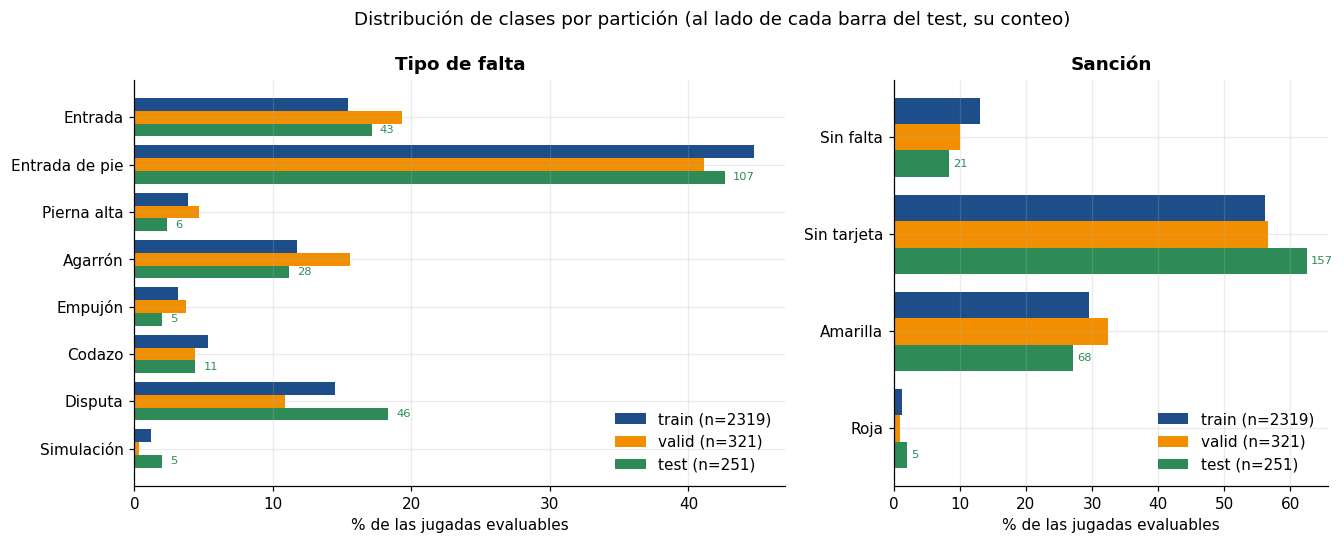

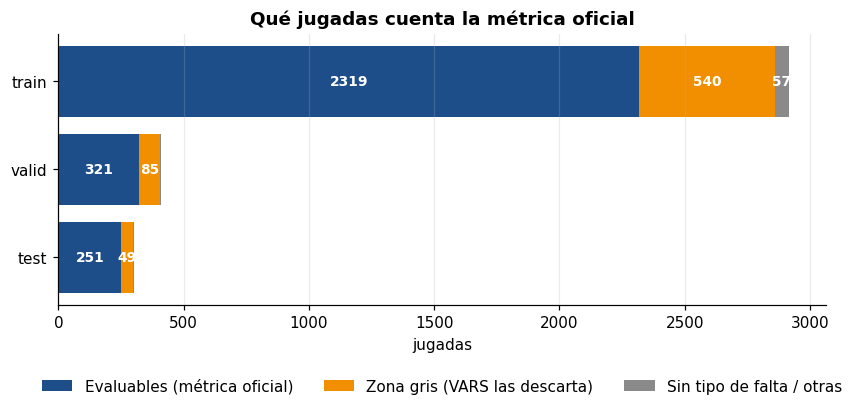

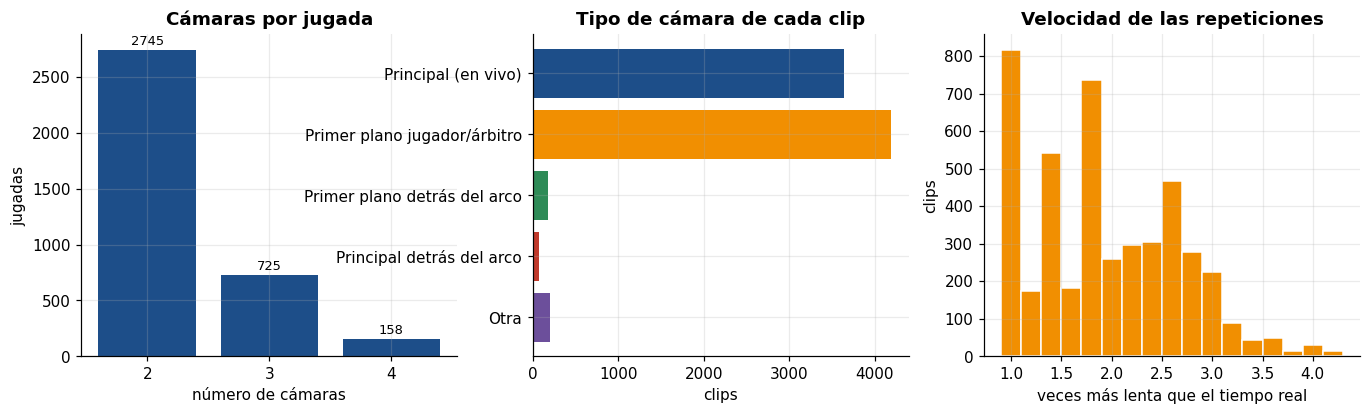

In [14]:
fig, axs = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={'width_ratios': [1.5, 1]})
for ax, col, nombres, C, titulo in [(axs[0], 'y_act_of', ACC_ES, 8, 'Tipo de falta'), (axs[1], 'y_sev_of', SEV_ES, 4, 'Sanción')]:
    y, alto = np.arange(C), 0.27
    for j, s in enumerate(CFG['splits']):
        v = ACTS[(ACTS.split == s) & ACTS.limpia][col].value_counts().reindex(range(C), fill_value=0)
        pct = 100 * v / max(v.sum(), 1)
        ax.barh(y + (j - 1) * alto, pct.values, height=alto, color=PALETA[j], label=f'{s} (n={v.sum()})')
        if s == 'test':
            for yi, (pp, n) in enumerate(zip(pct.values, v.values)):
                ax.text(pp + 0.6, yi + alto, str(n), va='center', fontsize=7.5, color=PALETA[j])
    ax.set_yticks(y); ax.set_yticklabels(nombres); ax.invert_yaxis()
    ax.set_xlabel('% de las jugadas evaluables'); ax.set_title(titulo); ax.legend(loc='lower right')
fig.suptitle('Distribución de clases por partición (al lado de cada barra del test, su conteo)', y=1.01)
guardar_fig(fig, '01_clases')

comp = pd.DataFrame({s: {'Evaluables (métrica oficial)': int(((ACTS.split == s) & ACTS.limpia).sum()),
                         'Zona gris (VARS las descarta)': int(((ACTS.split == s) & ACTS.gris & ~ACTS.limpia).sum()),
                         'Sin tipo de falta / otras': int(((ACTS.split == s) & ~ACTS.gris & ~ACTS.limpia).sum())}
                     for s in CFG['splits']}).T
fig, ax = plt.subplots(figsize=(9, 3.2))
izq = np.zeros(len(comp))
for j, col in enumerate(comp.columns):
    vals = comp[col].values
    ax.barh(comp.index, vals, left=izq, color=[COL['azul'], COL['naranja'], COL['gris']][j], label=col)
    for i, (l, v) in enumerate(zip(izq, vals)):
        if v > 40:
            ax.text(l + v / 2, i, str(v), ha='center', va='center', color='white', fontsize=9, fontweight='bold')
    izq += vals
ax.invert_yaxis(); ax.set_xlabel('jugadas'); ax.grid(axis='y', visible=False)
ax.set_title('Qué jugadas cuenta la métrica oficial')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.22), ncol=3)
guardar_fig(fig, '02_composicion')

fig, axs = plt.subplots(1, 3, figsize=(15, 3.8))
nv = ACTS.n_vistas.value_counts().sort_index()
b = axs[0].bar(nv.index.astype(str), nv.values, color=COL['azul'])
etiquetar_barras(axs[0], b, '{:.0f}', dy=20)
axs[0].set_title('Cámaras por jugada'); axs[0].set_xlabel('número de cámaras'); axs[0].set_ylabel('jugadas')
cams = CLIPS_DF.cam.value_counts().reindex(range(len(CAM_ES)), fill_value=0)
axs[1].barh(CAM_ES, cams.values, color=PALETA[:len(CAM_ES)]); axs[1].invert_yaxis()
axs[1].set_title('Tipo de cámara de cada clip'); axs[1].set_xlabel('clips')
axs[2].hist(CLIPS_DF[~CLIPS_DF.vivo].vel, bins=np.arange(0.9, 4.31, 0.2), color=COL['naranja'], edgecolor='white')
axs[2].set_title('Velocidad de las repeticiones'); axs[2].set_xlabel('veces más lenta que el tiempo real'); axs[2].set_ylabel('clips')
guardar_fig(fig, '03_camaras')

**Lectura: cómo son los datos.**
- **Las clases están muy desbalanceadas.** «Entrada de pie» es cerca del 43 % de las jugadas; pierna alta, empujón y simulación no llegan al 5 %. En la sanción, «sin tarjeta» es el 56–63 % y las **rojas son el 1 %**: 27 en train, 3 en valid y 5 en test.
- **Por eso se mide con exactitud balanceada.** Un modelo que siempre respondiera «entrada de pie, sin tarjeta» tendría 43 % y 63 % de exactitud, pero solo 12,5 % y 25 % de BA.
- **Zona gris:** 540, 85 y 49 jugadas (train, valid y test) en las que el árbitro dudó entre dos decisiones. La métrica oficial las descarta; aquí se usan para entrenar.
- **Cámaras:** el 75 % de las jugadas tiene 2 cámaras (2 745), 725 tienen 3 y 158 tienen 4. Casi todo es la toma principal en vivo o un primer plano; las cámaras detrás del arco son raras. Las repeticiones van de 1 a 4 veces más lentas que el tiempo real.

---


### Grupos de validación cruzada

Los partidos de train y valid se reparten en 5 grupos que tienen más o menos las mismas rojas y simulaciones. Comparado con la validación oficial, cada grupo tiene el doble de rojas y varias veces más simulaciones.

,partidos,evaluables,rojas,simulaciones
grupo,,,,
Grupo 0,66,530,6,6
Grupo 1,66,533,6,6
Grupo 2,65,524,6,6
Grupo 3,65,535,6,6
Grupo 4,65,518,6,5
Valid oficial,45,321,3,1


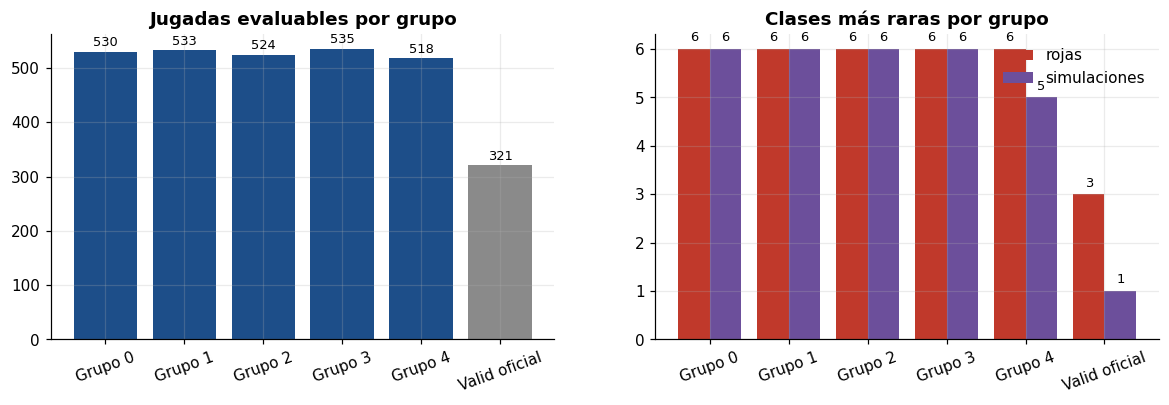

In [15]:
filas = []
for f in range(CFG['n_folds']):
    s = FOLD == f
    filas.append({'grupo': f'Grupo {f}', 'partidos': ACTS.partido[s].nunique(), 'evaluables': int((s & LIMPIA).sum()),
                  'rojas': int((s & (Y_SEV_OF == 3)).sum()), 'simulaciones': int((s & (Y_ACT_OF == 7)).sum())})
s = SPLIT == 'valid'
filas.append({'grupo': 'Valid oficial', 'partidos': ACTS.partido[s].nunique(), 'evaluables': int((s & LIMPIA).sum()),
              'rojas': int((s & (Y_SEV_OF == 3)).sum()), 'simulaciones': int((s & (Y_ACT_OF == 7)).sum())})
tab_folds = pd.DataFrame(filas).set_index('grupo')
tab_folds.to_csv(TAB / 'grupos_validacion.csv')
display(tab_folds)

fig, axs = plt.subplots(1, 2, figsize=(13, 3.6))
colores = [COL['azul']] * CFG['n_folds'] + [COL['gris']]
b = axs[0].bar(tab_folds.index, tab_folds.evaluables, color=colores)
etiquetar_barras(axs[0], b, '{:.0f}', dy=5)
axs[0].set_title('Jugadas evaluables por grupo'); axs[0].tick_params(axis='x', rotation=20)
x = np.arange(len(tab_folds))
b1 = axs[1].bar(x - 0.2, tab_folds.rojas, 0.4, color=COL['rojo'], label='rojas')
b2 = axs[1].bar(x + 0.2, tab_folds.simulaciones, 0.4, color=COL['morado'], label='simulaciones')
etiquetar_barras(axs[1], b1, '{:.0f}', dy=0.1); etiquetar_barras(axs[1], b2, '{:.0f}', dy=0.1)
axs[1].set_xticks(x); axs[1].set_xticklabels(tab_folds.index, rotation=20)
axs[1].set_title('Clases más raras por grupo'); axs[1].legend()
guardar_fig(fig, '05_grupos_validacion')

## 11. Caché de fotogramas

Se decodifica cada clip una sola vez, usando todos los núcleos de la CPU. Luego se borran los mp4: desde aquí todo trabaja con los fotogramas guardados.

In [16]:
with fase('3. Caché de fotogramas'):
    t = time.time()
    errores = cachear_fotogramas(range(N_CLIPS))
    CLIP_OK = np.array([(CACHE / f'{c}.pkl').exists() for c in range(N_CLIPS)])
    print(f'{CLIP_OK.sum()} de {N_CLIPS} clips en caché en {(time.time() - t) / 60:.1f} min; errores: {len(errores)}')
    if (~CLIP_OK).sum() > 0.02 * N_CLIPS:
        raise RuntimeError(f'Demasiados clips sin leer: {errores[:5]}')
    if (~CLIP_OK).any():
        aviso(f'{(~CLIP_OK).sum()} clips no se pudieron leer y se excluyen: {errores[:3]}')
        A_CLIPS[np.isin(A_CLIPS, np.flatnonzero(~CLIP_OK))] = -1
    tam = sum(p.stat().st_size for p in CACHE.glob('*.pkl')) / 1e9
    print(f'Tamaño de la caché: {tam:.1f} GB')
    shutil.rmtree(VIDEOS, ignore_errors=True)                # los mp4 ya no hacen falta
    REPORTE['cache'] = dict(clips=int(CLIP_OK.sum()), gb=round(tam, 2), min=round((time.time() - t) / 60, 1))


3. Caché de fotogramas   (minuto 1, quedan 659 min)
8297 de 8297 clips en caché en 5.3 min; errores: 0
Tamaño de la caché: 8.0 GB


[Figura retirada de la versión pública: muestra fotogramas de los videos de SoccerNet-MVFoul, protegidos por NDA.]


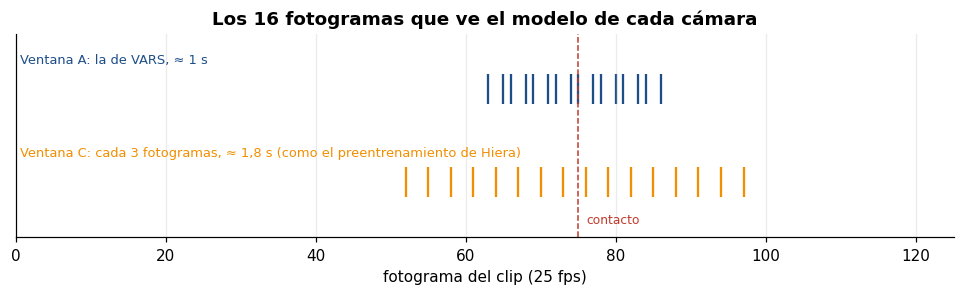

In [17]:
# Una jugada del test vista desde sus cámaras, y qué fotogramas toma cada esquema
cand = [g for g in TEST if LIMPIA[g] and (A_CLIPS[g] >= 0).sum() >= 3 and Y_SEV_OF[g] >= 2 and A_VEL[g].max() >= 2]
cand = cand or [g for g in TEST if LIMPIA[g] and (A_CLIPS[g] >= 0).sum() >= 2]
G_EJ = int(cand[0])
slots = np.flatnonzero(A_CLIPS[G_EJ] >= 0)[:3]
cols = [IDX_VARS[0], IDX_VARS[8], IDX_VARS[-1]]
fig, axs = plt.subplots(len(slots), 3, figsize=(12, 2.35 * len(slots)), squeeze=False)
for r, s in enumerate(slots):
    fr = cargar_fotogramas(int(A_CLIPS[G_EJ, s]), cols)
    for k in range(3):
        axs[r, k].imshow(fr[k]); axs[r, k].axis('off')
        axs[r, k].set_title(f'{CAM_ES[A_CAM[G_EJ, s]]} · {A_VEL[G_EJ, s]:.1f}× · fotograma {cols[k]}', fontsize=8.5)
fig.suptitle(f'Jugada {ACTS.aid[G_EJ]} del test: {ACC_ES[Y_ACT_OF[G_EJ]]} – {SEV_ES[Y_SEV_OF[G_EJ]]}', y=1.0)
guardar_fig(fig, '04a_jugada_ejemplo')

fig, ax = plt.subplots(figsize=(11, 2.4))
for r, (idx, nombre, c) in enumerate([(IDX_C, 'Ventana C: cada 3 fotogramas, ≈ 1,8 s (como el preentrenamiento de Hiera)', COL['naranja']),
                                       (IDX_VARS, 'Ventana A: la de VARS, ≈ 1 s', COL['azul'])]):
    ax.scatter(idx, [r] * len(idx), marker='|', s=400, color=c)
    ax.text(0.5, r + 0.28, nombre, fontsize=8.5, color=c)
ax.axvline(CONTACTO, color=COL['rojo'], ls='--', lw=1); ax.text(CONTACTO + 1, -0.45, 'contacto', color=COL['rojo'], fontsize=8)
ax.set_yticks([]); ax.set_xlim(0, 125); ax.set_ylim(-0.6, 1.6); ax.set_xlabel('fotograma del clip (25 fps)')
ax.set_title('Los 16 fotogramas que ve el modelo de cada cámara')
guardar_fig(fig, '04b_ventanas')

**Lectura: grupos y ventanas.**
- **Los 5 grupos quedaron parejos:** de 518 a 535 jugadas, 6 rojas y 5 o 6 simulaciones cada uno. La validación oficial tiene solo 3 rojas y 1 simulación. Por eso la escalera de ablación se decide con validación cruzada y no con valid.
- **La jugada de ejemplo** (figura retirada de esta versión por el NDA) muestra el problema: en la toma en vivo los jugadores son muy pequeños, mientras que en la repetición se ve el contacto de cerca.
- **Ventanas:** la A (la de VARS) cubre cerca de 1 s alrededor del contacto; la C cubre 1,8 s tomando un fotograma de cada 3.

---


## 12. Prueba de humo

Se corre **todo el flujo** con unas 60 jugadas y 1 o 2 épocas: extracción con cada red, cabezas con validación cruzada y con el protocolo oficial, ajuste fino, segunda etapa, VARS, ensamble y Grad-CAM.
- Si falla algo esencial (MViT o las cabezas), el notebook se detiene aquí con el error, en los primeros minutos.
- Si falla un componente opcional, se desactiva y la corrida larga sigue sin él. Queda anotado en `outputs/reporte_corrida.json`.

In [18]:
def elegir_ensamble(cands, gva, pasos=5, mejora_min=0.002):
    """Selección voraz con reemplazo: agrega el modelo que más baja la pérdida logarítmica balanceada en valid
    (tipo + sanción). Es un criterio más suave que la exactitud balanceada, que con 3 rojas en valid salta mucho."""
    lv = LIMPIA[gva]; ya, ys = Y_ACT_OF[gva][lv], Y_SEV_OF[gva][lv]
    def costo(sel):
        pa = np.mean([cands[k]['va_a'] for k in sel], 0)[lv]
        ps = np.mean([cands[k]['va_s'] for k in sel], 0)[lv]
        return nll_balanceada(pa, ya, 8) + nll_balanceada(ps, ys, 4)
    sel, mejor = [], np.inf
    for _ in range(pasos):
        c = min(cands, key=lambda k: costo(sel + [k]))
        v = costo(sel + [c])
        if v >= mejor - mejora_min:
            break
        sel.append(c); mejor = v
    return sel, mejor

def promedio(cands, sel, clave):
    return np.mean([cands[k][clave] for k in sel], 0)

def prueba_de_humo():
    global NUM_WORKERS
    t, rng = time.time(), np.random.RandomState(1)
    sel = []
    for f in range(CFG['n_folds']):
        g = POOL[(FOLD[POOL] == f) & LIMPIA[POOL]]
        sel += list(rng.choice(g, min(6, len(g)), replace=False))
        g2 = POOL[(FOLD[POOL] == f) & GRIS[POOL]]
        if len(g2):
            sel += list(rng.choice(g2, 1, replace=False))
    pool_s = np.array(sorted(sel))
    tr_s = np.array(sorted(list(rng.choice(TRAIN_OF[LIMPIA[TRAIN_OF]], 24, replace=False)) +
                           list(rng.choice(TRAIN_OF[GRIS[TRAIN_OF]], 3, replace=False))))
    va_s = np.array(sorted(rng.choice(VALID_OF[LIMPIA[VALID_OF]], 10, replace=False)))
    te_s = np.array(sorted(list(rng.choice(TEST[LIMPIA[TEST]], 6, replace=False)) + list(rng.choice(TEST[GRIS[TEST]], 2, replace=False))))
    todos = clips_de(np.concatenate([pool_s, tr_s, va_s, te_s]))
    aum, ev = clips_de(np.concatenate([pool_s, tr_s])), clips_de(np.concatenate([va_s, te_s]))
    store = TMP / 'humo'
    shutil.rmtree(store, ignore_errors=True)
    try:                                                     # ¿funciona el DataLoader con procesos?
        next(iter(cargador(ClipsDS(todos[:4], [IDX_VARS] * 4), 2)))
    except Exception as e:
        aviso(f'El DataLoader con procesos falló ({e}); se usa num_workers=0')
        NUM_WORKERS = 0
    for enc, esq in [('mvit', 'A'), ('mvit_vars', 'A'), ('hiera', 'A'), ('hiera', 'C')]:
        if (enc == 'hiera' and not ACTIVO['hiera']) or (enc == 'mvit_vars' and not ACTIVO['vars']):
            continue
        try:
            extraer_codificador(enc, esq, cids_todos=todos, cids_aum=aum, store=store, K_fijo=1)
            pasada_espejo(enc, esq, f'{enc}_{esq}', cids=ev, store=store)
        except Exception as e:
            if enc == 'mvit':
                raise
            ACTIVO['hiera' if enc == 'hiera' else 'vars'] = False
            traceback.print_exc()
            aviso(f'Prueba de humo: {enc} queda desactivado ({type(e).__name__}: {e})')
    fm = cargar_feats('mvit_A', store)
    correr_cv('humo · base', fm, RECETA_BASE, pool_s, te_s, epocas=2)
    correr_cv('humo · atención VARS', fm, {**RECETA_FINAL, 'agg': 'vars'}, pool_s, te_s, epocas=1)
    rc = correr_cv('humo · final', fm, RECETA_FINAL, pool_s, te_s, epocas=2)
    predecir_cv(rc, fm, te_s, 'vivo')
    kw = dict(gids_tr=tr_s, gids_va=va_s, gids_test=te_s)
    cands = {'m': cabeza_oficial('humo · MViT oficial', fm, RECETA_FINAL, cargar_espejo('mvit_A', store), semillas=(0,), epocas=2, **kw)}
    if ACTIVO['vars']:
        cands['v'] = cabeza_oficial('humo · VARS congelado', cargar_feats('mvit_vars_A', store), RECETA_FINAL,
                                    cargar_espejo('mvit_vars_A', store), semillas=(0,), epocas=2, **kw)
    if ACTIVO['hiera']:
        cands['h'] = cabeza_oficial('humo · Hiera congelado', cargar_feats('hiera_C', store), RECETA_FINAL,
                                    cargar_espejo('hiera_C', store), semillas=(0,), epocas=2, **kw)
    r = cands['m']
    it = np.flatnonzero(LIMPIA[te_s]); gl = te_s[it]
    ha = ajuste_logits(r['test_a'], r['tau'][0], PRIOR_ACT).argmax(1)
    hs = ajuste_logits(r['test_s'], r['tau'][1], PRIOR_SEV).argmax(1)
    bootstrap_lb(Y_ACT_OF[gl], Y_SEV_OF[gl], ha[it], hs[it], ref=(ha[it], hs[it]), B=50)
    T = ajustar_T(r['test_s'][it], Y_SEV_OF[gl]); ece(con_T(r['test_s'][it], T), Y_SEV_OF[gl])
    curva_cobertura(r['test_s'][it], Y_SEV_OF[gl])
    escribir_predicciones(store / 'pred.json', te_s, ha, hs)
    evaluar_oficial(ANOT / 'test.json', store / 'pred.json')
    sel_e, _ = elegir_ensamble(cands, va_s)
    resultado_oficial('humo · ensamble', va_s, promedio(cands, sel_e, 'va_a'), promedio(cands, sel_e, 'va_s'),
                      te_s, promedio(cands, sel_e, 'test_a'), promedio(cands, sel_e, 'test_s'))
    rf = None
    if ACTIVO['ajuste']:
        try:
            kwf = dict(max_lotes=2, epocas=1, minutos_max=10, **kw)
            rf = ajustar_fino('humo · MViT Kinetics completo', 'mvit', 'completo', RECETA_FINAL, cands['m']['estados'][0], **kwf)
            etapa2('humo · segunda etapa', rf, K=1, semillas=(0,), epocas=1, **kw)
            if ACTIVO['vars']:
                rf = ajustar_fino('humo · VARS completo', 'mvit_vars', 'completo', RECETA_FINAL, cands['v']['estados'][0], **kwf)
            if ACTIVO['hiera']:
                ajustar_fino('humo · Hiera parcial', 'hiera', 'parcial', RECETA_FINAL, cands['h']['estados'][0],
                             n_bloques=CFG['ajuste']['bloques_hiera'], esquema='C', **kwf)
        except Exception as e:
            ACTIVO['ajuste'] = False
            traceback.print_exc()
            aviso(f'Prueba de humo: el ajuste fino queda desactivado ({type(e).__name__}: {e})')
    if ACTIVO['vars']:
        try:
            reproducir_vars(te_s[:2]); reproducir_vars(te_s[:2], espejo=True)
        except Exception as e:
            ACTIVO['vars'] = False
            aviso(f'Prueba de humo: VARS reproducido queda desactivado ({type(e).__name__}: {e})')
    try:
        if rf is not None:
            cod, cab = rf['modelo']
        else:
            cod, cab = Codificador('mvit'), nueva_cabeza(768, False, RECETA_FINAL)
            cab.load_state_dict(cands['m']['estados'][0])
        gradcam_mvit(cod, cab, RECETA_FINAL, int(te_s[0]), 'A')
        del cod, cab
    except Exception as e:
        ACTIVO['gradcam'] = False
        aviso(f'Prueba de humo: Grad-CAM queda desactivado ({type(e).__name__}: {e})')
    shutil.rmtree(store, ignore_errors=True); gc.collect(); torch.cuda.empty_cache()
    print(f'\nPrueba de humo terminada en {(time.time() - t) / 60:.1f} min. Componentes activos: {ACTIVO}')

with fase('4. Prueba de humo'):
    prueba_de_humo()
    REPORTE['activos_tras_humo'] = dict(ACTIVO)


4. Prueba de humo   (minuto 7, quedan 653 min)
Downloading: "https://download.pytorch.org/models/mvit_v2_s-ae3be167.pth" to /root/.cache/torch/hub/checkpoints/mvit_v2_s-ae3be167.pth


100%|██████████| 132M/132M [00:00<00:00, 199MB/s]


{'codificador': 'mvit', 'esquema': 'A', 'etiqueta': 'mvit_A', 'modelo': 'MViT-V2-S (Kinetics)', 'K': 1, 'clips_por_s': 15.7, 'min_limpia': 0.19, 'min_total': 0.31, 'dim': [768]}
{'codificador': 'mvit_vars', 'esquema': 'A', 'etiqueta': 'mvit_vars_A', 'modelo': 'MViT-V2-S (VARS)', 'K': 1, 'clips_por_s': 22.0, 'min_limpia': 0.14, 'min_total': 0.25, 'dim': [768]}
Downloading: "https://dl.fbaipublicfiles.com/hiera/hiera_base_plus_16x224.pth" to /root/.cache/torch/hub/checkpoints/hiera_base_plus_16x224.pth


100%|██████████| 794M/794M [00:16<00:00, 49.5MB/s]


{'codificador': 'hiera', 'esquema': 'A', 'etiqueta': 'hiera_A', 'modelo': 'Hiera-B+', 'K': 1, 'clips_por_s': 13.4, 'min_limpia': 0.22, 'min_total': 0.39, 'dim': [896]}
{'codificador': 'hiera', 'esquema': 'C', 'etiqueta': 'hiera_C', 'modelo': 'Hiera-B+', 'K': 1, 'clips_por_s': 13.8, 'min_limpia': 0.22, 'min_total': 0.39, 'dim': [896]}
humo · base                              validación  30.1 ± 9.0 | +τ  30.6 | test  25.0 | +τ   0.0 | 0.0 min
humo · atención VARS                     validación  24.1 ±11.4 | +τ  38.6 | test  25.0 | +τ  25.0 | 0.0 min
humo · final                             validación  32.7 ± 3.8 | +τ  37.2 | test  25.0 | +τ   0.0 | 0.0 min
humo · MViT oficial                          valid  25.0 | +τ  25.0 | test  25.0 | +τ  25.0
humo · VARS congelado                        valid  16.7 | +τ  16.7 | test  18.8 | +τ  18.8
humo · Hiera congelado                       valid  50.0 | +τ  50.0 | test  31.2 | +τ  31.2
humo · ensamble                              valid  50.0 | +τ

## 13. Punto de partida: VARS con sus propios pesos

Se evalúa el modelo oficial de VARS tal cual, en valid y en test. También se evalúa promediando con la imagen volteada (TTA), para separar cuánto aporta ese truco por sí solo.


5. VARS reproducido   (minuto 10, quedan 650 min)
VARS reproducido                             valid  38.3 | +τ  38.3 | test  39.9 | +τ  39.9
VARS reproducido + TTA                       valid  38.5 | +τ  38.6 | test  40.3 | +τ  38.7
Métrica oficial de SoccerNet: {'accuracy_offence_severity': np.float64(36.3), 'accuracy_action': np.float64(55.0), 'balanced_accuracy_offence_severity': np.float64(35.9), 'balanced_accuracy_action': np.float64(43.9), 'leaderboard_value': np.float64(39.9)}


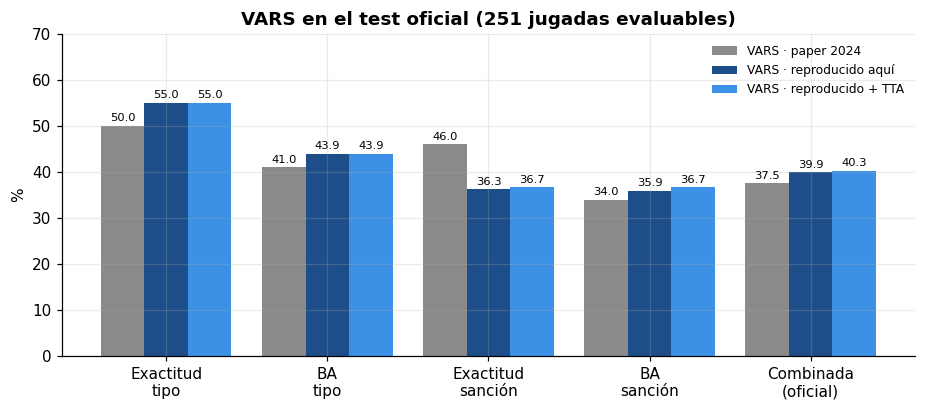

In [19]:
with fase('5. VARS reproducido', opcional=True):
    if not ACTIVO['vars']:
        raise RuntimeError('desactivado en la prueba de humo')
    ev, nv = np.concatenate([VALID_OF, TEST]), len(VALID_OF)
    pa, ps = reproducir_vars(ev)
    pa2, ps2 = reproducir_vars(ev, espejo=True)
    RES['vars'] = resultado_oficial('VARS reproducido', VALID_OF, pa[:nv], ps[:nv], TEST, pa[nv:], ps[nv:])
    RES['vars_tta'] = resultado_oficial('VARS reproducido + TTA', VALID_OF, (pa[:nv] + pa2[:nv]) / 2, (ps[:nv] + ps2[:nv]) / 2,
                                        TEST, (pa[nv:] + pa2[nv:]) / 2, (ps[nv:] + ps2[nv:]) / 2)
    escribir_predicciones(OUT / 'predicciones_test_vars.json', TEST, pa[nv:].argmax(1), ps[nv:].argmax(1))
    RES['vars']['oficial'] = evaluar_oficial(ANOT / 'test.json', OUT / 'predicciones_test_vars.json')
    print('Métrica oficial de SoccerNet:', {k: round(v, 1) for k, v in RES['vars']['oficial'].items()})

    claves = ['acc_act', 'ba_act', 'acc_sev', 'ba_sev', 'lb']
    etiquetas = ['Exactitud\ntipo', 'BA\ntipo', 'Exactitud\nsanción', 'BA\nsanción', 'Combinada\n(oficial)']
    x = np.arange(len(claves))
    fig, ax = plt.subplots(figsize=(10, 3.8))
    for j, (vals, nombre, c) in enumerate([([VARS_PAPER[k] for k in claves], 'VARS · paper 2024', COL['gris']),
                                           ([RES['vars']['test'][k] for k in claves], 'VARS · reproducido aquí', COL['azul']),
                                           ([RES['vars_tta']['test'][k] for k in claves], 'VARS · reproducido + TTA', COL['celeste'])]):
        b = ax.bar(x + (j - 1) * 0.27, vals, 0.27, color=c, label=nombre)
        etiquetar_barras(ax, b, size=7.5)
    ax.set_xticks(x); ax.set_xticklabels(etiquetas); ax.set_ylabel('%'); ax.set_ylim(0, 70)
    ax.set_title(f'VARS en el test oficial ({len(POS_TEST_LIMPIA)} jugadas evaluables)'); ax.legend(fontsize=8)
    guardar_fig(fig, '06_vars_reproducido')

**Lectura: VARS reproducido.**
- Con sus pesos públicos, VARS da **39,9 %** de BA combinada en el test, 2,4 puntos más que el 37,5 de su paper. La métrica oficial de SoccerNet da el mismo número, así que la implementación de la métrica es correcta.
- La diferencia con el paper puede venir de las versiones de las librerías o de la decodificación del video. Se toma **39,9 como referencia** porque es la comparación más exigente y la más justa: mismas jugadas, misma máquina, misma métrica.
- Voltear la imagen y promediar (TTA) le suma solo 0,4 puntos (40,3), dentro del ruido.
- VARS es fuerte en el tipo de falta (exactitud 55,0 %, BA 43,9) y débil en la sanción (exactitud 36,3 %, BA 35,9).

---


## 14. MViT de Kinetics congelado: escalera de ablación

Esta parte responde la pregunta 2: qué aporta cada componente de la cabeza. Se hace sobre MViT de Kinetics congelado, que nunca vio el dataset, así que la validación cruzada por partido sobre train+valid es válida.

| Paso | Qué se agrega |
|---|---|
| L0 | Máximo entre cámaras + entropía cruzada ponderada (≈ VARS) |
| L1 | Atención de VARS en lugar del máximo |
| L2 | Transformer entre cámaras + embedding de tipo de cámara y velocidad |
| L3 | Aumento en el espacio de características + quitar cámaras al azar |
| L4 | Los 6 atributos del árbitro como tareas auxiliares |
| L5 | Jugadas de zona gris con etiquetas suaves · **receta final** |
| L6 | Sanción ordinal en cadena (se deja para comparar; no entra en la receta final) |
| L7 | Ajuste de logits para la exactitud balanceada (τ escogido en validación) |

In [20]:
INFO_FEATS, FEATS_MEM = {}, {}
with fase('6. Características MViT (Kinetics)'):
    INFO_FEATS['mvit'] = extraer_codificador('mvit', 'A', CFG['K_max']['mvit'], CFG['presupuesto']['mvit'])
    FEATS_MEM['mvit_A'] = cargar_feats('mvit_A')

with fase('7. Escalera de ablación (MViT de Kinetics congelado)'):
    for nombre, receta in RECETAS:
        RES[f'mvit|{nombre}'] = correr_cv(nombre, FEATS_MEM['mvit_A'], receta)
NOMBRE_L5, NOMBRE_L6 = RECETAS[5][0], RECETAS[-1][0]


6. Características MViT (Kinetics)   (minuto 16, quedan 644 min)
{'codificador': 'mvit', 'esquema': 'A', 'etiqueta': 'mvit_A', 'modelo': 'MViT-V2-S (Kinetics)', 'K': 2, 'clips_por_s': 24.6, 'min_limpia': 5.61, 'min_total': 15.64, 'dim': [768]}

7. Escalera de ablación (MViT de Kinetics congelado)   (minuto 31, quedan 629 min)
L0 Máximo (≈ VARS)                       validación  29.1 ± 2.1 | +τ  29.1 | test  33.2 | +τ  33.2 | 0.3 min
L1 Atención de VARS                      validación  29.6 ± 1.2 | +τ  29.6 | test  30.3 | +τ  30.3 | 0.5 min
L2 Transformer + cámara                  validación  31.6 ± 1.2 | +τ  31.6 | test  31.7 | +τ  31.7 | 0.7 min
L3 + aumento de características          validación  31.2 ± 1.6 | +τ  31.2 | test  35.4 | +τ  35.4 | 1.1 min
L4 + atributos del árbitro               validación  30.2 ± 1.8 | +τ  30.2 | test  33.6 | +τ  33.6 | 1.2 min
L5 + zona gris (etiquetas suaves)        validación  32.5 ± 2.5 | +τ  32.5 | test  36.6 | +τ  36.6 | 1.6 min
L6 + sanción ordi

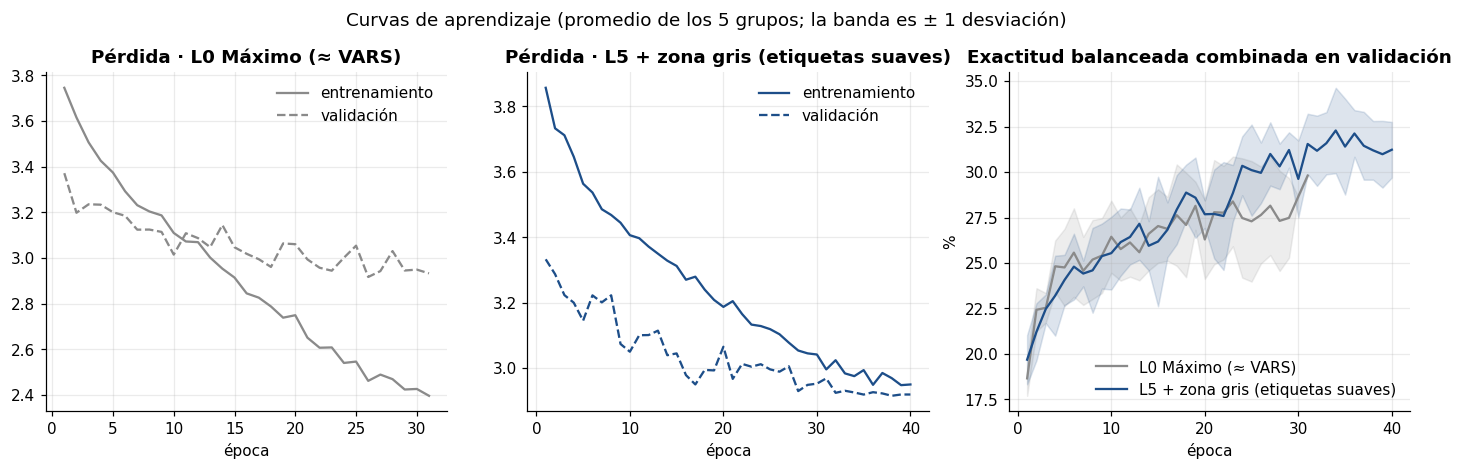

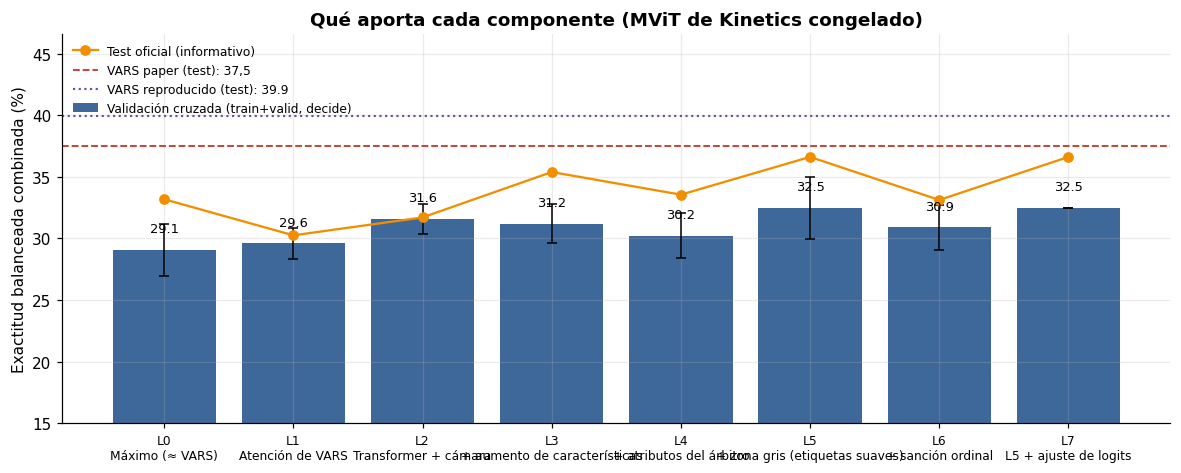

,paso,val_acc_act,val_ba_act,val_acc_sev,val_ba_sev,val_lb,test_acc_act,test_ba_act,test_acc_sev,test_ba_sev,test_lb
0,L0 Máximo (≈ VARS),28.9,27.4,37.7,30.7,29.1,31.1,32.9,47.0,33.5,33.2
1,L1 Atención de VARS,29.7,27.0,33.6,32.2,29.6,31.5,29.9,38.2,30.6,30.3
2,L2 Transformer + cámara,23.7,26.4,35.7,36.8,31.6,29.1,28.2,43.0,35.2,31.7
3,L3 + aumento de características,29.7,28.7,40.4,33.7,31.2,33.9,30.3,52.6,40.5,35.4
4,L4 + atributos del árbitro,28.7,27.8,38.6,32.6,30.2,33.1,30.8,49.0,36.3,33.6
5,L5 + zona gris (etiquetas suaves),31.6,31.0,41.0,34.0,32.5,34.7,34.3,48.6,38.9,36.6
6,L6 + sanción ordinal,29.5,29.0,39.7,32.8,30.9,35.9,30.2,46.6,36.1,33.1


In [21]:
def curva_media(hists, clave):
    L = max(len(h) for h in hists)
    M = np.full((len(hists), L), np.nan)
    for i, h in enumerate(hists):
        M[i, :len(h)] = [e[clave] for e in h]
    return np.arange(1, L + 1), np.nanmean(M, 0), np.nanstd(M, 0)

fig, axs = plt.subplots(1, 3, figsize=(16, 4))
for i, (nombre, color) in enumerate([(RECETAS[0][0], COL['gris']), (NOMBRE_L5, COL['azul'])]):
    r = RES[f'mvit|{nombre}']
    x, tr, _ = curva_media(r['hist'], 'loss_tr'); x2, va, _ = curva_media(r['hist'], 'loss_va')
    axs[i].plot(x, tr, color=color, label='entrenamiento'); axs[i].plot(x2, va, color=color, ls='--', label='validación')
    axs[i].set_title(f'Pérdida · {nombre}'); axs[i].set_xlabel('época'); axs[i].legend()
    x3, m, s = curva_media(r['hist'], 'lb_va')
    axs[2].plot(x3, m, color=color, label=nombre); axs[2].fill_between(x3, m - s, m + s, color=color, alpha=0.15)
axs[2].set_title('Exactitud balanceada combinada en validación'); axs[2].set_xlabel('época'); axs[2].set_ylabel('%'); axs[2].legend()
fig.suptitle('Curvas de aprendizaje (promedio de los 5 grupos; la banda es ± 1 desviación)', y=1.02)
guardar_fig(fig, '09_curvas_cabeza')

pasos = [n for n, _ in RECETAS if f'mvit|{n}' in RES]
val = [RES[f'mvit|{n}']['oof']['lb'] for n in pasos] + [RES[f'mvit|{NOMBRE_L5}']['oof_tau']['lb']]
dev = [np.nanstd(RES[f'mvit|{n}']['oof_folds']) for n in pasos] + [0]
tst = [RES[f'mvit|{n}']['test']['lb'] for n in pasos] + [RES[f'mvit|{NOMBRE_L5}']['test_tau']['lb']]
nombres = pasos + ['L7 L5 + ajuste de logits']
fig, ax = plt.subplots(figsize=(13, 4.6))
x = np.arange(len(nombres))
b = ax.bar(x, val, color=COL['azul'], alpha=0.85, label='Validación cruzada (train+valid, decide)')
ax.errorbar(x, val, yerr=dev, fmt='none', ecolor='k', capsize=3, lw=1)
etiquetar_barras(ax, b, dy=1.2)
ax.plot(x, tst, 'o-', color=COL['naranja'], label='Test oficial (informativo)')
ax.axhline(VARS_PAPER['lb'], color=COL['rojo'], ls='--', lw=1.2, label='VARS paper (test): 37,5')
if 'vars' in RES:
    ax.axhline(RES['vars']['test']['lb'], color=COL['morado'], ls=':', lw=1.4, label=f'VARS reproducido (test): {RES["vars"]["test"]["lb"]:.1f}')
ax.set_xticks(x); ax.set_xticklabels([n.replace(' ', '\n', 1) for n in nombres], fontsize=8)
ax.set_ylabel('Exactitud balanceada combinada (%)'); ax.set_ylim(15, max(val + tst) + 10)
ax.set_title('Qué aporta cada componente (MViT de Kinetics congelado)'); ax.legend(loc='upper left', fontsize=8)
guardar_fig(fig, '10_escalera_ablacion')

tab = pd.DataFrame([{'paso': n, **{f'val_{k}': round(v, 1) for k, v in RES[f'mvit|{n}']['oof'].items()},
                     **{f'test_{k}': round(v, 1) for k, v in RES[f'mvit|{n}']['test'].items()}} for n in pasos])
tab.to_csv(TAB / 'escalera_ablacion.csv', index=False)
display(tab)

**Lectura: escalera de ablación (MViT de Kinetics congelado).** Para decidir se mira la columna de validación cruzada; el test se muestra solo como referencia.

| Paso | Validación cruzada | Cambio | Test |
|---|---|---|---|
| L0 Máximo (≈ VARS) | 29,1 ± 2,1 | | 33,2 |
| L1 Atención de VARS | 29,6 ± 1,2 | +0,5 | 30,3 |
| L2 Transformer + cámara | 31,6 ± 1,2 | +2,0 | 31,7 |
| L3 + aumento de características | 31,2 ± 1,6 | −0,4 | 35,4 |
| L4 + atributos del árbitro | 30,2 ± 1,8 | −1,0 | 33,6 |
| **L5 + zona gris** | **32,5 ± 2,5** | **+2,3** | **36,6** |
| L6 + sanción ordinal | 30,9 ± 1,8 | −1,6 | 33,1 |

- **Lo que sirve:** el transformer con embedding de cámara (+2,0) y entrenar con las jugadas de zona gris (+2,3). De L0 a L5 se ganan 3,4 puntos.
- **Lo que no sirve:** los atributos del árbitro como tareas extra (−1,0) y la sanción ordinal (−1,6), que ya había empeorado en las pruebas preliminares.
- **Ruido:** la desviación entre grupos es de 1 a 2,5 puntos, así que los pasos de un punto o menos no son diferencias reales. Solo el salto completo de L0 a L5 es claro.
- El ajuste τ no cambió nada en la validación cruzada (la columna +τ es igual).
- **Curvas:**
  - con L0 la cabeza **sobreajusta**: la pérdida de entrenamiento baja hasta 2,4 mientras la de validación se queda en ≈ 2,95, y para por paciencia hacia la época 31;
  - con L5 (aumento, quitar cámaras y zona gris) las dos pérdidas bajan juntas, **sin sobreajuste**, y la BA sigue subiendo hasta el tope de 40 épocas.

  La regularización de la receta final es lo que permite entrenar más tiempo.

---


### Cómo unir las cámaras

Con la receta final (L5) se cambia solo la forma de combinar las cámaras.


7b. Agregación entre cámaras   (minuto 38, quedan 622 min)
Receta final con mean                    validación  29.3 ± 2.5 | +τ  29.3 | test  33.3 | +τ  33.3 | 0.6 min
Receta final con max                     validación  30.4 ± 1.9 | +τ  30.4 | test  33.2 | +τ  33.2 | 0.7 min
Receta final con vars                    validación  31.6 ± 1.7 | +τ  31.6 | test  37.6 | +τ  37.6 | 0.9 min


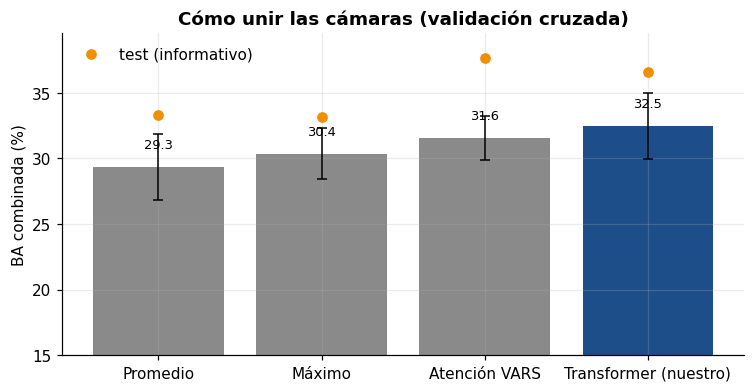

In [22]:
with fase('7b. Agregación entre cámaras', opcional=True):
    for agg in ('mean', 'max', 'vars'):
        RES[f'mvit|agg_{agg}'] = correr_cv(f'Receta final con {agg}', FEATS_MEM['mvit_A'], {**RECETA_FINAL, 'agg': agg})

etq = {'mean': 'Promedio', 'max': 'Máximo', 'vars': 'Atención VARS'}
items = [(etq[a], RES[f'mvit|agg_{a}']) for a in ('mean', 'max', 'vars') if f'mvit|agg_{a}' in RES]
items.append(('Transformer (nuestro)', RES[f'mvit|{NOMBRE_L5}']))
fig, ax = plt.subplots(figsize=(8, 3.8))
x = np.arange(len(items))
b = ax.bar(x, [r['oof']['lb'] for _, r in items], color=[COL['gris']] * (len(items) - 1) + [COL['azul']])
ax.errorbar(x, [r['oof']['lb'] for _, r in items], yerr=[np.nanstd(r['oof_folds']) for _, r in items],
            fmt='none', ecolor='k', capsize=3, lw=1)
etiquetar_barras(ax, b, dy=1.2)
ax.plot(x, [r['test']['lb'] for _, r in items], 'o', color=COL['naranja'], label='test (informativo)')
ax.set_xticks(x); ax.set_xticklabels([n for n, _ in items]); ax.set_ylim(15, None)
ax.set_title('Cómo unir las cámaras (validación cruzada)'); ax.set_ylabel('BA combinada (%)'); ax.legend()
guardar_fig(fig, '11_agregacion')

**Lectura: cómo unir las cámaras.** En validación cruzada: promedio 29,3, máximo 30,4, atención de VARS 31,6 y **transformer 32,5**.
- **Aprender cuánto pesa cada cámara** (atención o transformer) funciona mejor que una regla fija (máximo o promedio).
- Entre la atención de VARS y el transformer hay 0,9 puntos, menos que la desviación entre grupos (±1,7 a 2,5): **están empatados**. En el test la atención de VARS dio más (37,6 contra 36,6), pero el test no se usa para escoger.

---


## 15. Dos puntos de partida congelados: Kinetics contra VARS

Ahora se cambia al **protocolo oficial**: entrenar con train, escoger con valid y medir el test. Se extraen las características del MViT de VARS (que ya vio train) y se entrena encima la cabeza final; lo mismo con el MViT de Kinetics, para comparar en igualdad de condiciones. Estas cabezas son también el punto de arranque del ajuste fino (LP-FT).

In [23]:
with fase('8. MViT de VARS congelado', opcional=True):
    if not ACTIVO['vars']:
        raise RuntimeError('desactivado en la prueba de humo')
    INFO_FEATS['mvit_vars'] = extraer_codificador('mvit_vars', 'A', CFG['K_max']['mvit_vars'], CFG['presupuesto']['mvit_vars'],
                                                  cids_aum=clips_de(TRAIN_OF))
    FEATS_MEM['mvit_vars_A'] = cargar_feats('mvit_vars_A')
    RES['vars_cong'] = cabeza_oficial('MViT de VARS congelado + cabeza', FEATS_MEM['mvit_vars_A'], RECETA_FINAL,
                                      pasada_espejo('mvit_vars', 'A', 'mvit_vars_A'))

with fase('8b. MViT de Kinetics congelado (protocolo oficial)', opcional=True):
    RES['mvit_cong'] = cabeza_oficial('MViT de Kinetics congelado + cabeza', FEATS_MEM['mvit_A'], RECETA_FINAL,
                                      pasada_espejo('mvit', 'A', 'mvit_A'))


8. MViT de VARS congelado   (minuto 41, quedan 619 min)
{'codificador': 'mvit_vars', 'esquema': 'A', 'etiqueta': 'mvit_vars_A', 'modelo': 'MViT-V2-S (VARS)', 'K': 2, 'clips_por_s': 25.2, 'min_limpia': 5.48, 'min_total': 14.23, 'dim': [768]}
MViT de VARS congelado + cabeza              valid  41.2 | +τ  44.1 | test  36.7 | +τ  36.1

8b. MViT de Kinetics congelado (protocolo oficial)   (minuto 56, quedan 604 min)
MViT de Kinetics congelado + cabeza          valid  28.2 | +τ  31.9 | test  32.2 | +τ  31.0



8c. Mapa t-SNE   (minuto 58, quedan 602 min)


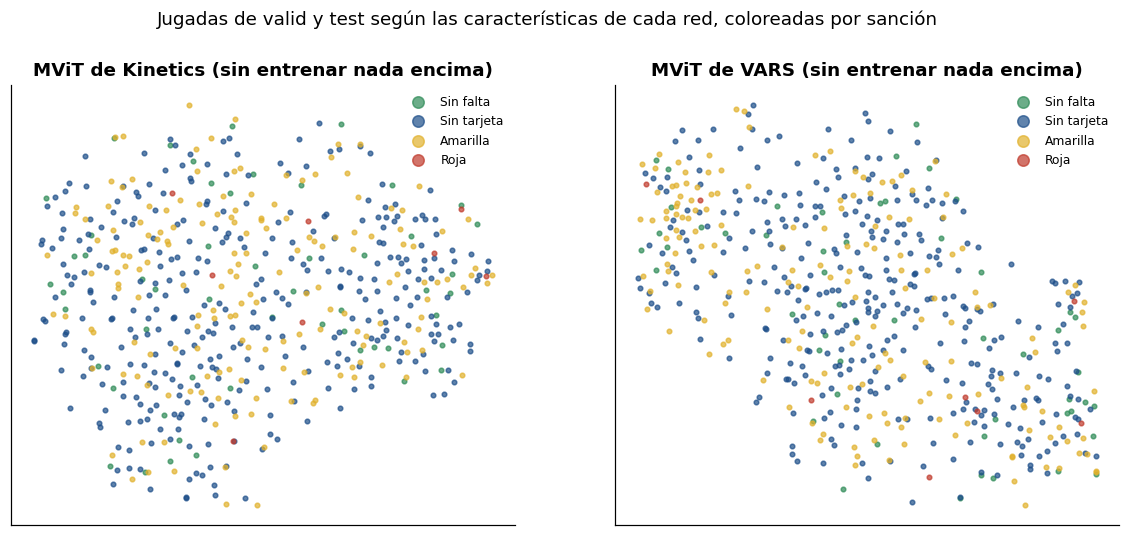

In [24]:
# Mapa t-SNE: cada punto es una jugada (promedio de sus cámaras); izquierda Kinetics, derecha VARS
with fase('8c. Mapa t-SNE', opcional=True):
    from sklearn.manifold import TSNE
    gs = TEST[LIMPIA[TEST]].tolist() + VALID_OF[LIMPIA[VALID_OF]].tolist()       # jugadas que ninguna red vio entrenando
    gs = np.array(gs)
    paneles = [(k, n) for k, n in [('mvit_A', 'MViT de Kinetics'), ('mvit_vars_A', 'MViT de VARS')] if k in FEATS_MEM]
    fig, axs = plt.subplots(1, len(paneles), figsize=(6.5 * len(paneles), 5.2), squeeze=False)
    for ax, (k, n) in zip(axs[0], paneles):
        f0 = FEATS_MEM[k][0]
        emb = np.stack([f0[A_CLIPS[g][A_CLIPS[g] >= 0]].astype(np.float32).mean(0) for g in gs])
        z = TSNE(n_components=2, init='pca', perplexity=30, random_state=0).fit_transform(emb)
        for c in range(4):
            s = Y_SEV_OF[gs] == c
            ax.scatter(z[s, 0], z[s, 1], s=9, alpha=0.7, color=[COL['verde'], COL['azul'], COL['amarillo'], COL['rojo']][c], label=SEV_ES[c])
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False); ax.set_title(f'{n} (sin entrenar nada encima)'); ax.legend(markerscale=2.5, fontsize=8)
    fig.suptitle('Jugadas de valid y test según las características de cada red, coloreadas por sanción', y=1.01)
    guardar_fig(fig, '08_tsne_kinetics_vs_vars')

**Lectura: Kinetics contra VARS, ambos congelados.**
- **Partir de una red que ya vio faltas ayuda mucho:** en el test, el MViT de VARS congelado saca 36,1 y el de Kinetics 31,0, es decir, **+5 puntos sin entrenar la red**.
- **La validación del MViT de VARS es optimista** (44,1 contra 36,1 en el test), porque VARS ya entrenó con train y escogió su época con valid.
- **Con τ, la exactitud del tipo de falta se cae** (15,9 % en el MViT de Kinetics, tabla final): la corrección por frecuencia empuja las predicciones hacia las clases raras. Ver limitaciones en la sección 21.
- **Mapa t-SNE:** con Kinetics las sanciones están totalmente mezcladas. Con VARS se insinúa algo de orden (las amarillas se juntan más a un lado), pero las clases siguen revueltas: ninguna red separa la sanción por sí sola, y hace falta la cabeza encima.

---


## 16. Hiera-B+: una arquitectura más fuerte

Hiera-B+ es un MViT simplificado, preentrenado como autoencoder enmascarado. Primero se compara la ventana A con la ventana C usando solo la pasada limpia y la validación cruzada. Con la ventana ganadora se agregan las pasadas aumentadas, se compara la receta base con la final y se entrena la cabeza del protocolo oficial, que es el punto de arranque del ajuste fino.

In [25]:
ESQ_HIERA = 'A'
with fase('9. Hiera-B+ congelado', opcional=True):
    if not ACTIVO['hiera']:
        raise RuntimeError('desactivado en la prueba de humo')
    if not hay_tiempo(CFG['presupuesto']['hiera'] + 330):
        raise SinTiempo('no alcanza el tiempo para Hiera y los ajustes')
    info_v = {'A': extraer_codificador('hiera', 'A', solo_limpia=True), 'C': extraer_codificador('hiera', 'C', solo_limpia=True)}
    rec_v = {**RECETA_FINAL, 'aum_feat': False}
    for esq in ('A', 'C'):
        RES[f'hiera|ventana_{esq}'] = correr_cv(f'Hiera · ventana {esq} (solo pasada limpia)', cargar_feats(f'hiera_{esq}'), rec_v)
    ESQ_HIERA = 'C' if RES['hiera|ventana_C']['oof']['lb'] > RES['hiera|ventana_A']['oof']['lb'] else 'A'
    print('Ventana elegida para Hiera en validación:', ESQ_HIERA)
    info = info_v[ESQ_HIERA]
    info['K'] = agregar_aumentadas('hiera', ESQ_HIERA, f'hiera_{ESQ_HIERA}', CFG['K_max']['hiera'], CFG['presupuesto']['hiera'],
                                   info['clips_por_s'])
    INFO_FEATS['hiera'] = info
    FEATS_MEM['hiera'] = cargar_feats(f'hiera_{ESQ_HIERA}')
    RES['hiera|base'] = correr_cv('Hiera · receta base', FEATS_MEM['hiera'], RECETA_BASE)
    RES['hiera|final'] = correr_cv('Hiera · receta final', FEATS_MEM['hiera'], RECETA_FINAL)
    RES['hiera_cong'] = cabeza_oficial('Hiera-B+ congelado + cabeza', FEATS_MEM['hiera'], RECETA_FINAL,
                                       pasada_espejo('hiera', ESQ_HIERA, f'hiera_{ESQ_HIERA}'))


9. Hiera-B+ congelado   (minuto 58, quedan 602 min)
{'codificador': 'hiera', 'esquema': 'A', 'etiqueta': 'hiera_A', 'modelo': 'Hiera-B+', 'K': 0, 'clips_por_s': 14.5, 'min_limpia': 9.54, 'min_total': 9.54, 'dim': [896]}
{'codificador': 'hiera', 'esquema': 'C', 'etiqueta': 'hiera_C', 'modelo': 'Hiera-B+', 'K': 0, 'clips_por_s': 14.5, 'min_limpia': 9.51, 'min_total': 9.52, 'dim': [896]}
Hiera · ventana A (solo pasada limpia)   validación  36.4 ± 1.5 | +τ  36.4 | test  34.7 | +τ  34.7 | 1.2 min
Hiera · ventana C (solo pasada limpia)   validación  34.0 ± 1.0 | +τ  34.0 | test  39.4 | +τ  39.5 | 1.5 min
Ventana elegida para Hiera en validación: A
Hiera · receta base                      validación  33.7 ± 1.1 | +τ  33.7 | test  34.1 | +τ  34.1 | 0.3 min
Hiera · receta final                     validación  36.7 ± 2.3 | +τ  36.7 | test  37.0 | +τ  37.0 | 1.5 min
Hiera-B+ congelado + cabeza                  valid  39.0 | +τ  39.8 | test  34.9 | +τ  32.2


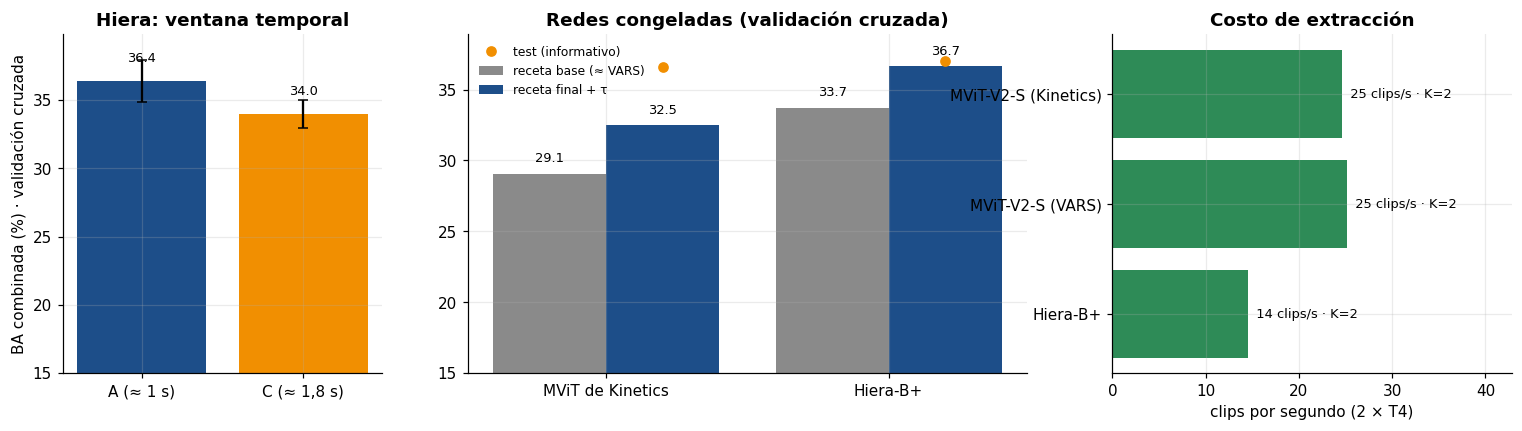

In [26]:
fig, axs = plt.subplots(1, 3, figsize=(17, 4), gridspec_kw={'width_ratios': [0.8, 1.4, 1]})
if 'hiera|ventana_A' in RES:
    xs = np.arange(2)
    b = axs[0].bar(xs, [RES[f'hiera|ventana_{e}']['oof']['lb'] for e in 'AC'], color=[COL['azul'], COL['naranja']])
    axs[0].errorbar(xs, [RES[f'hiera|ventana_{e}']['oof']['lb'] for e in 'AC'],
                    yerr=[np.nanstd(RES[f'hiera|ventana_{e}']['oof_folds']) for e in 'AC'], fmt='none', ecolor='k', capsize=3)
    etiquetar_barras(axs[0], b, dy=1.2)
    axs[0].set_xticks(xs); axs[0].set_xticklabels(['A (≈ 1 s)', 'C (≈ 1,8 s)']); axs[0].set_ylim(15, None)
    axs[0].set_title('Hiera: ventana temporal'); axs[0].set_ylabel('BA combinada (%) · validación cruzada')
else:
    axs[0].axis('off')
grupos = [(n, RES.get(kb), RES.get(kf)) for n, kb, kf in [('MViT de Kinetics', f'mvit|{RECETAS[0][0]}', f'mvit|{NOMBRE_L5}'),
                                                       ('Hiera-B+', 'hiera|base', 'hiera|final')] if kb in RES and kf in RES]
x = np.arange(len(grupos))
b1 = axs[1].bar(x - 0.2, [g[1]['oof']['lb'] for g in grupos], 0.4, color=COL['gris'], label='receta base (≈ VARS)')
b2 = axs[1].bar(x + 0.2, [g[2]['oof_tau']['lb'] for g in grupos], 0.4, color=COL['azul'], label='receta final + τ')
etiquetar_barras(axs[1], b1); etiquetar_barras(axs[1], b2)
axs[1].plot(x + 0.2, [g[2]['test_tau']['lb'] for g in grupos], 'o', color=COL['naranja'], label='test (informativo)')
axs[1].set_xticks(x); axs[1].set_xticklabels([g[0] for g in grupos]); axs[1].set_ylim(15, None)
axs[1].set_title('Redes congeladas (validación cruzada)'); axs[1].legend(fontsize=8)
inf = [(ENC[e]['nombre'], INFO_FEATS[e]) for e in ('mvit', 'mvit_vars', 'hiera') if e in INFO_FEATS]
bb = axs[2].barh([n for n, _ in inf], [i['clips_por_s'] for _, i in inf], color=COL['verde'])
for bi, (_, i) in zip(bb, inf):
    axs[2].text(bi.get_width(), bi.get_y() + bi.get_height() / 2, f"  {i['clips_por_s']:.0f} clips/s · K={i['K']}", va='center', fontsize=8.5)
axs[2].invert_yaxis(); axs[2].set_xlabel('clips por segundo (2 × T4)'); axs[2].set_title('Costo de extracción')
axs[2].set_xlim(0, max([i['clips_por_s'] for _, i in inf] + [1]) * 1.7)
guardar_fig(fig, '12_hiera_y_redes')

**Lectura: Hiera-B+.**
- **Ventana:** en validación cruzada ganó la A (36,4 contra 34,0), así que se usó la A. En el test la C dio más (39,4 contra 34,7), pero eso no se puede usar para escoger. Es un ejemplo de lo ruidosa que es la selección con pocas jugadas.
- **Hiera es el mejor codificador congelado:** 36,7 en validación cruzada con la receta final, contra 32,5 del MViT de Kinetics (+4,2).
- **La receta final también le sirve a Hiera:** pasa de 33,7 (receta base) a 36,7 (+3,0). Esto confirma lo de la escalera en otra red.
- Con el protocolo oficial, Hiera congelado da 34,9 en el test sin τ y 32,2 con τ.

---


## 17. Ajuste fino y segunda etapa

El orden protege lo más valioso si el tiempo no alcanza:
1. MViT desde VARS (ajuste completo).
2. Hiera-B+ (ajuste parcial).
3. Segunda etapa de ambos.
4. El control, MViT desde Kinetics (ajuste completo).

Cada ajuste recibe el tiempo que queda menos lo que necesitan los siguientes.

In [27]:
a = CFG['ajuste']
with fase('10. Ajuste completo desde VARS', opcional=True):
    if not (ACTIVO['ajuste'] and 'vars_cong' in RES):
        raise RuntimeError('falta el ajuste fino o la cabeza sobre VARS congelado')
    tope = min(a['min_vars'], quedan_min() - CFG['reserva_min'] - 200)      # deja tiempo para Hiera y la segunda etapa
    if tope < 30:
        raise SinTiempo('no alcanza el tiempo')
    RES['ft_vars'] = ajustar_fino('MViT desde VARS · ajuste completo', 'mvit_vars', 'completo', RECETA_FINAL,
                                  RES['vars_cong']['estados'][0], tope, a['lr_vars'], a['lr_cabeza'], a['epocas_vars'], esquema='A')

with fase('11. Ajuste parcial de Hiera-B+', opcional=True):
    if not (ACTIVO['ajuste'] and 'hiera_cong' in RES):
        raise RuntimeError('falta el ajuste fino o la cabeza sobre Hiera congelado')
    tope = min(a['min_hiera'], quedan_min() - CFG['reserva_min'] - 70)
    if tope < 30:
        raise SinTiempo('no alcanza el tiempo')
    RES['ft_hiera'] = ajustar_fino('Hiera-B+ · ajuste parcial', 'hiera', 'parcial', RECETA_FINAL, RES['hiera_cong']['estados'][0],
                                   tope, a['lr_hiera'], a['lr_cabeza'], a['epocas_hiera'], n_bloques=a['bloques_hiera'],
                                   esquema=ESQ_HIERA)

for clave, nombre in [('ft_vars', 'MViT desde VARS + segunda etapa'), ('ft_hiera', 'Hiera-B+ + segunda etapa')]:
    with fase(f'12. Segunda etapa · {nombre}', opcional=True):
        if clave not in RES:
            raise RuntimeError('no hay modelo afinado')
        if not hay_tiempo(20):
            raise SinTiempo('no alcanza el tiempo')
        RES['e2_' + clave[3:]] = etapa2(nombre, RES[clave])

with fase('13. Ajuste completo desde Kinetics (control)', opcional=True):
    if not (ACTIVO['ajuste'] and 'mvit_cong' in RES):
        raise RuntimeError('falta el ajuste fino o la cabeza sobre MViT congelado')
    tope = min(a['min_mvit'], quedan_min() - CFG['reserva_min'] - 10)
    if tope < 30:
        raise SinTiempo('no alcanza el tiempo')
    RES['ft_mvit'] = ajustar_fino('MViT desde Kinetics · ajuste completo', 'mvit', 'completo', RECETA_FINAL,
                                  RES['mvit_cong']['estados'][0], tope, a['lr_mvit'], a['lr_cabeza'], a['epocas_mvit'], esquema='A')


10. Ajuste completo desde VARS   (minuto 102, quedan 558 min)
MViT desde VARS · ajuste completo: 34.2 M parámetros entrenables del codificador; 2913 jugadas de entrenamiento; tope 140 min
  época 1: pérdida 2.437 | valid 36.2 | 12.0 min
  época 2: pérdida 2.420 | valid 37.1 | 12.0 min
  época 3: pérdida 2.364 | valid 36.3 | 12.0 min
  época 4: pérdida 2.265 | valid 40.2 | 12.0 min
  época 5: pérdida 2.275 | valid 37.1 | 12.0 min
  época 6: pérdida 2.197 | valid 36.8 | 12.0 min
  época 7: pérdida 2.186 | valid 37.5 | 12.0 min
MViT desde VARS · ajuste completo            valid  40.3 | +τ  40.3 | test  38.2 | +τ  38.2
MViT desde VARS · ajuste completo: mejor época 4 | 86 min

11. Ajuste parcial de Hiera-B+   (minuto 189, quedan 471 min)
Hiera-B+ · ajuste parcial: 49.9 M parámetros entrenables del codificador; 2913 jugadas de entrenamiento; tope 150 min
  época 1: pérdida 3.092 | valid 34.5 | 12.1 min
  época 2: pérdida 2.955 | valid 42.9 | 12.1 min
  época 3: pérdida 2.822 | valid 37.5 |

,origen,nivel,valid,test,ba_tipo,ba_sancion
0,MViT de Kinetics,congelado,31.9,31.0,32.1,29.9
1,MViT de Kinetics,ajuste completo,37.2,35.4,37.1,33.8
2,MViT de VARS,congelado,44.1,36.1,41.3,30.9
3,MViT de VARS,ajuste completo,40.3,38.2,41.7,34.7
4,MViT de VARS,+ segunda etapa,43.5,32.0,31.9,32.1
5,Hiera-B+,congelado,39.8,32.2,30.8,33.6
6,Hiera-B+,ajuste parcial,47.6,35.3,36.1,34.5
7,Hiera-B+,+ segunda etapa,53.0,39.8,41.2,38.3


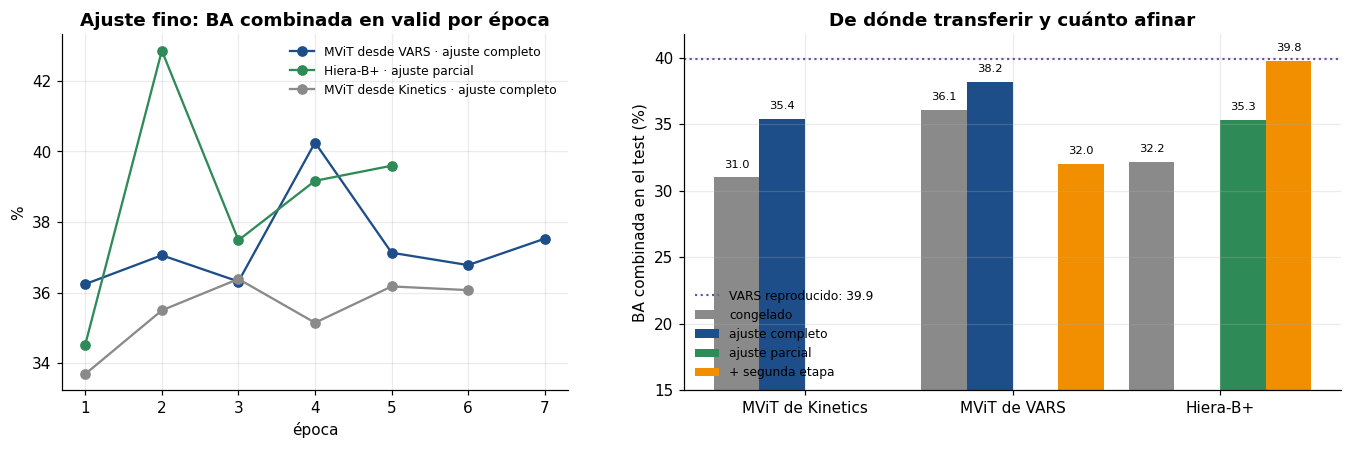

In [28]:
FILAS_T = [('MViT de Kinetics', 'congelado', 'mvit_cong'), ('MViT de Kinetics', 'ajuste completo', 'ft_mvit'),
           ('MViT de VARS', 'congelado', 'vars_cong'), ('MViT de VARS', 'ajuste completo', 'ft_vars'),
           ('MViT de VARS', '+ segunda etapa', 'e2_vars'),
           ('Hiera-B+', 'congelado', 'hiera_cong'), ('Hiera-B+', 'ajuste parcial', 'ft_hiera'), ('Hiera-B+', '+ segunda etapa', 'e2_hiera')]
tab_t = pd.DataFrame([dict(origen=o, nivel=n, valid=RES[k]['va_tau']['lb'], test=RES[k]['test_tau']['lb'],
                           ba_tipo=RES[k]['test_tau']['ba_act'], ba_sancion=RES[k]['test_tau']['ba_sev'])
                      for o, n, k in FILAS_T if k in RES])
tab_t.to_csv(TAB / 'transferencia.csv', index=False)
display(tab_t.round(1))

ft = [RES[k] for k in ('ft_vars', 'ft_hiera', 'ft_mvit') if k in RES]
fig, axs = plt.subplots(1, 2, figsize=(15, 4.2), gridspec_kw={'width_ratios': [1, 1.3]})
for r, c in zip(ft, [COL['azul'], COL['verde'], COL['gris']]):
    ep = [h['ep'] for h in r['hist']]
    axs[0].plot(ep, [h['lb_va'] for h in r['hist']], 'o-', color=c, label=r['nombre'])
axs[0].set_title('Ajuste fino: BA combinada en valid por época'); axs[0].set_xlabel('época'); axs[0].set_ylabel('%')
if ft:
    axs[0].legend(fontsize=8)
origenes = list(dict.fromkeys(tab_t.origen)) if len(tab_t) else []
niveles = ['congelado', 'ajuste completo', 'ajuste parcial', '+ segunda etapa']
colores = {'congelado': COL['gris'], 'ajuste completo': COL['azul'], 'ajuste parcial': COL['verde'], '+ segunda etapa': COL['naranja']}
ancho = 0.22
for j, nv in enumerate(niveles):
    sub = tab_t[tab_t.nivel == nv]
    if len(sub):
        xs = [origenes.index(o) + (j - 1.5) * ancho for o in sub.origen]
        b = axs[1].bar(xs, sub.test, ancho, color=colores[nv], label=nv)
        etiquetar_barras(axs[1], b, size=7.5)
if 'vars' in RES:
    axs[1].axhline(RES['vars']['test']['lb'], color=COL['morado'], ls=':', lw=1.4, label=f'VARS reproducido: {RES["vars"]["test"]["lb"]:.1f}')
axs[1].set_xticks(range(len(origenes))); axs[1].set_xticklabels(origenes); axs[1].set_ylim(15, None)
axs[1].set_ylabel('BA combinada en el test (%)'); axs[1].set_title('De dónde transferir y cuánto afinar'); axs[1].legend(fontsize=8)
guardar_fig(fig, '13_transferencia')

**Lectura: ajuste fino y segunda etapa.**

| Codificador | Congelado | Afinado | + Segunda etapa |
|---|---|---|---|
| MViT de Kinetics | 31,0 | 35,4 (+4,4) | – |
| MViT de VARS | 36,1 | 38,2 (+2,1) | 32,0 (38,4 sin τ) |
| Hiera-B+ | 32,2 | 35,3 (+3,1) | **39,8 (+4,5)** |

- **Afinar siempre ayuda**, y más cuanto más lejos está la red del problema: +4,4 desde Kinetics, +2,1 desde VARS (que ya vio faltas).
- **La segunda etapa funcionó en Hiera** (+4,5) **pero no en VARS.** En VARS la daña sobre todo el ajuste τ: sin τ da 38,4, con τ 32,0.
- **Las curvas de valid saltan mucho entre épocas** (Hiera: 34,5 → 42,9 → 37,5). Las mejores épocas fueron tempranas (2 a 4) y los ajustes pararon por paciencia, no por tiempo. Con 321 jugadas y 3 rojas, valid es ruidosa y la época escogida puede ser en parte suerte.
- Cada época toma unos 12 minutos en 2 × T4.

---


## 18. Ensamble y evaluación final en el test

El ensamble se escoge en valid de forma voraz: se agrega el modelo que más baja la **pérdida logarítmica balanceada**. Es un criterio más suave que la exactitud balanceada, que con 3 rojas en valid salta mucho. Con valid también se fijan τ y la temperatura.

**Nota:** el VARS original usó valid para escoger su época, así que en valid puede verse algo mejor de lo que es. El test se mira una sola vez, con todo ya decidido.

In [29]:
with fase('14. Ensamble y test final'):
    NOMBRES = {'vars_tta': 'VARS original + TTA', 'mvit_cong': 'MViT Kinetics congelado', 'vars_cong': 'MViT VARS congelado',
               'hiera_cong': 'Hiera-B+ congelado', 'ft_mvit': 'MViT Kinetics afinado', 'ft_vars': 'MViT VARS afinado',
               'e2_vars': 'MViT VARS afinado + 2.ª etapa', 'ft_hiera': 'Hiera-B+ afinado', 'e2_hiera': 'Hiera-B+ afinado + 2.ª etapa'}
    cands = {n: RES[k] for k, n in NOMBRES.items() if k in RES}
    sel, costo = elegir_ensamble(cands, VALID_OF)
    print('Miembros del ensamble (pueden repetirse, eso les da más peso):', sel, f'| pérdida balanceada en valid {costo:.3f}')
    ENS = resultado_oficial('Ensamble final', VALID_OF, promedio(cands, sel, 'va_a'), promedio(cands, sel, 'va_s'),
                            TEST, promedio(cands, sel, 'test_a'), promedio(cands, sel, 'test_s'), miembros=sel)
    lv = LIMPIA[VALID_OF]
    ENS['T_act'] = ajustar_T(ENS['va_a'][lv], Y_ACT_OF[VALID_OF][lv])
    ENS['T_sev'] = ajustar_T(ENS['va_s'][lv], Y_SEV_OF[VALID_OF][lv])
    RES['ensamble'] = ENS

    it = POS_TEST_LIMPIA; gl = TEST[it]; ya, ys = Y_ACT_OF[gl], Y_SEV_OF[gl]
    PRED = {}
    def fila(nombre, pa, ps, tau, ref=None):
        ha = ajuste_logits(pa[it], tau[0], PRIOR_ACT).argmax(1); hs = ajuste_logits(ps[it], tau[1], PRIOR_SEV).argmax(1)
        PRED[nombre] = (ha, hs)
        m = metricas(ya, ys, pa[it], ps[it], tau)
        bs = bootstrap_lb(ya, ys, ha, hs, ref=ref)
        return dict(modelo=nombre, **{k: round(v, 1) for k, v in m.items()},
                    **{k: (round(v, 3) if k == 'p_mejor' else round(v, 1)) for k, v in bs.items()})
    filas = [dict(modelo='VARS (paper 2024)', **VARS_PAPER)]
    if 'vars' in RES:
        filas.append(fila('VARS reproducido', RES['vars']['test_a'], RES['vars']['test_s'], (0.0, 0.0)))
    ref = PRED.get('VARS reproducido')
    if 'vars_tta' in RES:
        filas.append(fila('VARS reproducido + TTA', RES['vars_tta']['test_a'], RES['vars_tta']['test_s'], (0.0, 0.0), ref))
    for k, n in NOMBRES.items():
        if k in RES and k != 'vars_tta':
            filas.append(fila(n, RES[k]['test_a'], RES[k]['test_s'], RES[k]['tau'], ref))
    filas.append(fila('Ensamble final', ENS['test_a'], ENS['test_s'], ENS['tau'], ref))
    TAB_FINAL = pd.DataFrame(filas)
    TAB_FINAL.to_csv(TAB / 'resultados_test.csv', index=False)
    display(TAB_FINAL)

    ha_t = ajuste_logits(ENS['test_a'], ENS['tau'][0], PRIOR_ACT).argmax(1)
    hs_t = ajuste_logits(ENS['test_s'], ENS['tau'][1], PRIOR_SEV).argmax(1)
    escribir_predicciones(OUT / 'predicciones_test_ensamble.json', TEST, ha_t, hs_t)
    ENS['oficial'] = evaluar_oficial(ANOT / 'test.json', OUT / 'predicciones_test_ensamble.json')
    print('Métrica oficial de SoccerNet sobre el ensamble:', {k: round(v, 2) for k, v in ENS['oficial'].items()})


14. Ensamble y test final   (minuto 382, quedan 278 min)
Miembros del ensamble (pueden repetirse, eso les da más peso): ['Hiera-B+ afinado + 2.ª etapa'] | pérdida balanceada en valid 2.502
Ensamble final                               valid  53.0 | +τ  53.0 | test  39.8 | +τ  39.8


,modelo,acc_act,ba_act,acc_sev,ba_sev,lb,ic_bajo,ic_alto,dif_bajo,dif_alto,p_mejor
0,VARS (paper 2024),50.0,41.0,46.0,34.0,37.5,NaN,NaN,NaN,NaN,NaN
1,VARS reproducido,55.0,43.9,36.3,35.9,39.9,33.2,47.4,NaN,NaN,NaN
2,VARS reproducido + TTA,55.0,43.9,36.7,36.7,40.3,33.6,47.9,-0.8,1.6,0.735
3,MViT Kinetics congelado,15.9,32.1,13.9,29.9,31.0,21.7,38.1,-19.4,0.6,0.030
4,MViT VARS congelado,50.6,41.3,32.3,30.9,36.1,31.3,40.8,-11.1,2.1,0.113
5,Hiera-B+ congelado,13.1,30.8,41.4,33.6,32.2,26.8,36.9,-16.3,-0.4,0.018
6,MViT Kinetics afinado,39.0,37.1,51.8,33.8,35.4,30.1,41.4,-11.6,2.4,0.107
7,MViT VARS afinado,52.6,41.7,47.0,34.7,38.2,32.9,43.8,-8.9,3.9,0.309
8,MViT VARS afinado + 2.ª etapa,20.3,31.9,26.7,32.1,32.0,23.8,40.6,-14.7,0.2,0.028
9,Hiera-B+ afinado,33.1,36.1,48.6,34.5,35.3,30.1,41.1,-12.3,2.5,0.110


Métrica oficial de SoccerNet sobre el ensamble: {'accuracy_offence_severity': np.float64(51.39), 'accuracy_action': np.float64(47.01), 'balanced_accuracy_offence_severity': np.float64(38.35), 'balanced_accuracy_action': np.float64(41.16), 'leaderboard_value': np.float64(39.75)}


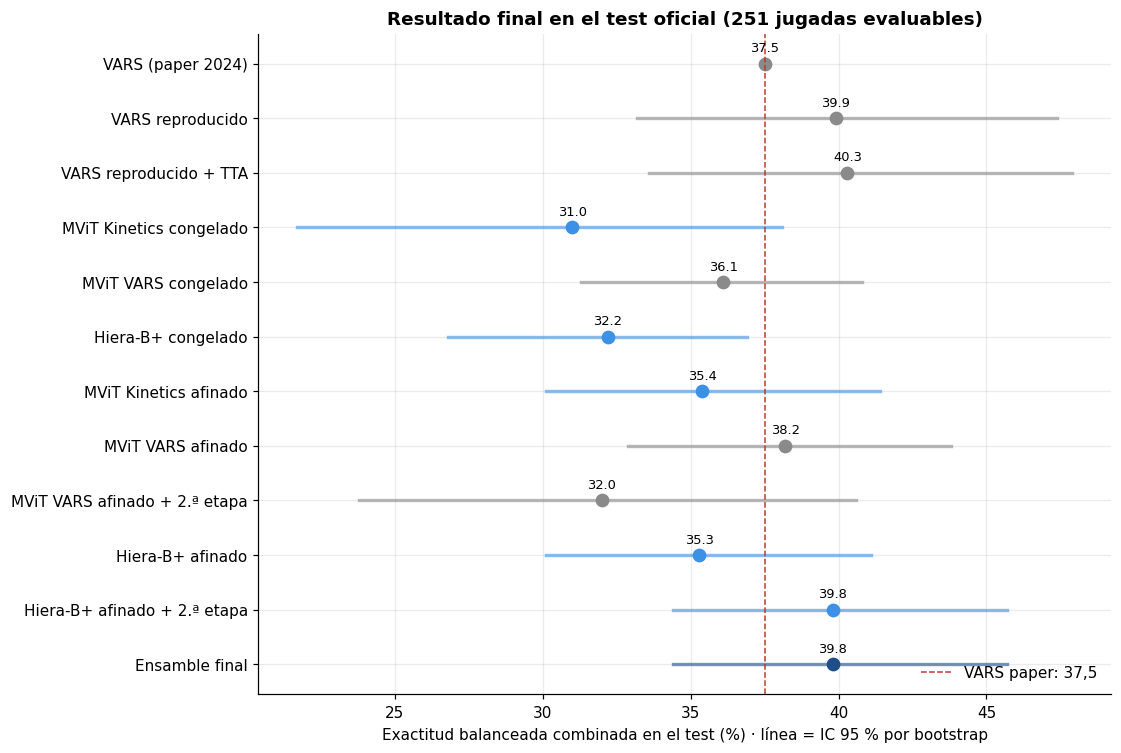

VARS reproducido + TTA           − VARS reproducido: IC 95 % [-0.8, +1.6] puntos; mejor en el 74 % de los remuestreos
MViT Kinetics congelado          − VARS reproducido: IC 95 % [-19.4, +0.6] puntos; mejor en el 3 % de los remuestreos
MViT VARS congelado              − VARS reproducido: IC 95 % [-11.1, +2.1] puntos; mejor en el 11 % de los remuestreos
Hiera-B+ congelado               − VARS reproducido: IC 95 % [-16.3, -0.4] puntos; mejor en el 2 % de los remuestreos
MViT Kinetics afinado            − VARS reproducido: IC 95 % [-11.6, +2.4] puntos; mejor en el 11 % de los remuestreos
MViT VARS afinado                − VARS reproducido: IC 95 % [-8.9, +3.9] puntos; mejor en el 31 % de los remuestreos
MViT VARS afinado + 2.ª etapa    − VARS reproducido: IC 95 % [-14.7, +0.2] puntos; mejor en el 3 % de los remuestreos
Hiera-B+ afinado                 − VARS reproducido: IC 95 % [-12.3, +2.5] puntos; mejor en el 11 % de los remuestreos
Hiera-B+ afinado + 2.ª etapa     − VARS reproducido: 

In [30]:
t = TAB_FINAL.copy()
fig, ax = plt.subplots(figsize=(10, 0.55 * len(t) + 1.2))
y = np.arange(len(t))[::-1]
for yi, (_, r) in zip(y, t.iterrows()):
    c = COL['azul'] if r.modelo == 'Ensamble final' else (COL['gris'] if 'VARS' in r.modelo else COL['celeste'])
    if pd.notna(r.get('ic_bajo', np.nan)):
        ax.plot([r.ic_bajo, r.ic_alto], [yi, yi], color=c, lw=2.2, alpha=0.6)
    ax.plot(r.lb, yi, 'o', color=c, ms=8)
    ax.text(r.lb, yi + 0.22, f'{r.lb:.1f}', ha='center', fontsize=8.5)
ax.axvline(VARS_PAPER['lb'], color=COL['rojo'], ls='--', lw=1, label='VARS paper: 37,5')
ax.set_yticks(y); ax.set_yticklabels(t.modelo); ax.set_xlabel('Exactitud balanceada combinada en el test (%) · línea = IC 95 % por bootstrap')
ax.set_title(f'Resultado final en el test oficial ({len(POS_TEST_LIMPIA)} jugadas evaluables)'); ax.legend(loc='lower right')
guardar_fig(fig, '14_resultado_final')
if 'dif_bajo' in TAB_FINAL.columns:
    for _, e in TAB_FINAL.dropna(subset=['dif_bajo']).iterrows():
        print(f'{e.modelo:<32} − VARS reproducido: IC 95 % [{e.dif_bajo:+.1f}, {e.dif_alto:+.1f}] puntos; '
              f'mejor en el {100 * e.p_mejor:.0f} % de los remuestreos')

**Lectura: resultado final.**
- **El ensamble se quedó con un solo modelo,** Hiera-B+ afinado + segunda etapa: agregar cualquier otro no bajaba la pérdida en valid.
- **Empate con VARS:** 39,8 (IC 34,4–45,7) contra 39,9 (IC 33,2–47,4). La diferencia está entre −8,6 y +8,1 puntos, y Hiera gana en el 50 % de los remuestreos.
- **Cada uno es mejor en una tarea:**
  - en la sanción, Hiera: BA 38,3 contra 35,9 y exactitud 51,4 % contra 36,3 %;
  - en el tipo de falta, VARS: BA 43,9 contra 41,2 y exactitud 55,0 % contra 47,0 %.
- **Por qué el intervalo es tan ancho:** el test tiene 251 jugadas evaluables y 5 rojas. Una sola roja acertada mueve 2,5 puntos la métrica combinada.
- **Valid fue optimista:** 53,0 en valid contra 39,8 en el test. Las decisiones tomadas con valid se ajustaron en parte a su ruido.
- Los dos modelos superan el 37,5 del paper, pero VARS reproducido también lo supera, así que ese número no es la comparación justa.

---


## 19. Análisis de errores y confianza

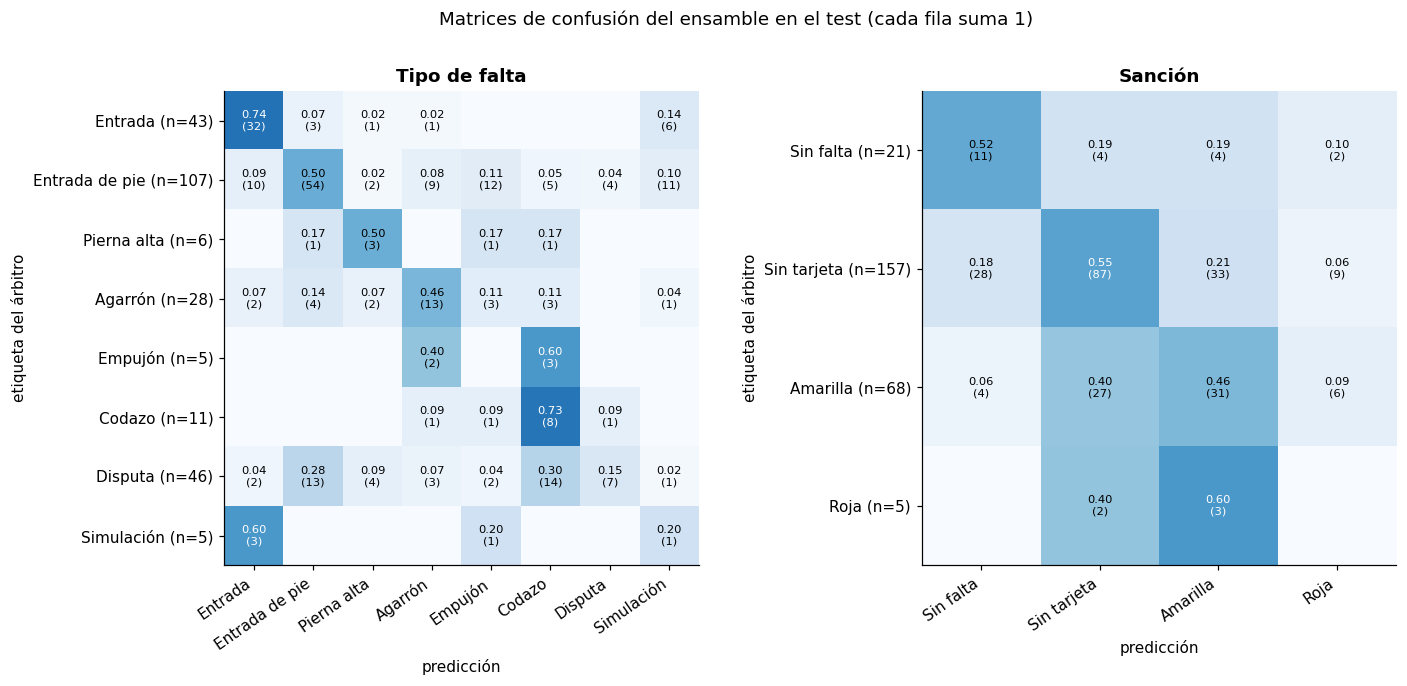

In [31]:
# ---------- Matrices de confusión del ensamble ----------
from sklearn.metrics import confusion_matrix
ha, hs = PRED['Ensamble final']
it = POS_TEST_LIMPIA; gl = TEST[it]
fig, axs = plt.subplots(1, 2, figsize=(15, 5.6), gridspec_kw={'width_ratios': [1.45, 1]})
for ax, y, h, nombres, titulo in [(axs[0], Y_ACT_OF[gl], ha, ACC_ES, 'Tipo de falta'), (axs[1], Y_SEV_OF[gl], hs, SEV_ES, 'Sanción')]:
    cm = confusion_matrix(y, h, labels=range(len(nombres)))
    cmn = cm / np.maximum(cm.sum(1, keepdims=True), 1)
    ax.imshow(cmn, cmap='Blues', vmin=0, vmax=1)
    for i in range(len(nombres)):
        for j in range(len(nombres)):
            if cm[i, j]:
                ax.text(j, i, f'{cmn[i, j]:.2f}\n({cm[i, j]})', ha='center', va='center', fontsize=7.5,
                        color='white' if cmn[i, j] > 0.55 else 'black')
    ax.set_xticks(range(len(nombres))); ax.set_xticklabels(nombres, rotation=35, ha='right')
    ax.set_yticks(range(len(nombres))); ax.set_yticklabels([f'{n} (n={c})' for n, c in zip(nombres, cm.sum(1))])
    ax.set_xlabel('predicción'); ax.set_ylabel('etiqueta del árbitro'); ax.set_title(titulo); ax.grid(False)
fig.suptitle('Matrices de confusión del ensamble en el test (cada fila suma 1)', y=1.01)
guardar_fig(fig, '15_confusiones')

**Lectura: matrices de confusión.**
- **Tipo de falta:** acierta bien la entrada (74 %) y el codazo (73 %), y regular la entrada de pie (50 %), la pierna alta (3 de 6) y el agarrón (46 %).
- **La disputa casi nunca la acierta** (15 %): la confunde con codazo (30 %) y con entrada de pie (28 %). Tiene sentido, porque una disputa es un choque de cuerpos sin un gesto claro.
- **Simulación:** 3 de 5 las toma por una entrada. Lo que las distingue es si hubo contacto, y eso es justo lo difícil de ver.
- **Empujón:** 0 de 5; los confunde con codazo y agarrón. Los gestos con los brazos se mezclan entre sí.
- **Sanción:** acierta el 52 % de las «sin falta», el 55 % de las «sin tarjeta» y el 46 % de las amarillas (el 40 % de las amarillas las baja a sin tarjeta).
- **Rojas: 0 de 5** (3 como amarilla y 2 como sin tarjeta). Con 27 rojas de entrenamiento el modelo no aprendió a reconocerlas.
- **Casi todos los errores de la sanción caen en la clase vecina** (amarilla ↔ sin tarjeta). Es el mismo tipo de desacuerdo que hay entre árbitros.

---


### Una cámara contra varias

Simula lo que pasaría con un video cualquiera de internet, donde solo está la toma en vivo. Se usa la mejor cabeza sobre características guardadas (escogida en valid), que se entrenó quitando cámaras al azar.

Cabeza usada en los análisis: Hiera-B+ + segunda etapa

15. Una cámara contra varias   (minuto 383, quedan 277 min)


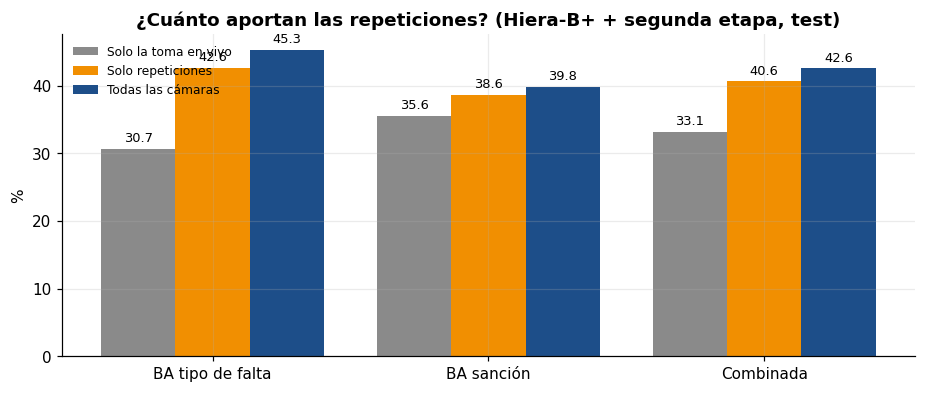

In [32]:
def feats_de(clave):
    r = RES[clave]
    if 'feats' in r:
        return r['feats'][0]
    return {'vars_cong': FEATS_MEM.get('mvit_vars_A'), 'hiera_cong': FEATS_MEM.get('hiera'), 'mvit_cong': FEATS_MEM.get('mvit_A')}[clave]

CLAVE_H = max([k for k in ('e2_vars', 'e2_hiera', 'vars_cong', 'hiera_cong', 'mvit_cong') if k in RES],
              key=lambda k: RES[k]['va_tau']['lb'])
print('Cabeza usada en los análisis:', RES[CLAVE_H]['nombre'])

with fase('15. Una cámara contra varias', opcional=True):
    it = POS_TEST_LIMPIA; gl = TEST[it]
    VISTAS = {}
    for modo, nombre in [('vivo', 'Solo la toma en vivo'), ('repeticiones', 'Solo repeticiones'), ('todas', 'Todas las cámaras')]:
        pa, ps, _ = predecir_cv(RES[CLAVE_H], feats_de(CLAVE_H), TEST, modo)
        VISTAS[nombre] = metricas(Y_ACT_OF[gl], Y_SEV_OF[gl], pa[it], ps[it], RES[CLAVE_H]['tau'])
    fig, ax = plt.subplots(figsize=(10, 3.8))
    ks, lbl, x = ['ba_act', 'ba_sev', 'lb'], ['BA tipo de falta', 'BA sanción', 'Combinada'], np.arange(3)
    for j, (nombre, m) in enumerate(VISTAS.items()):
        b = ax.bar(x + (j - 1) * 0.27, [m[k] for k in ks], 0.27, color=[COL['gris'], COL['naranja'], COL['azul']][j], label=nombre)
        etiquetar_barras(ax, b)
    ax.set_xticks(x); ax.set_xticklabels(lbl); ax.set_ylabel('%'); ax.set_ylim(0, None)
    ax.set_title(f'¿Cuánto aportan las repeticiones? ({RES[CLAVE_H]["nombre"]}, test)'); ax.legend(fontsize=8)
    guardar_fig(fig, '16_una_vs_varias_camaras')
    pd.DataFrame(VISTAS).T.round(1).to_csv(TAB / 'una_vs_varias_camaras.csv')

**Lectura: una cámara contra varias.** BA combinada: solo la toma en vivo 33,1, solo las repeticiones 40,6, todas las cámaras 42,6.
- **Las repeticiones son lo que más informa:** solas sacan 7,5 puntos más que la toma en vivo. Coincide con el peso que les da el modelo (más abajo).
- Usar todas las cámaras juntas suma 2 puntos más sobre las repeticiones solas.
- **Con un video cualquiera de internet,** donde solo está la toma en vivo, el modelo perdería cerca de 9,5 puntos.
- *Nota:* esta prueba usa solo las características sin voltear; por eso «todas las cámaras» da 42,6 y no 39,8. Que sin espejo dé más sugiere que el TTA en espejo no le sirvió a este modelo, aunque la diferencia cabe dentro del ruido.

---


### Calibración y abstención

Un asistente VAR útil no tiene que decidir siempre. Puede responder solo cuando está seguro y dejar el resto al árbitro, parecido al criterio de «error claro y obvio». A la izquierda se ve si su confianza es honesta; a la derecha, cuánto sube la exactitud si responde solo en las jugadas donde está más seguro.


14. Calibración y abstención   (minuto 383, quedan 277 min)


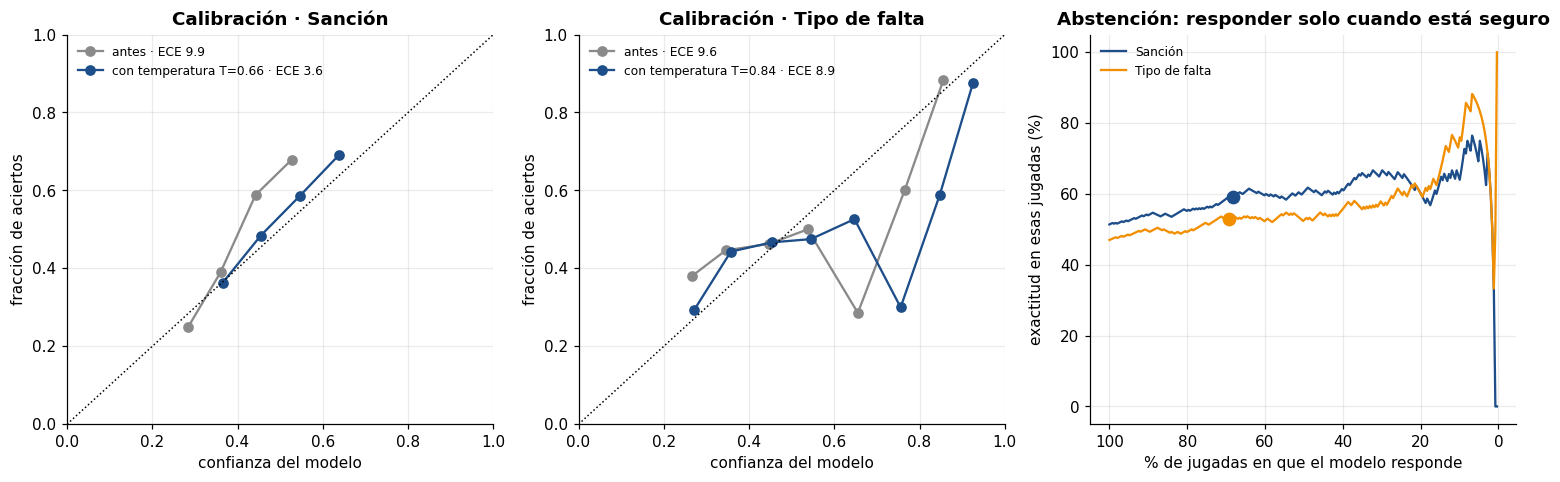

,umbral,cobertura,exactitud_respondidas,exactitud_todas
Sanción,0.44,68.13,59.06,51.39
Tipo de falta,0.37,69.32,52.87,47.01


In [33]:
with fase('14. Calibración y abstención', opcional=True):
    it = POS_TEST_LIMPIA; gl = TEST[it]
    fig, axs = plt.subplots(1, 3, figsize=(17, 4.6))
    for ax, p, y, T, titulo in [(axs[0], ENS['test_s'][it], Y_SEV_OF[gl], ENS['T_sev'], 'Sanción'),
                                (axs[1], ENS['test_a'][it], Y_ACT_OF[gl], ENS['T_act'], 'Tipo de falta')]:
        for q, c, nombre in [(p, COL['gris'], 'antes'), (con_T(p, T), COL['azul'], f'con temperatura T={T:.2f}')]:
            conf, ok = q.max(1), q.argmax(1) == y
            bordes = np.linspace(0, 1, 11); xs, ys = [], []
            for a, b in zip(bordes[:-1], bordes[1:]):
                s = (conf > a) & (conf <= b)
                if s.sum() >= 3:
                    xs.append(conf[s].mean()); ys.append(ok[s].mean())
            ax.plot(xs, ys, 'o-', color=c, label=f'{nombre} · ECE {ece(q, y):.1f}')
        ax.plot([0, 1], [0, 1], 'k:', lw=1)
        ax.set_xlabel('confianza del modelo'); ax.set_ylabel('fracción de aciertos'); ax.set_title(f'Calibración · {titulo}')
        ax.legend(fontsize=8); ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    ABST = {}
    for p, y, T, tau, prior, nombre, c in [(ENS['test_s'][it], Y_SEV_OF[gl], ENS['T_sev'], ENS['tau'][1], PRIOR_SEV, 'Sanción', COL['azul']),
                                          (ENS['test_a'][it], Y_ACT_OF[gl], ENS['T_act'], ENS['tau'][0], PRIOR_ACT, 'Tipo de falta', COL['naranja'])]:
        q = con_T(p, T)
        cob, acc, _ = curva_cobertura(q, y, ajuste_logits(p, tau, prior).argmax(1))
        axs[2].plot(100 * cob, 100 * acc, color=c, label=nombre)
        # umbral escogido en valid para responder en el 70 % de las jugadas
        vap = ENS['va_s'] if nombre == 'Sanción' else ENS['va_a']
        umbral = np.quantile(con_T(vap[LIMPIA[VALID_OF]], T).max(1), 0.30)
        s = q.max(1) >= umbral
        pred = ajuste_logits(p, tau, prior).argmax(1)
        ABST[nombre] = dict(umbral=float(umbral), cobertura=100 * s.mean(), exactitud_respondidas=100 * (pred[s] == y[s]).mean(),
                            exactitud_todas=100 * (pred == y).mean())
        axs[2].plot(100 * s.mean(), ABST[nombre]['exactitud_respondidas'], 'o', color=c, ms=8)
    axs[2].set_xlabel('% de jugadas en que el modelo responde'); axs[2].set_ylabel('exactitud en esas jugadas (%)')
    axs[2].set_title('Abstención: responder solo cuando está seguro'); axs[2].legend(fontsize=8); axs[2].invert_xaxis()
    guardar_fig(fig, '17_calibracion_abstencion')
    display(pd.DataFrame(ABST).T.round(2))
    RES['abstencion'] = ABST

**Lectura: calibración y abstención.**
- **Sanción:** el modelo era poco confiado. La temperatura T = 0,66 (menor que 1) afila sus probabilidades y baja el error de calibración (ECE) de 9,9 a 3,6. Ahora, cuando dice 60 %, acierta cerca del 60 % de las veces.
- **Tipo de falta:** la temperatura casi no ayuda (ECE 9,6 → 8,9), y la curva sube y baja porque hay pocas jugadas en cada tramo.
- **Abstención:**
  - respondiendo en el 68 % de las jugadas, la exactitud de la sanción sube de **51,4 % a 59,1 %**;
  - respondiendo en el 69 %, la del tipo de falta sube de 47,0 % a 52,9 %;
  - respondiendo solo en el 20–30 % más seguro, la sanción ronda el 60–65 %.
- **Esta es la parte de «el VAR que sabe cuándo dudar»:** el modelo sirve como primer filtro, y las jugadas donde duda quedan para el árbitro.

---


### ¿Duda el modelo donde dudó el árbitro?

Las 49 jugadas de zona gris del test no cuentan en la métrica oficial, pero sirven para otra pregunta: si el modelo es honesto, debería estar **menos seguro** justo en esas jugadas. Se mide con la entropía de la predicción de la sanción y con el AUROC: 0,5 es azar y 1 es separar perfecto. Se compara un modelo entrenado sin las jugadas grises (L4) con uno entrenado con ellas como etiquetas suaves (L5).


15. Zona gris   (minuto 383, quedan 277 min)


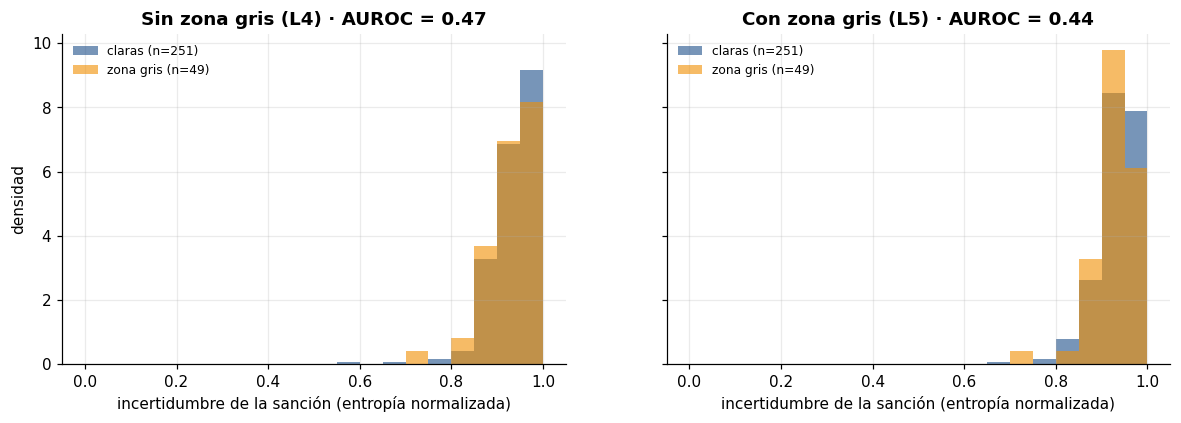

{'Sin zona gris (L4)': {'auroc': 0.466, 'entropia_gris': 0.931, 'entropia_claras': 0.937}, 'Con zona gris (L5)': {'auroc': 0.437, 'entropia_gris': 0.924, 'entropia_claras': 0.933}, 'ensamble_exactitud_flexible_gris': 81.63265306122449}


In [34]:
with fase('15. Zona gris', opcional=True):
    from sklearn.metrics import roc_auc_score
    gris_t = GRIS[TEST]; claras = LIMPIA[TEST]; s_eval = gris_t | claras
    def entropia(p):
        return -(p * np.log(p + 1e-9)).sum(1) / np.log(p.shape[1])
    fig, axs = plt.subplots(1, 2, figsize=(13, 3.9), sharey=True)
    ZG = {}
    for ax, (clave, nombre) in zip(axs, [(f'mvit|{RECETAS[4][0]}', 'Sin zona gris (L4)'), (f'mvit|{NOMBRE_L5}', 'Con zona gris (L5)')]):
        if clave not in RES:
            ax.axis('off'); continue
        h = entropia(RES[clave]['test_s'])
        auc = roc_auc_score(gris_t[s_eval], h[s_eval])
        ZG[nombre] = dict(auroc=float(auc), entropia_gris=float(h[gris_t].mean()), entropia_claras=float(h[claras].mean()))
        bins = np.linspace(0, 1, 21)
        ax.hist(h[claras], bins=bins, density=True, alpha=0.6, color=COL['azul'], label=f'claras (n={claras.sum()})')
        ax.hist(h[gris_t], bins=bins, density=True, alpha=0.6, color=COL['naranja'], label=f'zona gris (n={gris_t.sum()})')
        ax.set_title(f'{nombre} · AUROC = {auc:.2f}'); ax.set_xlabel('incertidumbre de la sanción (entropía normalizada)'); ax.legend(fontsize=8)
    axs[0].set_ylabel('densidad')
    guardar_fig(fig, '18_zona_gris')
    # Exactitud «flexible» en la zona gris: vale cualquiera de las decisiones que el árbitro consideró válidas
    gg = TEST[gris_t]
    hs_g = ajuste_logits(ENS['test_s'][gris_t], ENS['tau'][1], PRIOR_SEV).argmax(1)
    ZG['ensamble_exactitud_flexible_gris'] = float(100 * np.mean(Q_SEV[gg][np.arange(len(gg)), hs_g] > 0))
    print({k: (v if not isinstance(v, dict) else {a: round(b, 3) for a, b in v.items()}) for k, v in ZG.items()})
    RES['zona_gris'] = ZG

**Lectura: zona gris.**
- **El modelo no duda más donde dudó el árbitro.** El AUROC es 0,47 sin las jugadas grises (L4) y 0,44 con ellas (L5), igual que el azar (0,5).
- **El modelo está inseguro en casi todo:** la entropía media es 0,93 en las jugadas grises y 0,93–0,94 en las claras, sobre un máximo de 1.
- **Entrenar con la zona gris subió la métrica** (escalera, L5), **pero no le enseñó a dudar** en esas jugadas.
- **Exactitud flexible:** si en una jugada gris vale cualquiera de las dos decisiones que el árbitro consideró válidas, el modelo final acierta el **81,6 %**.
- *Limitación:* el AUROC se midió con el MViT de Kinetics congelado, el modelo más débil, y no con el modelo final.

---


### ¿A qué cámara le hace caso el modelo?

El transformer da un peso a cada cámara. Si el peso multiplicado por el número de cámaras vale más de 1, esa cámara pesa más que si el reparto fuera parejo.


16. Peso de cada cámara   (minuto 383, quedan 277 min)


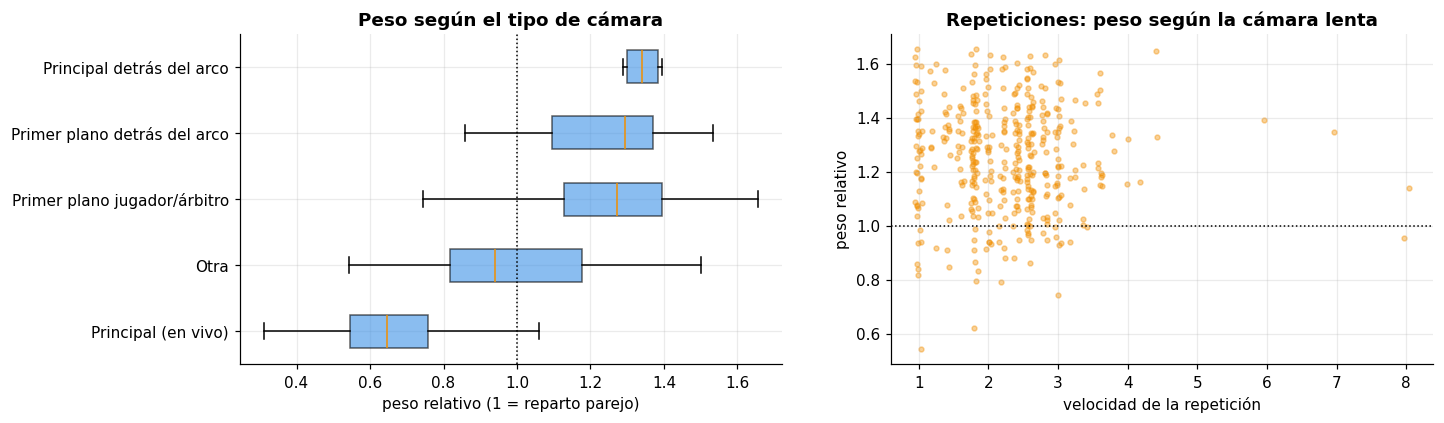

In [35]:
with fase('16. Peso de cada cámara', opcional=True):
    _, _, W = predecir_cv(RES[CLAVE_H], feats_de(CLAVE_H), TEST)
    filas = []
    for i, g in enumerate(TEST):
        slots = np.flatnonzero(A_CLIPS[g] >= 0)
        for s in slots:
            filas.append(dict(cam=CAM_ES[A_CAM[g, s]], vivo=bool(A_VIVO[g, s]), vel=float(A_VEL[g, s]),
                              peso_rel=float(W[i, s] * len(slots))))
    dfw = pd.DataFrame(filas)
    fig, axs = plt.subplots(1, 2, figsize=(14, 3.9))
    orden = dfw.groupby('cam').peso_rel.median().sort_values(ascending=False).index
    axs[0].boxplot([dfw[dfw.cam == c].peso_rel for c in orden], vert=False, showfliers=False,
                   patch_artist=True, boxprops=dict(facecolor=COL['celeste'], alpha=0.6))
    axs[0].set_yticks(range(1, len(orden) + 1)); axs[0].set_yticklabels(orden)
    axs[0].axvline(1, color='k', ls=':', lw=1); axs[0].invert_yaxis()
    axs[0].set_xlabel('peso relativo (1 = reparto parejo)'); axs[0].set_title('Peso según el tipo de cámara')
    rep = dfw[~dfw.vivo]
    axs[1].scatter(rep.vel + np.random.RandomState(0).uniform(-0.05, 0.05, len(rep)), rep.peso_rel, s=10, alpha=0.4, color=COL['naranja'])
    axs[1].axhline(1, color='k', ls=':', lw=1)
    axs[1].set_xlabel('velocidad de la repetición'); axs[1].set_ylabel('peso relativo'); axs[1].set_title('Repeticiones: peso según la cámara lenta')
    guardar_fig(fig, '19_peso_camaras')

**Lectura: peso de cada cámara.**
- **La toma principal en vivo pesa menos que el reparto parejo** (mediana ≈ 0,65). Los primeros planos y las cámaras detrás del arco pesan más (≈ 1,25–1,35).
- **El modelo aprendió solo a hacerle más caso a las repeticiones,** como un árbitro de VAR que pide la toma de cerca. Coincide con la prueba de una cámara contra varias.
- **La velocidad de la cámara lenta no cambia el peso:** la nube es plana entre 1× y 4×.

---


### Grad-CAM: dónde mira el MViT afinado desde VARS

In [36]:
with fase('17. Grad-CAM', opcional=True):
    if not ACTIVO['gradcam']:
        raise RuntimeError('desactivado en la prueba de humo')
    if 'ft_vars' in RES:
        cod, cab = RES['ft_vars']['modelo']; receta_cam, origen = RES['ft_vars']['receta'], RES['ft_vars']['nombre']
    else:
        clave = 'vars_cong' if 'vars_cong' in RES else 'mvit_cong'
        cod = Codificador('mvit_vars' if clave == 'vars_cong' else 'mvit')
        cab = nueva_cabeza(768, False, RES[clave]['receta']); cab.load_state_dict(RES[clave]['estados'][0])
        receta_cam, origen = RES[clave]['receta'], RES[clave]['nombre']
    hs = PRED['Ensamble final'][1]; gl = TEST[POS_TEST_LIMPIA]
    elegidas = []
    for cond in [lambda g, h: Y_SEV_OF[g] >= 2 and h == Y_SEV_OF[g], lambda g, h: Y_SEV_OF[g] >= 2 and h != Y_SEV_OF[g],
                 lambda g, h: Y_SEV_OF[g] <= 1 and h == Y_SEV_OF[g]]:
        c = [int(g) for g, h in zip(gl, hs) if cond(g, h) and int(g) not in elegidas]
        if c:
            elegidas.append(c[0])
    for g in elegidas:
        imgs, mapas, c, ps = gradcam_mvit(cod, cab, receta_cam, g, 'A')
        V = min(len(imgs), 3); tiempos = [3, 8, 12]
        fig, axs = plt.subplots(V, 3, figsize=(10, 3.3 * V), squeeze=False)
        for v in range(V):
            slot = np.flatnonzero(A_CLIPS[g] >= 0)[v]
            for k, tt in enumerate(tiempos):
                axs[v, k].imshow(imgs[v, tt]); axs[v, k].imshow(mapas[v, tt], cmap='jet', alpha=0.4, vmin=0, vmax=1)
                axs[v, k].axis('off')
                axs[v, k].set_title(f'{CAM_ES[A_CAM[g, slot]]} · fotograma {IDX_VARS[tt]}', fontsize=8)
        fig.suptitle(f'{origen} · jugada {ACTS.aid[g]}: árbitro = {SEV_ES[Y_SEV_OF[g]]} ({ACC_ES[Y_ACT_OF[g]]}), '
                     f'modelo = {SEV_ES[c]} ({100 * ps[c]:.0f} %)', y=1.0)
        guardar_fig(fig, f'20_gradcam_jugada_{ACTS.aid[g]}')
    cod.cpu(); del cab; torch.cuda.empty_cache()


17. Grad-CAM   (minuto 383, quedan 277 min)


[Figura retirada de la versión pública: muestra fotogramas de los videos de SoccerNet-MVFoul, protegidos por NDA.]


[Figura retirada de la versión pública: muestra fotogramas de los videos de SoccerNet-MVFoul, protegidos por NDA.]


[Figura retirada de la versión pública: muestra fotogramas de los videos de SoccerNet-MVFoul, protegidos por NDA.]


**Lectura: Grad-CAM.**
- **Los mapas (retirados de esta versión por el NDA) salieron prácticamente planos:** el color era uniforme y no resalta ninguna zona del fotograma. Con estas figuras **no se puede concluir dónde mira la red**. Es probable que el gradiente casi no llegue a los tokens del último bloque de MViT; queda como pendiente técnico.
- **Lo que sí muestran los ejemplos:**
  - En la jugada 1 (codazo con amarilla), el modelo dijo «sin falta» con solo 32 % de confianza. En la toma en vivo los jugadores son diminutos, y el brazo solo se ve en el primer plano.
  - En la jugada 2 (entrada de pie, sin tarjeta) acertó con 58 %.

---


## 20. Recursos usados y guardado

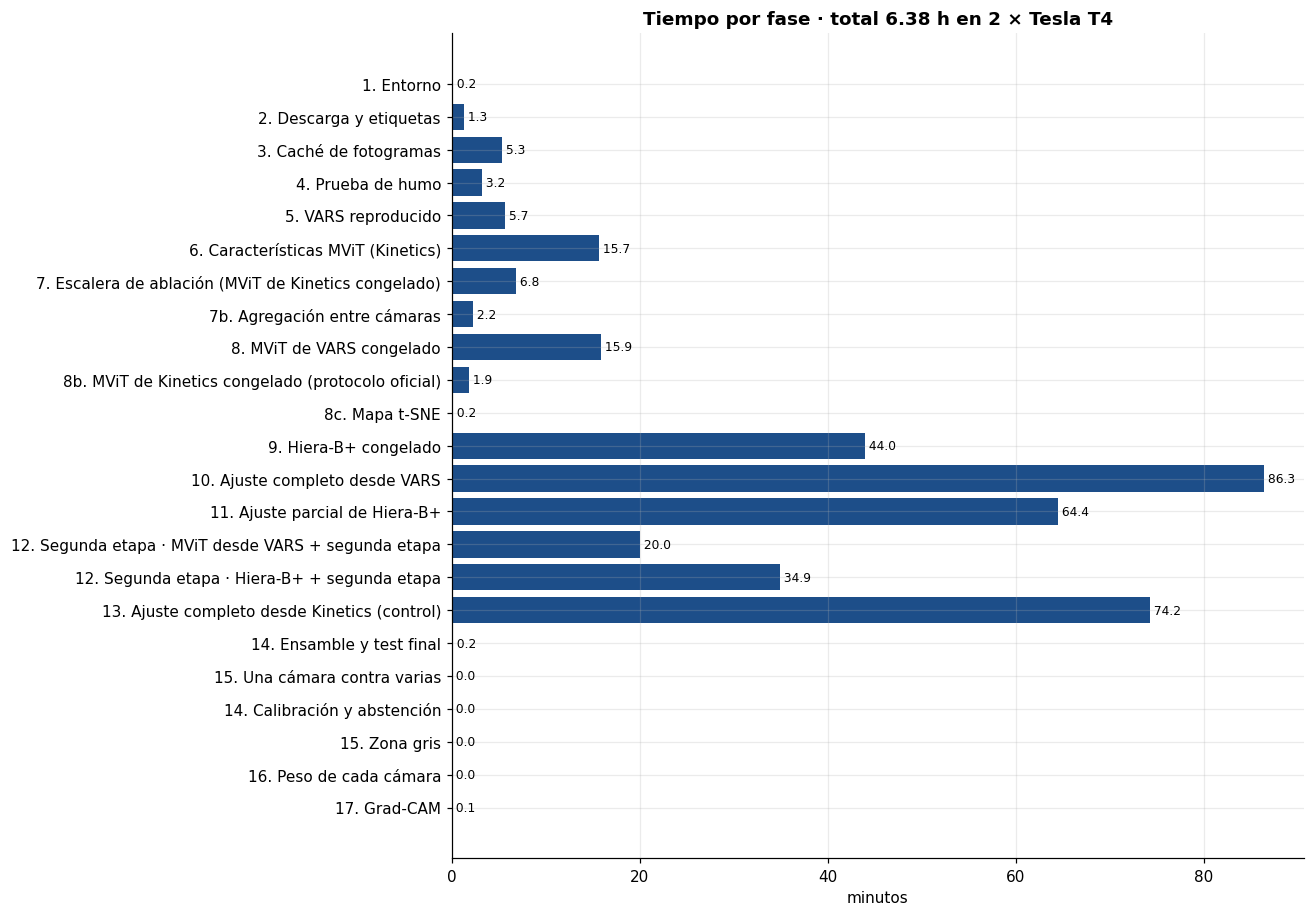

Listo en 6.38 h. Archivos en /kaggle/working/outputs:
   figuras/01_clases.png  (0.1 MB)
   figuras/02_composicion.png  (0.0 MB)
   figuras/03_camaras.png  (0.1 MB)
   figuras/04a_jugada_ejemplo.png  (1.2 MB)
   figuras/04b_ventanas.png  (0.0 MB)
   figuras/05_grupos_validacion.png  (0.1 MB)
   figuras/06_vars_reproducido.png  (0.1 MB)
   figuras/08_tsne_kinetics_vs_vars.png  (0.1 MB)
   figuras/09_curvas_cabeza.png  (0.2 MB)
   figuras/10_escalera_ablacion.png  (0.1 MB)
   figuras/11_agregacion.png  (0.0 MB)
   figuras/12_hiera_y_redes.png  (0.1 MB)
   figuras/13_transferencia.png  (0.1 MB)
   figuras/14_resultado_final.png  (0.1 MB)
   figuras/15_confusiones.png  (0.2 MB)
   figuras/16_una_vs_varias_camaras.png  (0.0 MB)
   figuras/17_calibracion_abstencion.png  (0.2 MB)
   figuras/18_zona_gris.png  (0.0 MB)
   figuras/19_peso_camaras.png  (0.1 MB)
   figuras/20_gradcam_jugada_1.png  (0.5 MB)
   figuras/20_gradcam_jugada_12.png  (0.6 MB)
   figuras/20_gradcam_jugada_2.png  (1.1 MB)
 

In [37]:
fases = pd.DataFrame([dict(fase=k, minutos=v['min'], ok=v['ok']) for k, v in REPORTE['fases'].items()])
fig, ax = plt.subplots(figsize=(10, 0.38 * len(fases) + 1))
ax.barh(fases.fase, fases.minutos, color=[COL['azul'] if o else COL['rojo'] for o in fases.ok])
for i, m in enumerate(fases.minutos):
    ax.text(m, i, f' {m:.1f}', va='center', fontsize=8)
ax.invert_yaxis(); ax.set_xlabel('minutos')
ax.set_title(f'Tiempo por fase · total {minutos() / 60:.2f} h en {N_GPU} × {REPORTE["entorno"].get("gpus", ["?"])[0] if N_GPU else "CPU"}')
guardar_fig(fig, '21_tiempos')

# ---------- Resumen en JSON (métricas de todos los experimentos) ----------
resumen = {'entorno': REPORTE['entorno'], 'activos': ACTIVO, 'ventana_hiera': ESQ_HIERA, 'features': INFO_FEATS,
           'vars_paper': VARS_PAPER, 'avisos': REPORTE['avisos'], 'experimentos': {}}
for k, r in RES.items():
    if isinstance(r, dict):
        resumen['experimentos'][k] = {c: r[c] for c in ('nombre', 'receta', 'tau', 'oof', 'oof_tau', 'oof_folds', 'test', 'test_tau',
                                                         'va', 'va_tau', 'min', 'mejor_ep', 'oficial', 'miembros', 'T_act', 'T_sev',
                                                         'n_entrenables', 'lote_final') if c in r}
        if 'hist' in r:
            resumen['experimentos'][k]['curvas'] = r['hist']
for k in ('abstencion', 'zona_gris'):
    if k in RES:
        resumen[k] = RES[k]
guardar_json(resumen, OUT / 'resultados.json')

# ---------- Pesos del mejor modelo ajustado (para una demo posterior) ----------
for k in ('ft_vars', 'ft_hiera'):
    if k in RES:
        cod, cab = RES[k]['modelo']
        torch.save({'codificador': {a: b.half() for a, b in cod.state_dict().items()}, 'cabeza': cab.state_dict(),
                    'receta': RES[k]['receta'], 'esquema': RES[k]['esquema'], 'red': RES[k]['enc']}, OUT / f'{k}.pt')

guardar_json(REPORTE, OUT / 'reporte_corrida.json')
if TMP_EN_OUTPUTS:
    shutil.rmtree(TMP, ignore_errors=True)                   # los fotogramas no pueden quedar en los outputs (NDA)
print(f'Listo en {minutos() / 60:.2f} h. Archivos en {OUT}:')
for p in sorted(OUT.rglob('*')):
    if p.is_file():
        print(f'   {p.relative_to(OUT)}  ({p.stat().st_size / 1e6:.1f} MB)')

## 21. Conclusiones

**Lectura: tiempos.** La corrida tomó **6,4 h de las 11 disponibles**. Lo más caro fueron los tres ajustes finos (86, 64 y 74 min) y la extracción de Hiera (44 min). Quedaron unas 4,6 h sin usar.

### Pregunta 1 · Verificar el punto de partida
- **La cifra de VARS se sostiene** y hasta mejora: con sus pesos públicos da 39,9 en el test, contra 37,5 en su paper. La métrica oficial de SoccerNet da el mismo número que la implementada aquí.
- Por eso la comparación justa es contra 39,9 y no contra 37,5.

### Pregunta 2 · Qué aporta la transferencia
- **Preentrenar es indispensable:** desde cero, R(2+1)D llegó a 20,0 (pruebas preliminares). Con redes preentrenadas congeladas se llega a 31–36.
- **Afinar siempre suma:** +4,4 desde Kinetics, +2,1 desde VARS y +3,1 en Hiera con ajuste parcial.
- **El punto de partida importa más que la técnica:** el MViT de VARS **congelado** (36,1) ya le gana al MViT de Kinetics **afinado** (35,4). Transferir de una tarea cercana (faltas) vale más que de una general (acciones de Kinetics).
- **El mejor codificador fue Hiera-B+** (autoencoder enmascarado + Kinetics), con la segunda etapa del ganador de SoccerNet 2025: **39,8**.
- **Sirvieron** el transformer entre cámaras con embedding de cámara (+2,0) y las jugadas de zona gris como etiquetas suaves (+2,3).
- **No sirvieron** los atributos del árbitro como tareas extra (−1,0) ni la sanción ordinal (−1,6).
- **Contra VARS reproducido:** empate (39,8 contra 39,9; diferencia entre −8,6 y +8,1). Hiera es mejor en la sanción (BA 38,3 contra 35,9) y peor en el tipo de falta (41,2 contra 43,9). Con 251 jugadas y 5 rojas, el test no alcanza para separar modelos que difieran en menos de unos 8 puntos.

### Pregunta 3 · Cuándo confiar y dónde falla
- **Calibración:** con temperatura, la confianza de la sanción se vuelve honesta (ECE 9,9 → 3,6).
- **Abstención:** respondiendo en el 68 % de las jugadas, la sanción sube de 51,4 % a 59,1 %. Es el uso más realista: un filtro que deja las jugadas dudosas al árbitro.
- **Dónde falla:**
  - no reconoce ninguna roja (0 de 5);
  - confunde disputa, empujón y codazo;
  - toma las simulaciones por entradas;
  - en la sanción casi siempre se equivoca hacia la clase vecina.
- **Cámaras:** las repeticiones valen más que la toma en vivo (40,6 contra 33,1), y el modelo aprendió solo a darles más peso.
- **No duda donde dudó el árbitro** (AUROC 0,44): esa parte no se logró.

### Limitaciones
1. **El desbalance se corrige dos veces.** La pérdida ya está ponderada por clase y encima se aplica el ajuste τ, que está pensado para pérdidas sin ponderar. Esto sobrecorrige: con τ, la exactitud del tipo de falta cae a 13–20 % en varios modelos, y en VARS + segunda etapa el test baja de 38,4 a 32,0. Una sola de las dos correcciones habría sido suficiente.
2. **Valid es demasiado pequeña para escoger** (3 rojas, 1 simulación). Con ella se escogieron la época, τ, la temperatura y el ensamble, y por eso valid dio 53,0 contra 39,8 en el test. Una alternativa es parar según la pérdida (más estable que la BA) y fijar el ensamble de antemano. Un candidato era VARS + Hiera, porque se complementan: VARS es mejor en el tipo de falta y Hiera en la sanción.
3. **Sobraron 4,6 h de cómputo,** que podrían dedicarse a más semillas de Hiera o a afinar todos sus bloques.
4. **Las probabilidades no se guardaron,** así que los ensambles y τ no se pueden revisar sin volver a correr todo.
5. **El análisis de la zona gris se hizo con el modelo más débil,** y el Grad-CAM salió plano.
6. **Recorte central:** el modelo ve un cuadrado de 224 de un cuadro de 398 × 224 y pierde los costados. El ganador de 2025 usó 720p.
7. **Sin cambio de dominio:** el test es del mismo dataset (ligas europeas). No mide cómo le iría en otra liga ni con otra transmisión.

### En una frase
Con aprendizaje por transferencia y el cómputo gratuito de Kaggle se **iguala al sistema publicado (VARS)** y se le gana en la sanción. Lo más útil no es el número: es saber **qué transferir** (una red que ya vio faltas), **cuánto afinar** y **cuándo no confiar** en el modelo.

## Referencias

**Dataset y punto de partida**
- Held, J., Cioppa, A., Giancola, S., Hamdi, A., Ghanem, B. y Van Droogenbroeck, M. (2023). *VARS: Video Assistant Referee System for Automated Soccer Decision Making from Multiple Views.* CVPR Workshops, 5086–5097. arXiv:2304.04617. (Presenta SoccerNet-MVFoul.)
- Held, J., Cioppa, A., Giancola, S., Hamdi, A., Devue, C., Ghanem, B. y Van Droogenbroeck, M. (2024). *Towards AI-Powered Video Assistant Referee System (VARS) for Association Football.* arXiv:2407.12483.
- Giancola, S., Cioppa, A. et al. (2025). *SoccerNet 2025 Challenges Results.* arXiv:2508.19182. (Resultados del reto de reconocimiento de faltas, incluida la segunda etapa del ganador.)
- Código y pesos de VARS: https://github.com/SoccerNet/sn-mvfoul

**Redes preentrenadas**
- Kay, W. et al. (2017). *The Kinetics Human Action Video Dataset.* arXiv:1705.06950.
- Li, Y., Wu, C.-Y., Fan, H., Mangalam, K., Xiong, B., Malik, J. y Feichtenhofer, C. (2022). *MViTv2: Improved Multiscale Vision Transformers for Classification and Detection.* CVPR.
- Ryali, C., Hu, Y.-T., Bolya, D., Wei, C., Fan, H., Huang, P.-Y. et al. (2023). *Hiera: A Hierarchical Vision Transformer without the Bells-and-Whistles.* ICML.
- He, K., Chen, X., Xie, S., Li, Y., Dollár, P. y Girshick, R. (2022). *Masked Autoencoders Are Scalable Vision Learners.* CVPR.
- Tran, D., Wang, H., Torresani, L., Ray, J., LeCun, Y. y Paluri, M. (2018). *A Closer Look at Spatiotemporal Convolutions for Action Recognition.* CVPR. (R(2+1)D)
- He, K., Zhang, X., Ren, S. y Sun, J. (2016). *Deep Residual Learning for Image Recognition.* CVPR. (ResNet)
- Tong, Z., Song, Y., Wang, J. y Wang, L. (2022). *VideoMAE: Masked Autoencoders are Data-Efficient Learners for Self-Supervised Video Pre-Training.* NeurIPS.

**Técnicas de entrenamiento y evaluación**
- Kumar, A., Raghunathan, A., Jones, R., Ma, T. y Liang, P. (2022). *Fine-Tuning can Distort Pretrained Features and Underperform Out-of-Distribution.* ICLR. (LP-FT)
- Shi, X., Cao, W. y Raschka, S. (2023). *Deep Neural Networks for Rank-Consistent Ordinal Regression Based on Conditional Probabilities.* Pattern Analysis and Applications. (CORN)
- Menon, A. K., Jayasumana, S., Rawat, A. S., Jain, H., Veit, A. y Kumar, S. (2021). *Long-tail Learning via Logit Adjustment.* ICLR.
- Guo, C., Pleiss, G., Sun, Y. y Weinberger, K. Q. (2017). *On Calibration of Modern Neural Networks.* ICML.
- Geifman, Y. y El-Yaniv, R. (2017). *Selective Classification for Deep Neural Networks.* NeurIPS.
- Peterson, J. C., Battleday, R. M., Griffiths, T. L. y Russakovsky, O. (2019). *Human Uncertainty Makes Classification More Robust.* ICCV.
- Selvaraju, R. R., Cogswell, M., Das, A., Vedantam, R., Parikh, D. y Batra, D. (2017). *Grad-CAM: Visual Explanations from Deep Networks via Gradient-based Localization.* ICCV.